# COMP0245: golden dataset experiments

This notebook starts from the frozen 300-target dataset and its 200 camera traces. It carries forward the three freshly trained baselines, iterations 34–36, as the starting point for the next experiments. The complete earlier notebook, `driving_v2_sensors.ipynb`, is preserved unchanged.

Re-running this notebook reads and plots saved results. It does not retrain models or run the simulator. Test results below are loaded from saved evaluations. The full data package is on university OneDrive; this repository contains its manifests and a small, explicitly labelled training preview. Use `GOLDEN_DATA_ROOT` for the location of the extracted package when running the training commands in `../arm/GOLDEN_DATA.md`.


In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
sys.path.insert(0, str(Path('../arm').resolve()))
import report_golden as golden
from report_golden import MODELS, RESULTS
GOLDEN_DATA_ROOT = Path(os.environ['GOLDEN_DATA_ROOT']).expanduser() if os.environ.get('GOLDEN_DATA_ROOT') else None
print('Full dataset:', GOLDEN_DATA_ROOT if GOLDEN_DATA_ROOT else 'not configured; saved manifests, preview and results remain available')
from IPython.display import IFrame, HTML
import uuid

def lazy_player(url, height=810):
    """A 3D player that loads only when its button is pressed. Browsers keep only about 16 3D views (WebGL
    contexts) at once, so loading every player in the notebook together leaves some of them blank."""
    k = uuid.uuid4().hex[:8]
    return HTML(f"""<div><button onclick="var f=document.getElementById('player{k}');f.src='{url}';f.style.display='block';this.style.display='none'"
 style="padding:8px 14px;font-size:14px">Load the 3D player</button>
<iframe id="player{k}" style="display:none;width:100%;height:{height}px;border:0"></iframe></div>""")


Full dataset: /media/nm/Fast Drive/comp0245-camera-11108/shared/COMP0245_Golden_300_2026-11-04


## Dataset and split

There are 100 training, 100 validation and 100 reserved test expert runs. Offline camera observations exist for training and validation. Test cameras were rendered live along each learned trajectory in ticket #11110, so expert test camera traces are not needed. Target IDs remain fixed across comparisons.


In [2]:
split = golden.read(MODELS/'dataset_split.json')
manifest = golden.read(MODELS/'dataset_manifest.json')
audit = pd.DataFrame(golden.read(MODELS/'data_audit.json')['rows'])
assert all(len(set(v)) == 100 for v in split.values())
assert len(set().union(*map(set, split.values()))) == 300
display(pd.DataFrame([dict(split=k, expert_runs=len(v), offline_camera_runs=0 if k=='test' else len(v), role={'train':'fit weights and learned scaling','val':'choose epochs and run integration checks','test':'final evaluation only'}[k]) for k,v in split.items()]))
display(audit.groupby('split').agg(runs=('dot','count'),driving_rows=('drive_rows','sum'),arm_rows=('arm_rows','sum'),parked_tail_min=('parked_rows','min'),parked_tail_max=('parked_rows','max')))
print('Frozen split SHA256:', golden.read(MODELS/'data_audit.json')['split_sha256'])

,split,expert_runs,offline_camera_runs,role
0,train,100,100,fit weights and learned scaling
1,val,100,100,choose epochs and run integration checks
2,test,100,0,final evaluation only


,runs,driving_rows,arm_rows,parked_tail_min,parked_tail_max
split,,,,,
train,100,25928,295084,30,100
val,100,26428,288818,13,100


Frozen split SHA256: 286f578aec7e3ab0953592466e63014cc1dde7f467106fadf273b30762ac1abf


## Model inputs and training targets

Driving has 16 inputs: four accumulated encoder angles, four encoder speeds, four combinations of those readings, and camera-tracked range/sin bearing/cos bearing/visibility. Reaching has 17 inputs: seven arm encoder angles, seven encoder speeds and camera-tracked target xyz in the robot frame. Values become FP32 tensors. The camera runs at 30 Hz; its latest estimate is held between arm steps at 1 kHz.

Training targets are the expert wheel-speed and arm-torque commands, normalized time to PARK and normalized gripper distance for STOP. Simulator truth is permitted for labels and scoring; it is not fed into the learned policies.

The existing simulator retains its PD-plus-model-gravity arm hold while driving. After PARK, the learned torque network controls the arm, including the 0.5 s following STOP. That fixed pre-PARK holding controller is part of this baseline and is not a learned sensor-only arm controller. STOP does not freeze physics.


In [3]:
preview = dict(np.load(MODELS/'training_preview.npz', allow_pickle=False))
wheel_names = [f'wheel_angle_{j}_rad' for j in range(1,5)] + [f'wheel_speed_{j}_rad_s' for j in range(1,5)] + ['mean_turn_rad','right_minus_left_turn_rad','mean_speed_rad_s','right_minus_left_speed_rad_s']
drive_names = wheel_names + ['tracked_range_m','tracked_bearing_sin','tracked_bearing_cos','visible']
arm_names = [f'arm_angle_{j}_rad' for j in range(1,8)] + [f'arm_speed_{j}_rad_s' for j in range(1,8)] + ['tracked_dot_x_m','tracked_dot_y_m','tracked_dot_z_m']
print('Preview only: training target', int(preview['dot']), '; five source rows per phase, not the whole dataset.')
display(pd.DataFrame(preview['driving_x'], columns=drive_names).assign(step=preview['drive_steps']).set_index('step'))
display(pd.DataFrame(preview['arm_x'], columns=arm_names).assign(step=preview['arm_steps']).set_index('step'))
print('Input types:', preview['driving_x'].dtype, preview['arm_x'].dtype)

Preview only: training target 0 ; five source rows per phase, not the whole dataset.


,wheel_angle_1_rad,wheel_angle_2_rad,wheel_angle_3_rad,wheel_angle_4_rad,wheel_speed_1_rad_s,wheel_speed_2_rad_s,wheel_speed_3_rad_s,wheel_speed_4_rad_s,mean_turn_rad,right_minus_left_turn_rad,mean_speed_rad_s,right_minus_left_speed_rad_s,tracked_range_m,tracked_bearing_sin,tracked_bearing_cos,visible
step,,,,,,,,,,,,,,,,
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.0,0.0,0.0,0.0
33,-0.090505,0.088971,0.090505,-0.092039,-2.715146,2.669127,2.715146,-2.761165,-0.000767,-0.181010,-0.02301,-5.430292,0.0,0.0,0.0,0.0
67,-0.181010,0.179476,0.185612,-0.187146,-2.715146,2.715146,2.853204,-2.853204,-0.000767,-0.366621,0.00000,-5.568350,0.0,0.0,0.0,0.0
100,-0.268447,0.266913,0.277651,-0.279184,-2.623107,2.623107,2.761165,-2.761165,-0.000767,-0.546097,0.00000,-5.384273,0.0,0.0,0.0,0.0
133,-0.354350,0.352816,0.369689,-0.371223,-2.577088,2.577088,2.761165,-2.761165,-0.000767,-0.724039,0.00000,-5.338253,0.0,0.0,0.0,0.0


,arm_angle_1_rad,arm_angle_2_rad,arm_angle_3_rad,arm_angle_4_rad,arm_angle_5_rad,arm_angle_6_rad,arm_angle_7_rad,arm_speed_1_rad_s,arm_speed_2_rad_s,arm_speed_3_rad_s,arm_speed_4_rad_s,arm_speed_5_rad_s,arm_speed_6_rad_s,arm_speed_7_rad_s,tracked_dot_x_m,tracked_dot_y_m,tracked_dot_z_m
step,,,,,,,,,,,,,,,,,
6230,-0.014631,1.515667,0.000216,1.014285,-0.006637,1.000131,-0.001473,-0.107379,0.006818,0.049428,0.001704,-0.081812,0.000000,0.029750,0.42766,-0.034332,1.238958
6231,-0.014738,1.515657,0.000269,1.014328,-0.006721,1.000200,-0.001448,-0.107379,-0.010227,0.052837,0.042611,-0.084291,0.069417,0.024792,0.42766,-0.034332,1.238958
6232,-0.014849,1.515638,0.000320,1.014396,-0.006803,1.000322,-0.001423,-0.110788,-0.018749,0.051133,0.068177,-0.081812,0.121479,0.024792,0.42766,-0.034332,1.238958
6233,-0.014963,1.515610,0.000373,1.014485,-0.006885,1.000483,-0.001401,-0.114196,-0.027271,0.052837,0.088630,-0.081812,0.161145,0.022312,0.42619,-0.038042,1.239363
6234,-0.015081,1.515576,0.000424,1.014587,-0.006966,1.000674,-0.001376,-0.117605,-0.034088,0.051133,0.102265,-0.081812,0.190895,0.024792,0.42619,-0.038042,1.239363


Input types: float32 float32


In [4]:
display(pd.DataFrame(preview['driving_commands'], columns=[f'expert_wheel_{j}_rad_s' for j in range(1,5)]).assign(time_to_park_scaled=preview['driving_ttp'],step=preview['drive_steps']).set_index('step'))
display(pd.DataFrame(preview['arm_commands'], columns=[f'expert_torque_{j}_Nm' for j in range(1,8)]).assign(stop_distance_scaled=preview['arm_stop_target'],step=preview['arm_steps']).set_index('step'))

,expert_wheel_1_rad_s,expert_wheel_2_rad_s,expert_wheel_3_rad_s,expert_wheel_4_rad_s,time_to_park_scaled
step,,,,,
0,-3.0,3.0,3.0,-3.0,1.0
33,-3.0,3.0,3.0,-3.0,1.0
67,-3.0,3.0,3.0,-3.0,1.0
100,-3.0,3.0,3.0,-3.0,1.0
133,-3.0,3.0,3.0,-3.0,1.0


,expert_torque_1_Nm,expert_torque_2_Nm,expert_torque_3_Nm,expert_torque_4_Nm,expert_torque_5_Nm,expert_torque_6_Nm,expert_torque_7_Nm,stop_distance_scaled
step,,,,,,,,
6230,5.316199,28.082699,-1.365561,-6.598114,3.302955,22.673250,-0.699793,1.0
6231,5.320834,28.591558,-1.470603,-7.839973,3.385210,20.551292,-0.551579,1.0
6232,5.459431,28.937777,-1.435724,-8.689305,3.328572,19.007622,-0.613395,1.0
6233,5.542691,29.200615,-1.472973,-9.291978,3.338620,17.821453,-0.567547,1.0
6234,5.643270,29.394722,-1.480658,-9.713266,3.327830,16.905899,-0.562102,1.0


## Frozen models

Training finished under ticket 11109. Validation chose the checkpoints; ticket 11110 evaluates these unchanged models on the reserved test targets.


### Golden data: driving and reaching, three seeds (iterations 34 to 36)

#### Iterations 34 to 36: plan and expected results

Written before training. Ticket #11109 follows the 4 November roadmap: retrain the iteration 13 driving architecture and iteration 27 reaching architecture on 100 training runs, choose epochs on 100 validation runs, and reserve the 100 test runs for ticket #11110. Seeds 7, 1 and 2 are iterations 34, 35 and 36 respectively. Earlier notebook results stay unchanged.

Driving uses 16 encoder/camera inputs at 30 Hz, two 16-unit ReLU layers, four wheel-speed outputs and a separate time-to-PARK head. The target is seconds to the recorded PARK, clipped at 3 s and divided by 3; the PARK threshold remains 0.25 s. The loss is wheel-speed MSE plus normalized time-to-PARK MSE, with each run weighted equally. Include at most 100 available, real parked frames after PARK. Fit the six angle-feature scales on training only.

Reaching uses 17 inputs at 1 kHz: seven encoder angles, seven encoder speeds and camera/tracker xyz, held between camera frames. Its torque path has two 64-unit ReLU layers and seven torque outputs; the independent stop network is 17 -> 32 -> 16 -> 1. Preserve the inherited auxiliary distance loss when training the torque path; the independent stop network supplies runtime STOP. Both distance targets use the aligned expert distance, clipped at 0.25 m and divided by 0.25; STOP remains 10 mm. Each run has equal weight. Encoder resolutions, fixed input scales and runtime clipping remain unchanged.

Every network starts from fresh weights. Use FP32, Adam at 0.01, up to 300 epochs for driving/torques and 600 for independent stop. Select the lowest declared validation objective and restore that checkpoint. Any chunking accumulates the same full-batch gradient before one optimizer update. Validate exported NumPy predictions against PyTorch before simulation.

Expected result: validation losses should fall below their epoch-zero values, and the broader range of target heights should reduce the single-height behaviour seen in iteration 30. This is a hypothesis, not a claimed result. It is contradicted if validation does not improve, or if recorded validation reaches continue to converge to one height regardless of the camera estimate. A lower offline loss alone does not establish successful parking or reaching.

Use a fixed validation subset, selected before training, for integration smoke checks. The expert is only a recorded reference/ghost. Report every seed, camera visibility, PARK, STOP, distance at STOP and timeouts; never tune against the reserved test runs. There is no PPO, weight perturbation, new CNN, DART or DAgger in this experiment.

Training status: all three seeds trained on the GPU in 87.7 seconds including loading and export checks. Test trajectories were not opened during training. Final test evaluation is recorded below.


### Official iterations 34 to 36: frozen 100-target test plan

Ticket 11110 evaluates seeds 7, 1 and 2 from ticket 11109 without retraining. Each seed attempts all 100 reserved test targets. Training and validation chose every checkpoint; representative seed 7 was fixed before simulation outcomes.

Success requires PARK, STOP and a true gripper-to-dot distance of at most 10 mm at the exact STOP step. Closest approach and drift during the following 0.5 seconds are reported separately. Without STOP, the deadline is expert completion plus 4 seconds. No PARK, no STOP and numerical failures remain in the denominator.

Camera and driving updates run at 30 Hz, reaching torques and arm encoders at 1 kHz. Inputs use encoders and the rendered camera/tracker. The original native PD-plus-model-gravity arm hold remains during driving. Encoder quantisation, camera error, robot model and limits remain unchanged; no added noise or dynamics effects.

The smoke checks below found no successful 10 mm stops, so the expectation is weak final reaching performance. This evaluation measures that baseline honestly; no test outcomes will be used to change the model or deadline. All 300 attempts, per-seed Wilson intervals, training loss histories and test replays will be reported. The old validation-only MLflow entries are archived; the official test runs use iterations 34 to 36.


### Validation smoke checks

Ten predetermined validation targets per seed, used only to check integration. These are not official test results or numbered MLflow runs. The full saved records remain available; no validation animations are loaded here.


In [5]:
smoke = json.loads((RESULTS / 'summary.json').read_text())
smoke_df = pd.DataFrame([{'seed': s, 'attempts': len(rs), 'PARK': sum(r['parked'] for r in rs), 'STOP': sum(r['stop_s'] is not None for r in rs), 'within_10mm_at_STOP': sum(r['parked'] and r['at_network_stop_mm'] is not None and r['at_network_stop_mm'] <= 10 for r in rs)} for s in (7, 1, 2) for rs in [[r for r in smoke if r['seed'] == s]]])
display(smoke_df)


,seed,attempts,PARK,STOP,within_10mm_at_STOP
0,7,10,4,4,0
1,1,10,10,7,0
2,2,10,10,9,0


## Full test: 100 targets for each seed

The same 100 reserved targets are tested for seeds 7, 1 and 2. Each attempt starts from reset with learned driving and reaching. All attempted targets stay in the score, including missing PARK, missing STOP and execution failures. Training and validation chose the models before these outcomes. Seed 7 remains the representative.

The table reports the three seeds separately. They share targets, so the 300 attempts are not 300 independent target samples. Median parking error is conditional on PARK; median STOP distance is conditional on STOP. The success denominator is always 100.


In [6]:
import report_test_golden as test_report
completion = golden.read(test_report.RESULTS / 'completion.json')
assert completion['all_accounted'] and completion['attempts'] == 300
scores = pd.DataFrame([test_report.score(s) for s in (7, 1, 2)]).set_index('seed')
display(scores.round(2))
print(f"Active simulation time: {completion['elapsed_s']/60:.1f} minutes across both execution segments; paused time excluded.")
print(f"Resumed segment: {completion['resumed_elapsed_s']/60:.1f} minutes, with {completion['restored']} earlier attempts retained.")


,attempts,parked,stopped,success_10mm,success_percent,wilson95_low_percent,wilson95_high_percent,median_park_error_cm,median_abs_heading_error_deg,median_closest_mm,median_stop_mm,median_park_s,median_stop_s,timeouts,execution_failures,sum_case_wall_s,median_case_wall_s
seed,,,,,,,,,,,,,,,,,
7,100,47,47,0,0.0,0.0,3.7,27.30,14.25,295.83,400.42,5.00,6.47,53,0,1587.48,17.31
1,100,98,60,0,0.0,0.0,3.7,22.06,10.39,266.90,558.78,6.38,8.38,40,0,1735.64,17.78
2,100,96,81,0,0.0,0.0,3.7,28.58,9.52,301.97,490.27,7.07,9.68,19,0,1727.51,17.79


Active simulation time: 19.9 minutes across both execution segments; paused time excluded.
Resumed segment: 11.4 minutes, with 65 earlier attempts retained.


### Rendering and execution checks

The full 256 × 256 fisheye RGB-D camera, five 192 × 192 faces, visibility/occlusion, 30 Hz camera/driving rate, 1 kHz physics/torque rate and all frozen policy settings were preserved. Constant fisheye pixel mappings are cached. During driving, the native controller advances between camera updates; Python also reads the state one tick before each camera update to preserve the exact arm encoder velocity at PARK. After PARK, arm feedback remains at every millisecond.

Before resuming the test, six predetermined validation cases compared full RGB/depth/segmentation hashes, policy input/output hashes, every recorded trajectory state and event metrics. All matched exactly. The first 65 attempts were kept; the remaining 235 used six workers with these checked changes.


In [7]:
speed = golden.read(test_report.RESULTS / 'speed_parity.json')
assert speed['all_exact']
display(pd.DataFrame(speed['cases']).drop(columns=['counts']).round(3))
print('Full image and policy hashes are preserved in the speed-check evidence files.')


,seed,dot,reference_s,fast_s,exact_match
0,7,6,26.239,21.122,True
1,7,131,26.955,21.681,True
2,1,6,22.436,19.119,True
3,1,131,20.822,17.754,True
4,2,6,26.777,22.822,True
5,2,131,22.626,18.946,True


Full image and policy hashes are preserved in the speed-check evidence files.


### Iteration 34: golden data, seed 7, results

Official test evaluation of the frozen seed-7 models. The full table covers all 100 reserved targets. No retraining occurred during this evaluation.


In [8]:
display(HTML('<div style="max-height:420px;overflow:auto">'+test_report.table(7).round(3).to_html()+'</div>'))


,status,success,parked,park_s,stop_s,park_error_cm,park_heading_error_deg,at_stop_mm,closest_mm,end_mm,post_stop_drift_mm,post_park_base_drift_cm,timed_out,elapsed_s,camera_visible_fraction,target_bearing_deg,target_range_m,target_height_m
dot,,,,,,,,,,,,,,,,,,
11,stop_outside_10mm,False,True,3.933,6.730,45.628,-2.663,635.350,193.748,608.699,-26.651,0.737,False,11.595,1.000,0.986,1.042,0.178
17,no_park_timeout,False,False,NaN,NaN,NaN,NaN,NaN,NaN,3965.676,NaN,NaN,True,19.234,0.000,194.926,1.095,1.028
33,no_park_timeout,False,False,NaN,NaN,NaN,NaN,NaN,NaN,3531.837,NaN,NaN,True,18.582,0.000,259.736,1.504,0.422
35,no_park_timeout,False,False,NaN,NaN,NaN,NaN,NaN,NaN,3500.593,NaN,NaN,True,17.355,0.000,111.687,1.257,0.589
40,no_park_timeout,False,False,NaN,NaN,NaN,NaN,NaN,NaN,3937.136,NaN,NaN,True,18.220,0.000,205.751,1.041,0.328
43,no_park_timeout,False,False,NaN,NaN,NaN,NaN,NaN,NaN,3707.857,NaN,NaN,True,17.486,0.000,121.648,1.333,0.760
44,no_park_timeout,False,False,NaN,NaN,NaN,NaN,NaN,NaN,4646.997,NaN,NaN,True,20.226,0.000,140.983,1.684,0.533
48,stop_outside_10mm,False,True,7.833,10.131,40.860,-1.425,541.897,380.975,603.976,62.079,0.765,False,15.696,0.881,30.246,1.110,0.420
52,stop_outside_10mm,False,True,4.200,4.642,15.491,12.164,318.579,279.422,303.079,-15.501,0.565,False,8.993,0.735,315.534,1.244,1.090


#### Iteration 34: training and validation losses

Every saved epoch is shown. Solid lines are training losses; dashed lines are validation losses. Vertical markers identify the selected checkpoint. These are the original training histories, not losses fitted to the test results.


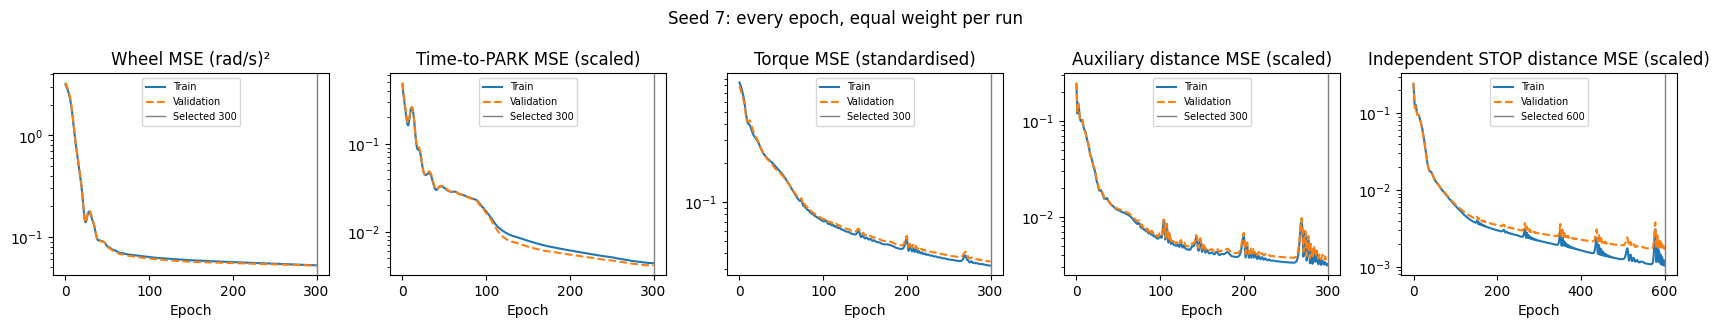

In [9]:
test_report.losses(7); plt.show()


#### Iteration 34: parking and reaching outcomes

All 100 outcomes are counted. Parking error is measured at the model and expert PARK events. Reaching is scored at the exact STOP step; closest approach is reported separately.


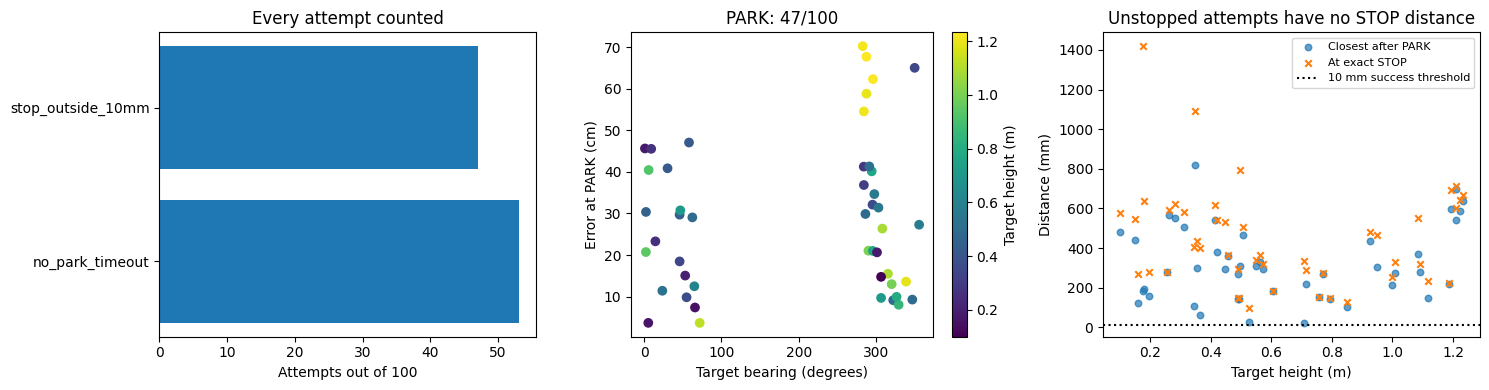

In [10]:
test_report.outcomes(7); plt.show()


#### Iteration 34: stopping and drift

These plots distinguish reaching the dot, issuing STOP in the right place, and subsequent movement. The camera visibility fraction comes from the recorded detector. Missing event measurements are left blank, while their attempts remain failures in the overall score.


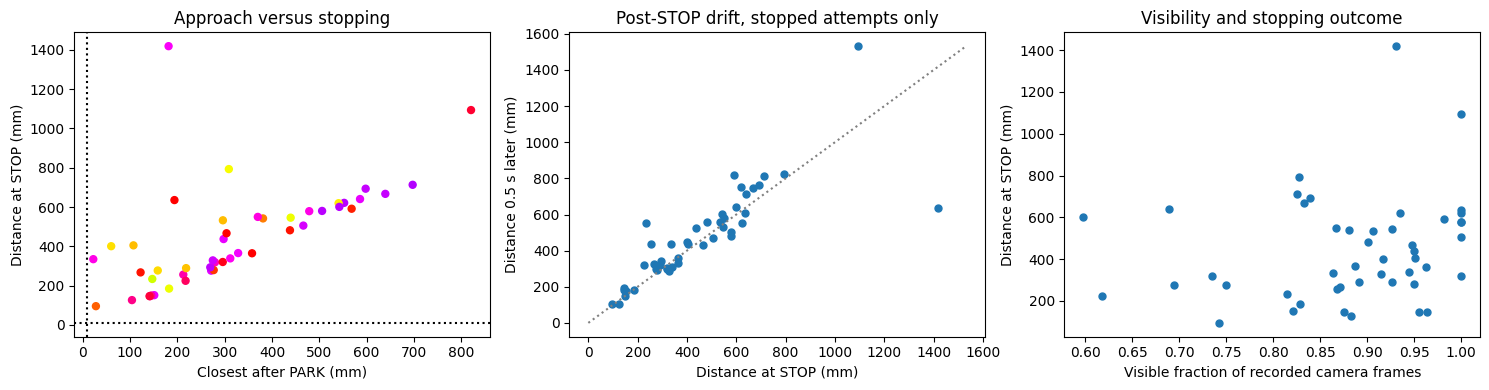

In [11]:
test_report.stopping(7); plt.show()


#### Iteration 34: predicted and actual distance over time

The first ten target IDs in the fixed test manifest are shown for readable traces, selected independently of outcomes. The table and player include all 100 targets. Actual distances are used for evaluation only; they are not network inputs.


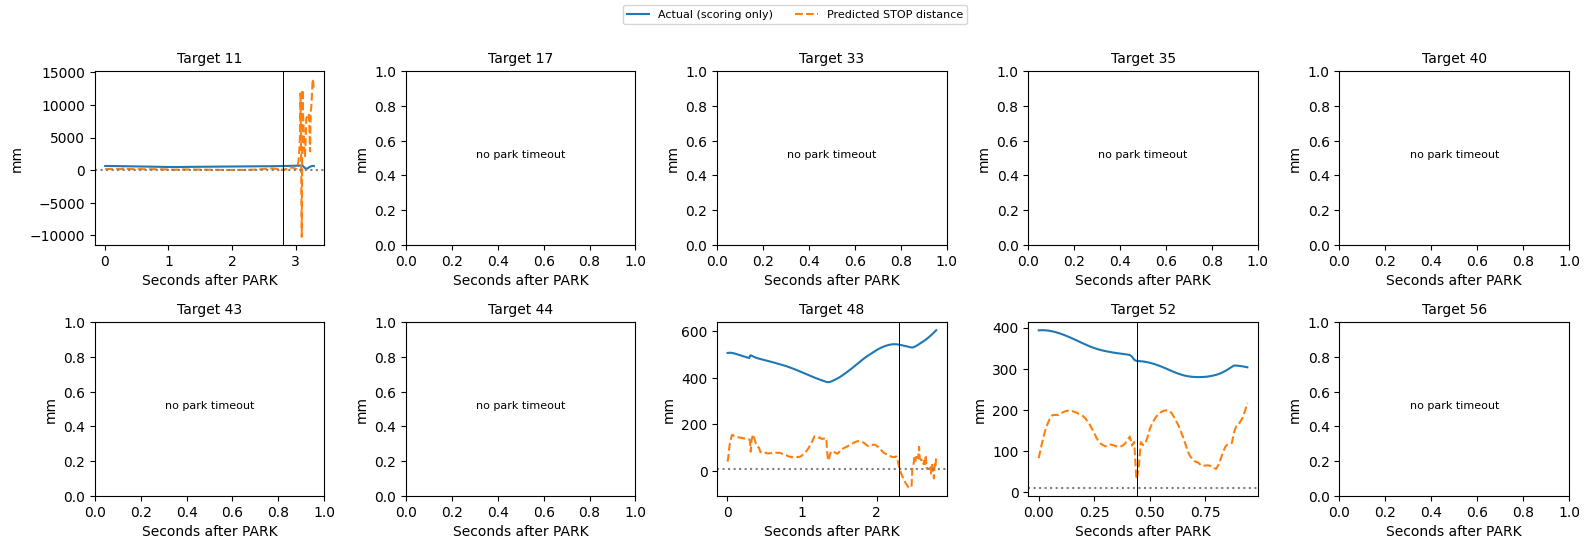

In [12]:
test_report.distances(7); plt.show()


#### Iteration 34: all test replays

Select any of the 100 recorded test targets. The solid robot follows the learned policy; the ghost follows the recorded expert. The upper-right camera inset shows actual recorded images. Play, pause, restart and the time slider control playback. Camera images load as needed to limit browser memory.


In [13]:
player_path = test_report.build_viewer(7)
player_url = test_report.preview_server() + '/' + player_path.name
display(lazy_player(player_url))
display(HTML(f'<a href="{player_url}" target="_blank">Open all 100 test replays in a separate tab</a>'))


#### Iteration 34: reading the result


In [14]:
display(Markdown(test_report.reading(7)))


Seed 7: 47/100 PARK, 47/100 STOP and 0/100 successful stops within 10 mm (Wilson 95% interval 0.0–3.7%). 0/100 came within 10 mm during reaching; passing through is not a successful stop. Median parking error was 27.3 cm among parked attempts; median distance at STOP was 400.4 mm among stopped attempts. 53 attempts timed out and 0 had execution/termination failures. These conditional medians exclude attempts without the relevant event; the success rate keeps all 100. This is a frozen baseline result, not a basis for selecting checkpoints. Representative seed 7 remains the validation-selected seed.

### Iteration 35: golden data, seed 1, results

Official test evaluation of the frozen seed-1 models. The full table covers all 100 reserved targets. No retraining occurred during this evaluation.


In [15]:
display(HTML('<div style="max-height:420px;overflow:auto">'+test_report.table(1).round(3).to_html()+'</div>'))


,status,success,parked,park_s,stop_s,park_error_cm,park_heading_error_deg,at_stop_mm,closest_mm,end_mm,post_stop_drift_mm,post_park_base_drift_cm,timed_out,elapsed_s,camera_visible_fraction,target_bearing_deg,target_range_m,target_height_m
dot,,,,,,,,,,,,,,,,,,
11,stop_outside_10mm,False,True,2.633,4.520,22.572,19.968,410.563,297.123,408.689,-1.874,1.379,False,9.185,0.987,0.986,1.042,0.178
17,no_stop_timeout,False,True,7.367,NaN,13.349,16.599,NaN,236.275,1128.734,NaN,3.943,True,19.052,0.682,194.926,1.095,1.028
33,stop_outside_10mm,False,True,5.633,9.069,8.248,13.004,425.545,96.087,998.686,573.141,1.960,False,15.939,0.906,259.736,1.504,0.422
35,no_stop_timeout,False,True,10.200,NaN,47.503,6.454,NaN,468.500,532.409,NaN,0.188,True,17.656,0.508,111.687,1.257,0.589
40,no_stop_timeout,False,True,6.633,NaN,17.528,20.830,NaN,267.001,406.636,NaN,1.549,True,19.739,0.779,205.751,1.041,0.328
43,no_stop_timeout,False,True,10.933,NaN,32.560,10.031,NaN,351.155,405.464,NaN,1.267,True,17.260,0.519,121.648,1.333,0.760
44,no_stop_timeout,False,True,10.233,NaN,54.503,8.700,NaN,613.677,923.565,NaN,3.504,True,20.755,0.655,140.983,1.684,0.533
48,stop_outside_10mm,False,True,4.300,6.740,14.262,-1.163,1014.756,153.960,1069.508,54.752,0.203,False,12.209,0.789,30.246,1.110,0.420
52,stop_outside_10mm,False,True,6.333,7.894,32.439,5.034,89.635,51.366,60.204,-29.431,1.268,False,13.475,0.937,315.534,1.244,1.090


#### Iteration 35: training and validation losses

Every saved epoch is shown. Solid lines are training losses; dashed lines are validation losses. Vertical markers identify the selected checkpoint. These are the original training histories, not losses fitted to the test results.


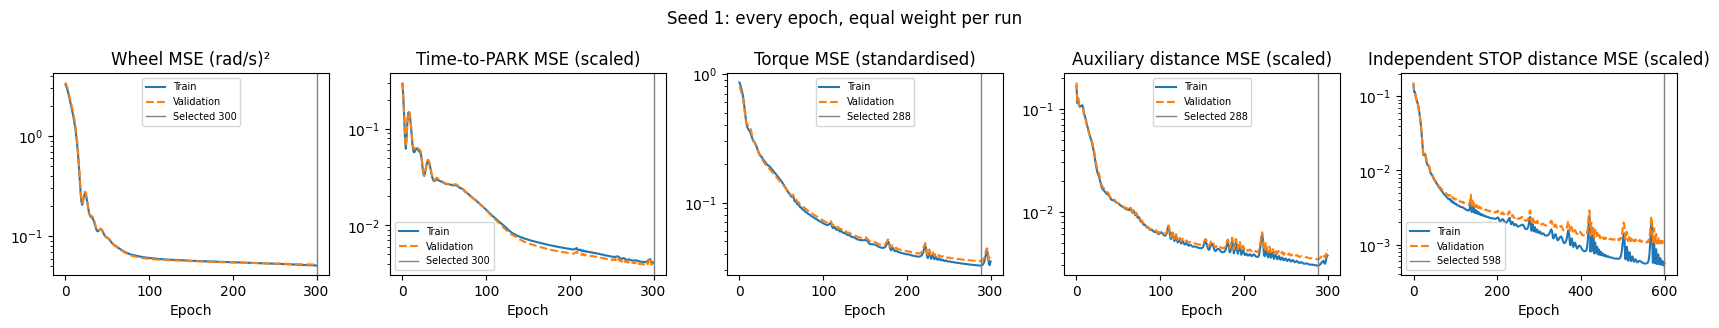

In [16]:
test_report.losses(1); plt.show()


#### Iteration 35: parking and reaching outcomes

All 100 outcomes are counted. Parking error is measured at the model and expert PARK events. Reaching is scored at the exact STOP step; closest approach is reported separately.


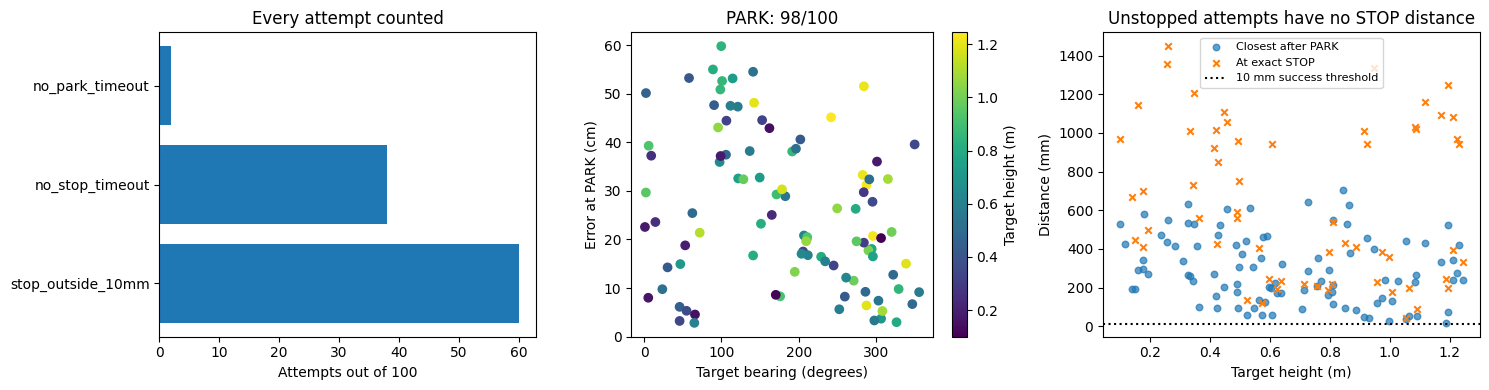

In [17]:
test_report.outcomes(1); plt.show()


#### Iteration 35: stopping and drift

These plots distinguish reaching the dot, issuing STOP in the right place, and subsequent movement. The camera visibility fraction comes from the recorded detector. Missing event measurements are left blank, while their attempts remain failures in the overall score.


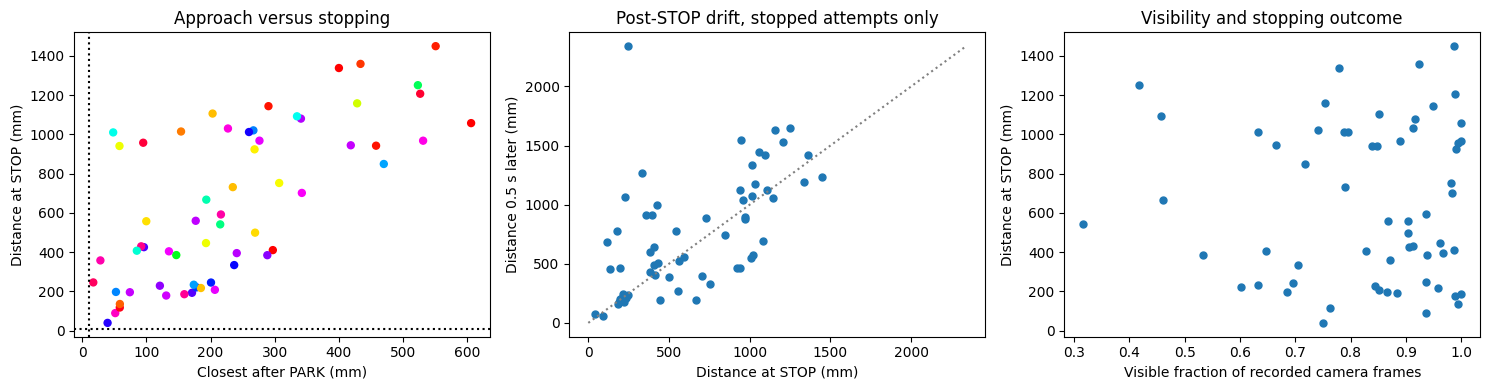

In [18]:
test_report.stopping(1); plt.show()


#### Iteration 35: predicted and actual distance over time

The first ten target IDs in the fixed test manifest are shown for readable traces, selected independently of outcomes. The table and player include all 100 targets. Actual distances are used for evaluation only; they are not network inputs.


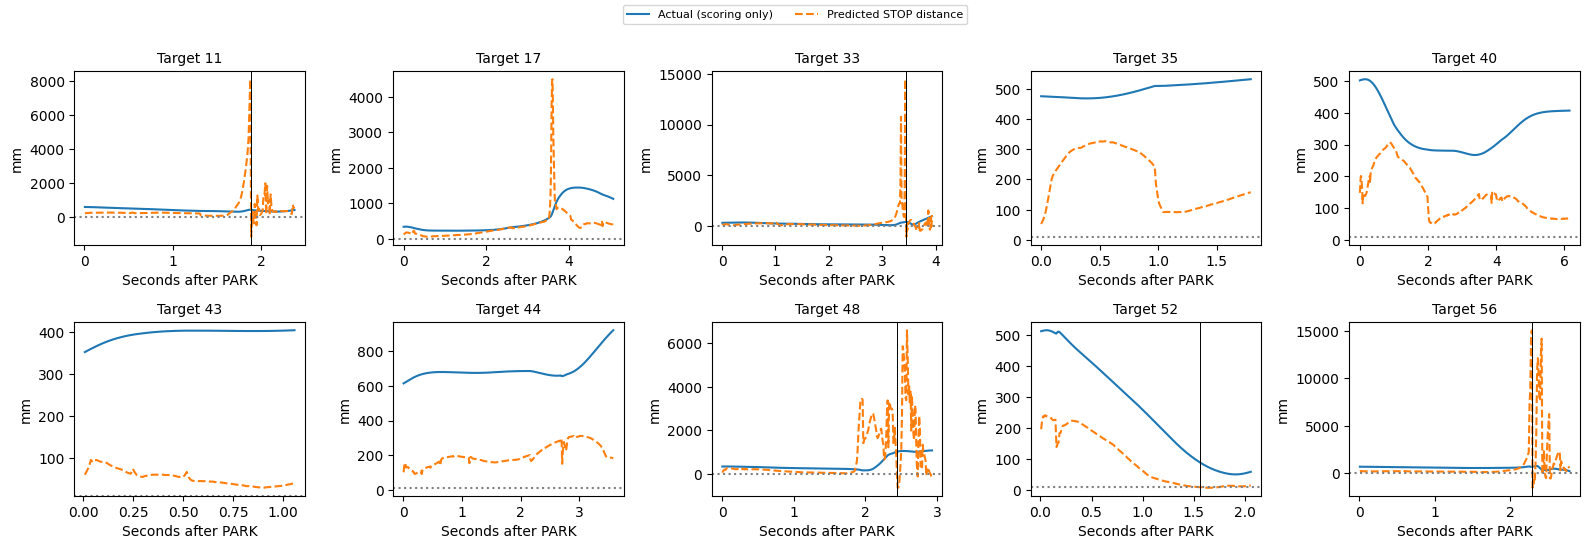

In [19]:
test_report.distances(1); plt.show()


#### Iteration 35: all test replays

Select any of the 100 recorded test targets. The solid robot follows the learned policy; the ghost follows the recorded expert. The upper-right camera inset shows actual recorded images. Play, pause, restart and the time slider control playback. Camera images load as needed to limit browser memory.


In [20]:
player_path = test_report.build_viewer(1)
player_url = test_report.preview_server() + '/' + player_path.name
display(lazy_player(player_url))
display(HTML(f'<a href="{player_url}" target="_blank">Open all 100 test replays in a separate tab</a>'))


#### Iteration 35: reading the result


In [21]:
display(Markdown(test_report.reading(1)))


Seed 1: 98/100 PARK, 60/100 STOP and 0/100 successful stops within 10 mm (Wilson 95% interval 0.0–3.7%). 0/100 came within 10 mm during reaching; passing through is not a successful stop. Median parking error was 22.1 cm among parked attempts; median distance at STOP was 558.8 mm among stopped attempts. 40 attempts timed out and 0 had execution/termination failures. These conditional medians exclude attempts without the relevant event; the success rate keeps all 100. This is a frozen baseline result, not a basis for selecting checkpoints. Representative seed 7 remains the validation-selected seed.

### Iteration 36: golden data, seed 2, results

Official test evaluation of the frozen seed-2 models. The full table covers all 100 reserved targets. No retraining occurred during this evaluation.


In [22]:
display(HTML('<div style="max-height:420px;overflow:auto">'+test_report.table(2).round(3).to_html()+'</div>'))


,status,success,parked,park_s,stop_s,park_error_cm,park_heading_error_deg,at_stop_mm,closest_mm,end_mm,post_stop_drift_mm,post_park_base_drift_cm,timed_out,elapsed_s,camera_visible_fraction,target_bearing_deg,target_range_m,target_height_m
dot,,,,,,,,,,,,,,,,,,
11,stop_outside_10mm,False,True,2.367,5.739,9.183,11.808,1070.808,112.180,570.852,-499.956,1.283,False,10.854,0.979,0.986,1.042,0.178
17,stop_outside_10mm,False,True,5.600,9.050,30.339,13.945,508.207,413.005,704.797,196.590,0.517,False,15.272,0.686,194.926,1.095,1.028
33,stop_outside_10mm,False,True,7.133,11.853,36.225,4.684,534.683,316.406,596.024,61.341,7.996,False,18.962,0.881,259.736,1.504,0.422
35,stop_outside_10mm,False,True,7.067,10.145,42.068,7.128,1626.615,417.772,1567.972,-58.643,1.031,False,16.718,0.625,111.687,1.257,0.589
40,stop_outside_10mm,False,True,5.400,7.739,15.442,11.870,271.810,63.110,342.378,70.567,0.300,False,13.837,0.629,205.751,1.041,0.328
43,no_stop_timeout,False,True,11.667,NaN,8.574,-21.285,NaN,185.418,185.326,NaN,0.139,True,17.397,0.569,121.648,1.333,0.760
44,stop_outside_10mm,False,True,9.267,12.695,42.746,-19.657,1168.125,462.752,1459.010,290.885,0.282,False,20.155,0.808,140.983,1.684,0.533
48,stop_outside_10mm,False,True,4.900,5.665,14.703,-16.214,273.143,266.617,319.793,46.650,1.525,False,10.342,0.946,30.246,1.110,0.420
52,stop_outside_10mm,False,True,5.967,9.637,25.878,5.426,1497.788,289.142,1712.692,214.904,1.886,False,15.829,0.649,315.534,1.244,1.090


#### Iteration 36: training and validation losses

Every saved epoch is shown. Solid lines are training losses; dashed lines are validation losses. Vertical markers identify the selected checkpoint. These are the original training histories, not losses fitted to the test results.


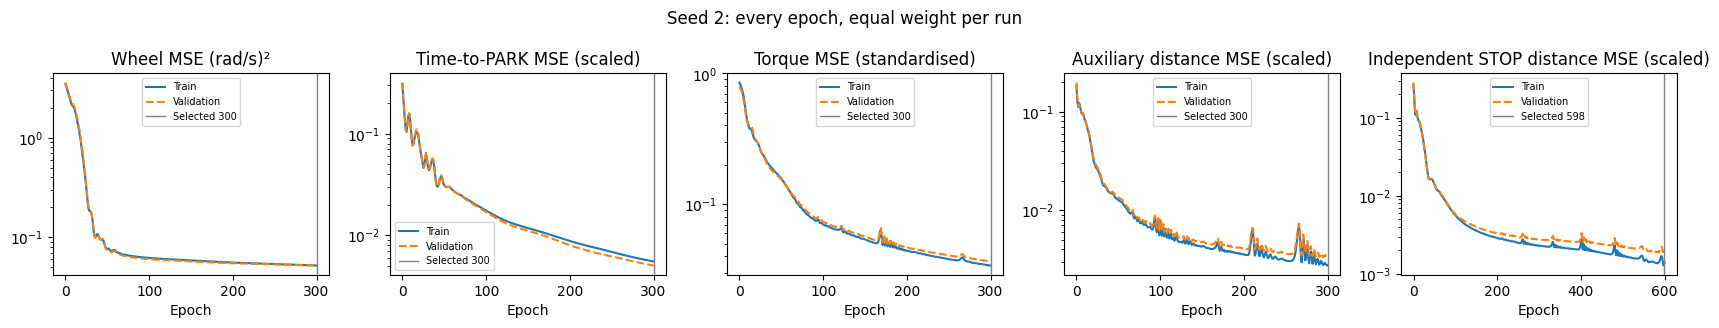

In [23]:
test_report.losses(2); plt.show()


#### Iteration 36: parking and reaching outcomes

All 100 outcomes are counted. Parking error is measured at the model and expert PARK events. Reaching is scored at the exact STOP step; closest approach is reported separately.


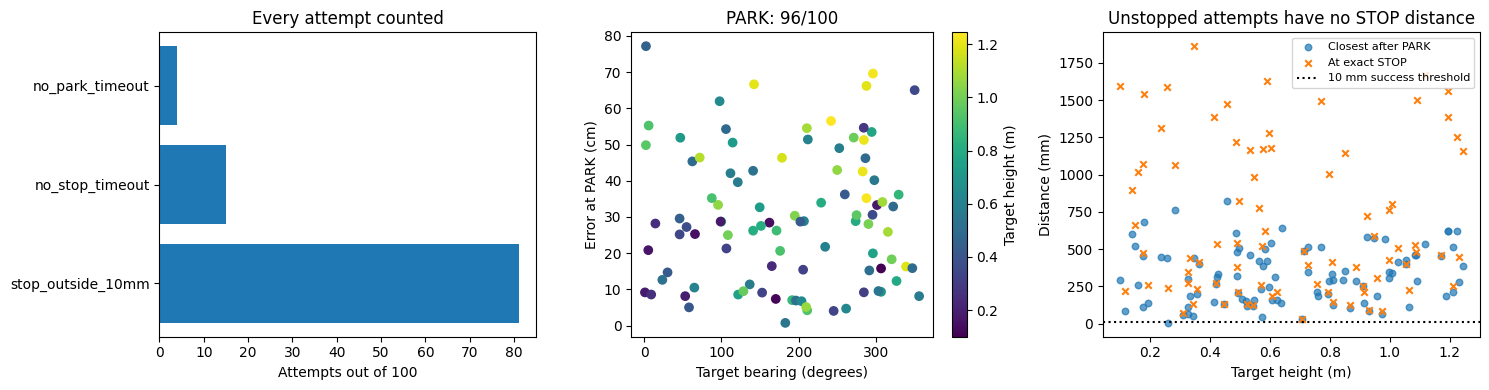

In [24]:
test_report.outcomes(2); plt.show()


#### Iteration 36: stopping and drift

These plots distinguish reaching the dot, issuing STOP in the right place, and subsequent movement. The camera visibility fraction comes from the recorded detector. Missing event measurements are left blank, while their attempts remain failures in the overall score.


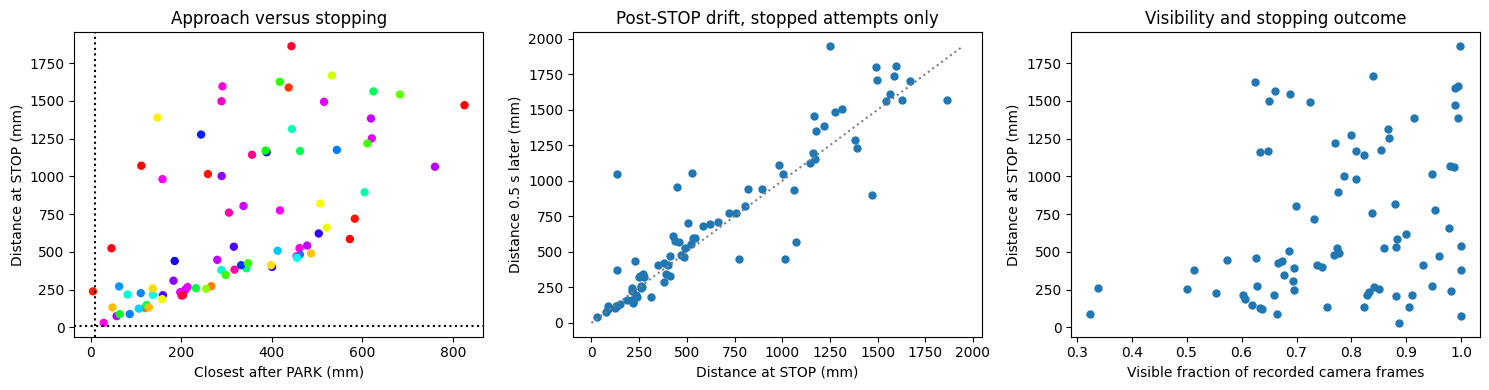

In [25]:
test_report.stopping(2); plt.show()


#### Iteration 36: predicted and actual distance over time

The first ten target IDs in the fixed test manifest are shown for readable traces, selected independently of outcomes. The table and player include all 100 targets. Actual distances are used for evaluation only; they are not network inputs.


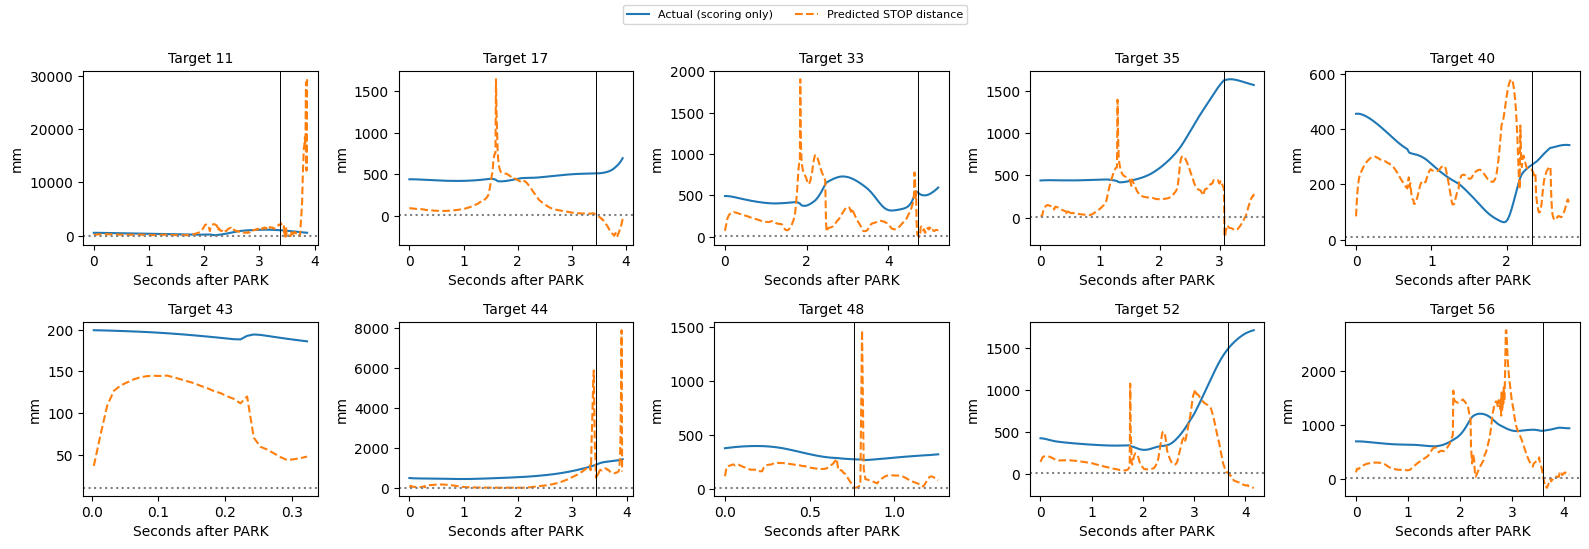

In [26]:
test_report.distances(2); plt.show()


#### Iteration 36: all test replays

Select any of the 100 recorded test targets. The solid robot follows the learned policy; the ghost follows the recorded expert. The upper-right camera inset shows actual recorded images. Play, pause, restart and the time slider control playback. Camera images load as needed to limit browser memory.


In [27]:
player_path = test_report.build_viewer(2)
player_url = test_report.preview_server() + '/' + player_path.name
display(lazy_player(player_url))
display(HTML(f'<a href="{player_url}" target="_blank">Open all 100 test replays in a separate tab</a>'))


#### Iteration 36: reading the result


In [28]:
display(Markdown(test_report.reading(2)))


Seed 2: 96/100 PARK, 81/100 STOP and 0/100 successful stops within 10 mm (Wilson 95% interval 0.0–3.7%). 1/100 came within 10 mm during reaching; passing through is not a successful stop. Median parking error was 28.6 cm among parked attempts; median distance at STOP was 490.3 mm among stopped attempts. 19 attempts timed out and 0 had execution/termination failures. These conditional medians exclude attempts without the relevant event; the success rate keeps all 100. This is a frozen baseline result, not a basis for selecting checkpoints. Representative seed 7 remains the validation-selected seed.

## Interpretation and next work

This completes the frozen baseline evaluation. Differences between seeds measure the variation from training on the same data. Future planned changes should be selected using training/validation, then evaluated on these same fixed test IDs. Test outcomes do not select a checkpoint or change a deadline.

The historical `driving_v2_sensors.ipynb` remains unchanged at 361 cells. Validation smoke checks are not official MLflow runs; iterations 34 to 36 contain the full tests and original training histories.


## Development iteration: camera height for driving

### Plan and expected results

Add one sensor input: tracked target height relative to the robot, in metres. Driving changes from 16 -> 16 -> 16 to 17 -> 16 -> 16, with the same four wheel-speed outputs and time-to-PARK head. All wheel-angle and speed inputs stay. Height comes from the existing camera/tracker, zero before first detection and held when temporarily hidden. There is no search rule or simulator-truth input.

Train only driving, from scratch with seed 7, on all 100 golden training runs; choose the checkpoint on all 100 validation runs. Keep FP32, Adam learning rate 0.01, 300 epochs, equal run weighting, existing angle scaling, wheel MSE and time-to-PARK MSE unchanged. Height stays in metres. The existing seed-7 reaching checkpoint is retained byte for byte.

Compare baseline and height models on the same six validation targets, selected before training by low/middle/high target height crossed with nearer/farther range. All are visible initially, so this checks approach and parking rather than unseen-target behaviour. Every episode starts normally and runs both learned networks through reaching. Full camera rendering, 30 Hz driving/camera, 1 kHz torque/physics and existing deadlines are unchanged. No camera videos or reserved-test evaluation are generated.

Prediction: lower median parking error, especially for low/high targets whose expert parking distance changes with height. Equal or worse paired parking error does not support improvement on this screen. Report every case, PARK/STOP counts, heading, closest reach and distance at STOP; six targets and one seed do not establish generalisation.

Frozen validation cases: 673, 506, 830, 720, 16, 333. Selection uses target metadata and initial visibility, never model outcomes. This is a development comparison, not an official test iteration or MLflow run.


### Camera-height experiment: saved configuration and checks


In [29]:
H = Path('../arm/results/driving_height17')
height_config = json.loads((H/'config.json').read_text())
height_training = json.loads((H/'models/summary.json').read_text())
height_checks = json.loads((H/'checks.json').read_text())
assert height_checks['arm_checkpoint_unchanged'] and height_checks['old_input_scaling_unchanged']
display(pd.DataFrame(height_config['cases']).rename(columns={'dot':'validation_target'}))
print('Driving: 17 -> 16 -> 16; seed 7; selected epoch', height_training['driving']['selected_epoch'])
print('Reaching: existing seed-7 checkpoint unchanged. No test trajectories opened.')
print('Training including loading: %.2f s; optimiser/export stage: %.2f s' % (height_training['elapsed_s'], height_training['driving']['elapsed_s']))
print('Twelve full simulations: %.2f s' % json.loads((H/'results/completion.json').read_text())['elapsed_s'])
print('Checks:', height_checks['height_input_check'])
print('Baseline replay:', height_checks['baseline_dot506_parity'])

,validation_target,range_m,height_m,initially_visible
0,673,1.274653,0.234875,True
1,506,1.787443,0.257822,True
2,830,1.352278,0.896056,True
3,720,1.734537,0.791538,True
4,16,1.148734,1.127223,True
5,333,1.551641,1.211776,True


Driving: 17 -> 16 -> 16; seed 7; selected epoch 300
Reaching: existing seed-7 checkpoint unchanged. No test trajectories opened.
Training including loading: 14.05 s; optimiser/export stage: 1.89 s
Twelve full simulations: 43.67 s
Checks: legacy input parity; causal zero before sighting; tracked height retained when hidden
Baseline replay: exact PARK/STOP times, parking error, closest approach and STOP error match previous validation recording


### Training and validation loss: unchanged objectives


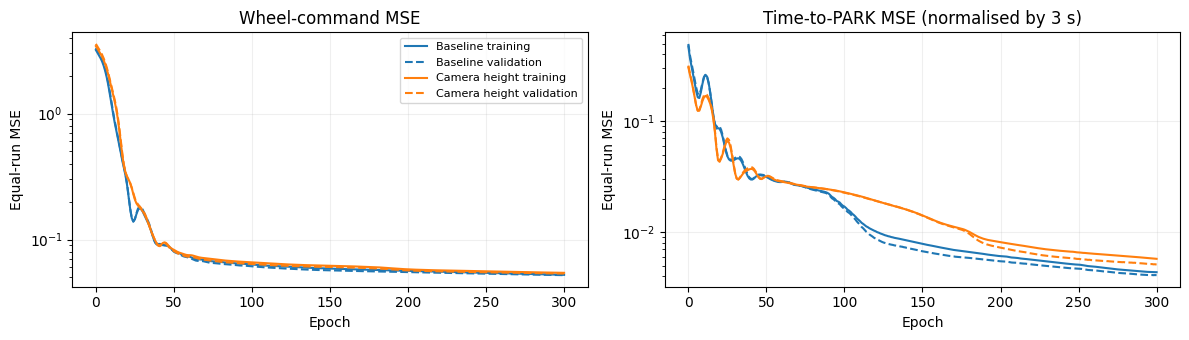

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for label, directory, colour in [('Baseline', MODELS, 'tab:blue'), ('Camera height', H/'models', 'tab:orange')]:
    history = pd.DataFrame(json.loads((directory/'driving_seed7_history.json').read_text()))
    for axis, field, title in zip(axes, ['command', 'aux'], ['Wheel-command MSE', 'Time-to-PARK MSE (normalised by 3 s)']):
        axis.plot(history.epoch, history['train_'+field], color=colour, label=label+' training')
        axis.plot(history.epoch, history['val_'+field], color=colour, linestyle='--', label=label+' validation')
        axis.set(xlabel='Epoch', ylabel='Equal-run MSE', title=title, yscale='log')
        axis.grid(alpha=.2)
axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

### Paired results: complete driving and reaching episodes


In [31]:
height_rows = json.loads((H/'results/summary.json').read_text())
height_results = pd.DataFrame([dict(variant=r['variant'], dot=r['dot'], parked=r['parked'],
    park_cm=100*r['park_error_vs_expert_m'] if r['parked'] else np.nan,
    heading_deg=abs(np.degrees(r['park_heading_error_rad'])) if r['park_heading_error_rad'] is not None else np.nan,
    park_s=r['park_s'], stopped=r['stop_s'] is not None, closest_mm=r['min_mm'],
    at_stop_mm=r['at_network_stop_mm'], drift_mm=r['post_stop_drift_mm'], success=r['success']) for r in height_rows])
assert len(height_results)==12 and height_results.groupby('variant').size().eq(6).all()
height_pair = height_results.pivot(index='dot', columns='variant', values=['park_cm', 'heading_deg', 'closest_mm', 'at_stop_mm'])
display(height_pair.round(1))
height_score = height_results.groupby('variant').agg(attempts=('dot','size'), PARK=('parked','sum'), STOP=('stopped','sum'),
    median_park_cm=('park_cm','median'), median_heading_deg=('heading_deg','median'),
    median_closest_mm=('closest_mm','median'), median_at_STOP_mm=('at_stop_mm','median'), success_10mm=('success','sum'))
display(height_score.round(2))

park_cm        heading_deg        closest_mm        at_stop_mm       
variant baseline height    baseline height   baseline height   baseline height
dot                                                                           
16          21.0   15.9        11.5   11.6      289.9  337.7      317.1  486.1
333         56.2   60.0         2.7    8.6      576.7  577.9      578.3  619.6
506         42.3   49.4         0.5    0.9      577.7  652.0      662.5  752.8
673         14.1   12.1        13.5   14.3      100.3  519.9      259.4  793.2
720         61.0   30.7         2.7    0.9      596.9  299.2      623.5  314.4
830         29.8   14.2        16.1   18.6      300.7  249.4      339.9  279.7

,attempts,PARK,STOP,median_park_cm,median_heading_deg,median_closest_mm,median_at_STOP_mm,success_10mm
variant,,,,,,,,
baseline,6,6,6,36.04,7.10,438.71,459.08,0
height,6,6,6,23.31,10.06,428.82,552.86,0


### Where height helped and where it did not


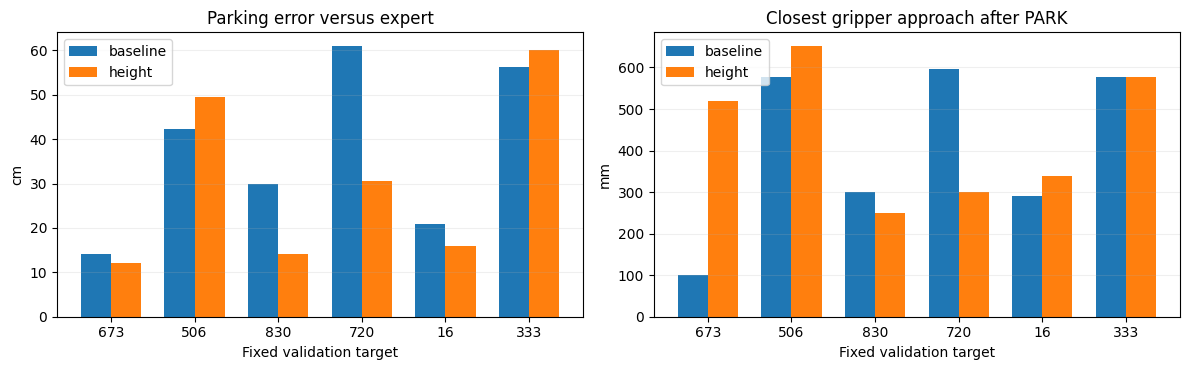

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ids = height_config['validation_cases']; locations = np.arange(len(ids))
for offset, variant, colour in [(-.18,'baseline','tab:blue'),(.18,'height','tab:orange')]:
    data = height_results[height_results.variant==variant].set_index('dot').loc[ids]
    axes[0].bar(locations+offset, data.park_cm, width=.36, label=variant, color=colour)
    axes[1].bar(locations+offset, data.closest_mm, width=.36, label=variant, color=colour)
for ax in axes:
    ax.set_xticks(locations, ids); ax.set_xlabel('Fixed validation target'); ax.legend(); ax.grid(axis='y',alpha=.2)
axes[0].set(title='Parking error versus expert', ylabel='cm')
axes[1].set(title='Closest gripper approach after PARK', ylabel='mm')
fig.tight_layout(); plt.show()

### Reading the result


In [33]:
better = int((height_pair['park_cm']['height'] < height_pair['park_cm']['baseline']).sum())
before, after = height_score.loc['baseline'], height_score.loc['height']
display(Markdown(f"""Adding camera height improved parking on **{better}/6** validation targets. Median parking error fell from **{before.median_park_cm:.1f} cm to {after.median_park_cm:.1f} cm**, a {100*(1-after.median_park_cm/before.median_park_cm):.1f}% reduction. Both versions issued PARK and STOP in all six episodes.

The whole task remains unstable. Median closest gripper distance changed from **{before.median_closest_mm:.1f} mm to {after.median_closest_mm:.1f} mm**, while median distance at STOP worsened from **{before.median_at_STOP_mm:.1f} mm to {after.median_at_STOP_mm:.1f} mm**. Neither version succeeded within 10 mm. The reaching weights are identical, but they receive different parked states and subsequent sensor inputs.

The largest parking gains were on the two middle-height targets, rather than consistently on the high/low targets as predicted. Far low target 506 and far high target 333 became worse. This is partial support for the added input, not a clean explanation of the failure or evidence that the system is stable.

This is one seed and six selected validation targets, all initially visible. No conclusion about unseen-target acquisition or generalisation is justified. The extra input also changes random initialisation under the same seed, so additional seeds would be needed to establish a robust benefit. No changes were made to search behaviour, losses, wheel-speed inputs, physics, sensor rates or reaching weights. The reserved test set was not rerun.

The comparison is a development check without a new official MLflow entry. Original iterations 34–36 and their results remain unchanged."""))

Adding camera height improved parking on **4/6** validation targets. Median parking error fell from **36.0 cm to 23.3 cm**, a 35.3% reduction. Both versions issued PARK and STOP in all six episodes.

The whole task remains unstable. Median closest gripper distance changed from **438.7 mm to 428.8 mm**, while median distance at STOP worsened from **459.1 mm to 552.9 mm**. Neither version succeeded within 10 mm. The reaching weights are identical, but they receive different parked states and subsequent sensor inputs.

The largest parking gains were on the two middle-height targets, rather than consistently on the high/low targets as predicted. Far low target 506 and far high target 333 became worse. This is partial support for the added input, not a clean explanation of the failure or evidence that the system is stable.

This is one seed and six selected validation targets, all initially visible. No conclusion about unseen-target acquisition or generalisation is justified. The extra input also changes random initialisation under the same seed, so additional seeds would be needed to establish a robust benefit. No changes were made to search behaviour, losses, wheel-speed inputs, physics, sensor rates or reaching weights. The reserved test set was not rerun.

The comparison is a development check without a new official MLflow entry. Original iterations 34–36 and their results remain unchanged.

## Development iteration: height without wheel-speed inputs

Keep camera-derived height and remove only the six wheel-speed inputs (four individual speeds, mean speed, right-minus-left speed). The driving network becomes 11 -> 16 -> 16 with unchanged wheel-command and time-to-PARK outputs. The tracker still uses wheel encoder speeds. Retain accumulated wheel angles and their two combinations, camera range, bearing sine/cosine, visibility and height.

Train driving from scratch with seed 7 and the same 100 training/100 validation runs, 300 epochs, Adam 0.01, FP32, losses and scaling convention. Keep the reaching checkpoint unchanged. Compare with the saved 17-input height model on the same six initially visible validation targets: 673, 506, 830, 720, 16, 333. Run both complete systems from the normal start through reaching. No search rules, test-set evaluation, new official MLflow entry or camera videos.

Hypothesis: removing the speed shortcut may improve parking even if offline command loss rises. No improvement is assumed; equal/worse parking error would not support the change on this screen. Preserve the previous comparison and append the paired results. One seed and six targets remain a development check.


### No-speed comparison: inputs and execution


In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
NS = Path('../arm/results/driving_height_no_speed11')
NS_BASE = Path('../arm/results/driving_height17')
ns_config = json.loads((NS/'config.json').read_text())
ns_training = json.loads((NS/'models/summary.json').read_text())
assert ns_config['validation_cases'] == json.loads((NS_BASE/'config.json').read_text())['validation_cases']
assert (NS/'models/reaching_seed7.npz').read_bytes() == (NS_BASE/'models/reaching_seed7.npz').read_bytes()
display(pd.DataFrame(ns_config['cases']))
print('11 inputs: six accumulated-angle features; camera range, sin/cos bearing, visibility, height.')
print('Wheel speeds remain in the tracker. Reaching weights unchanged. Seed 7, 300 epochs, same losses.')
print('Selected epoch:', ns_training['driving']['selected_epoch'])
print('Training including loading: %.2f s; 12 full simulations: %.2f s' % (ns_training['elapsed_s'], json.loads((NS/'results/completion.json').read_text())['elapsed_s']))

,dot,range_m,height_m,initially_visible
0,673,1.274653,0.234875,True
1,506,1.787443,0.257822,True
2,830,1.352278,0.896056,True
3,720,1.734537,0.791538,True
4,16,1.148734,1.127223,True
5,333,1.551641,1.211776,True


11 inputs: six accumulated-angle features; camera range, sin/cos bearing, visibility, height.
Wheel speeds remain in the tracker. Reaching weights unchanged. Seed 7, 300 epochs, same losses.
Selected epoch: 299
Training including loading: 11.89 s; 12 full simulations: 45.89 s


### No-speed comparison: losses


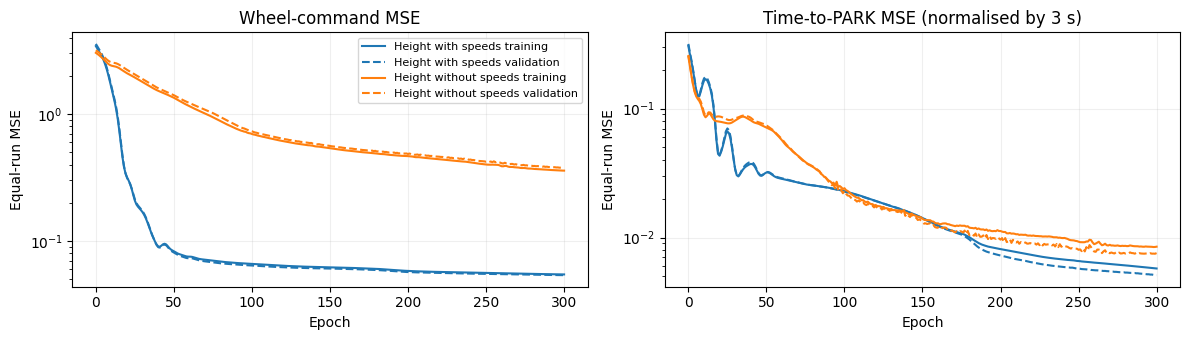

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for label, directory, colour in [('Height with speeds', NS_BASE/'models', 'tab:blue'), ('Height without speeds', NS/'models', 'tab:orange')]:
    hist = pd.DataFrame(json.loads((directory/'driving_seed7_history.json').read_text()))
    for ax, field, title in zip(axes, ['command','aux'], ['Wheel-command MSE','Time-to-PARK MSE (normalised by 3 s)']):
        ax.plot(hist.epoch, hist['train_'+field], color=colour, label=label+' training')
        ax.plot(hist.epoch, hist['val_'+field], color=colour, linestyle='--', label=label+' validation')
        ax.set(title=title, xlabel='Epoch', ylabel='Equal-run MSE', yscale='log'); ax.grid(alpha=.2)
axes[0].legend(fontsize=8); fig.tight_layout(); plt.show()

### No-speed comparison: six paired full runs


In [3]:
ns_rows = json.loads((NS/'results/summary.json').read_text())
ns_results = pd.DataFrame([dict(variant=r['variant'], dot=r['dot'], parked=r['parked'],
    park_cm=100*r['park_error_vs_expert_m'] if r['parked'] else np.nan,
    heading_deg=abs(np.degrees(r['park_heading_error_rad'])) if r['park_heading_error_rad'] is not None else np.nan,
    park_s=r['park_s'], stopped=r['stop_s'] is not None, closest_mm=r['min_mm'],
    at_stop_mm=r['at_network_stop_mm'], success=r['success']) for r in ns_rows])
assert len(ns_results)==12 and ns_results.groupby('variant').size().eq(6).all()
ns_pairs=ns_results.pivot(index='dot',columns='variant',values=['park_cm','heading_deg','closest_mm','at_stop_mm'])
display(ns_pairs.round(1))
ns_scores=ns_results.groupby('variant').agg(attempts=('dot','size'),PARK=('parked','sum'),STOP=('stopped','sum'),
    median_park_cm=('park_cm','median'),median_heading_deg=('heading_deg','median'),
    median_closest_mm=('closest_mm','median'),median_at_STOP_mm=('at_stop_mm','median'),success_10mm=('success','sum'))
display(ns_scores.round(2))

park_cm                 heading_deg                 closest_mm  \
variant baseline height_no_speed    baseline height_no_speed   baseline   
dot                                                                       
16          15.9             8.6        11.6             2.8      337.7   
333         60.0            19.3         8.6             1.2      577.9   
506         49.4             3.8         0.9             3.6      652.0   
673         12.1             3.8        14.3             1.4      519.9   
720         30.7             4.1         0.9             2.6      299.2   
830         14.2             4.8        18.6             1.2      249.4   

                        at_stop_mm                  
variant height_no_speed   baseline height_no_speed  
dot                                                 
16                155.2      486.1           180.3  
333               213.5      619.6           219.3  
506               130.4      752.8           264.9  
673               163.5      793.2           280.2  
720                24.3      314.4            67.2  
830                30.2      279.7          1134.9

,attempts,PARK,STOP,median_park_cm,median_heading_deg,median_closest_mm,median_at_STOP_mm,success_10mm
variant,,,,,,,,
baseline,6,6,6,23.31,10.06,428.82,552.86,0
height_no_speed,6,6,6,4.41,2.00,142.78,242.11,0


### No-speed comparison: parking and reaching


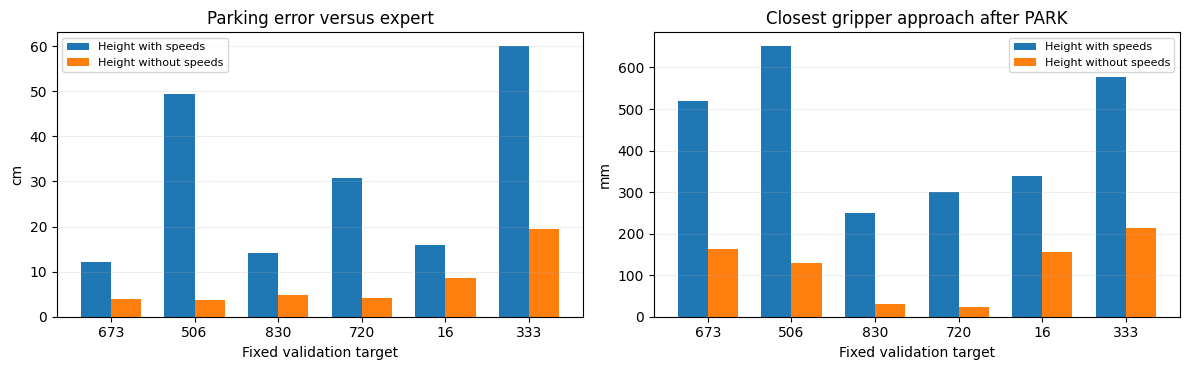

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ns_ids=ns_config['validation_cases']; loc=np.arange(len(ns_ids))
for shift, variant, label in [(-.18,'baseline','Height with speeds'),(.18,'height_no_speed','Height without speeds')]:
    d=ns_results[ns_results.variant==variant].set_index('dot').loc[ns_ids]
    axes[0].bar(loc+shift,d.park_cm,width=.36,label=label)
    axes[1].bar(loc+shift,d.closest_mm,width=.36,label=label)
for ax in axes:
    ax.set_xticks(loc,ns_ids);ax.set_xlabel('Fixed validation target');ax.legend(fontsize=8);ax.grid(axis='y',alpha=.2)
axes[0].set(title='Parking error versus expert',ylabel='cm')
axes[1].set(title='Closest gripper approach after PARK',ylabel='mm')
fig.tight_layout();plt.show()

### No-speed comparison: reading the result


In [5]:
ns_b=ns_scores.loc['baseline'];ns_c=ns_scores.loc['height_no_speed']
ns_better=int((ns_pairs['park_cm']['height_no_speed'] < ns_pairs['park_cm']['baseline']).sum())
ns_verdict='improved' if ns_c.median_park_cm < ns_b.median_park_cm else 'worsened'
display(Markdown(f"""Removing the six speed inputs **{ns_verdict} median parking error from {ns_b.median_park_cm:.1f} cm to {ns_c.median_park_cm:.1f} cm**. It improved {ns_better}/6 individual targets. PARK counts: {int(ns_b.PARK)}/6 with speeds and {int(ns_c.PARK)}/6 without. STOP counts: {int(ns_b.STOP)}/6 and {int(ns_c.STOP)}/6 respectively.

Median closest reach changed from **{ns_b.median_closest_mm:.1f} mm to {ns_c.median_closest_mm:.1f} mm**; median distance at STOP changed from **{ns_b.median_at_STOP_mm:.1f} mm to {ns_c.median_at_STOP_mm:.1f} mm**. Success within 10 mm: {int(ns_b.success_10mm)}/6 versus {int(ns_c.success_10mm)}/6. Missing PARK/STOP attempts remain in the counts; conditional medians omit undefined events.

This tests the feature-removal intervention, not a definitive causal diagnosis of speed copying. The architecture width, losses, training schedule and reaching weights are unchanged, but input size changes random initialisation under the same seed. One seed and six initially visible validation targets cannot establish generalisation or behaviour before first detection. No search rules, additional sensors, DART, DAgger or reserved-test evaluation were introduced. Encoder speeds are still used by the tracker.

These are development checks. Previous notebook cells and official iterations remain unchanged; no new official MLflow run was created."""))

Removing the six speed inputs **improved median parking error from 23.3 cm to 4.4 cm**. It improved 6/6 individual targets. PARK counts: 6/6 with speeds and 6/6 without. STOP counts: 6/6 and 6/6 respectively.

Median closest reach changed from **428.8 mm to 142.8 mm**; median distance at STOP changed from **552.9 mm to 242.1 mm**. Success within 10 mm: 0/6 versus 0/6. Missing PARK/STOP attempts remain in the counts; conditional medians omit undefined events.

This tests the feature-removal intervention, not a definitive causal diagnosis of speed copying. The architecture width, losses, training schedule and reaching weights are unchanged, but input size changes random initialisation under the same seed. One seed and six initially visible validation targets cannot establish generalisation or behaviour before first detection. No search rules, additional sensors, DART, DAgger or reserved-test evaluation were introduced. Encoder speeds are still used by the tracker.

These are development checks. Previous notebook cells and official iterations remain unchanged; no new official MLflow run was created.

## Development batch: cumulative arm changes

Freeze the improved 11-input driving model and the existing 17-input STOP-distance network. Train three torque-network variants, seed 7, with the original standardised torque MSE plus auxiliary distance MSE, equal run weighting, Adam 0.01 and FP32:

1. Extend training to 1,200 epochs with 64/64 hidden layers.
2. Retain the 1,200-epoch budget and widen both hidden layers to 128.
3. Retain that budget and width, adding joint/camera sensor observations from 50 ms and 100 ms earlier. Inputs are ordered current, -50 ms, -100 ms (51 values). History resets at PARK; before sufficient history exists, repeat the first PARK observation. Training and deployment use the same causal padding. The frozen STOP network receives only the current 17 values.

Each variant starts from scratch. Select its checkpoint by minimum validation loss across its training budget; do not select by simulator results. Save all epoch losses and intermediate PyTorch checkpoints at 300, 600 and 1,200 epochs. Use the same 100 training and 100 validation runs. Six full validation episodes per variant: 673, 506, 830, 720, 16, 333. Compare with the previous six runs of the improved driving model plus original reaching network. Every simulation starts normally; no isolated PARK resets or search rules. The reserved test set is untouched.

Hypotheses: longer training may reduce underfitting; width may improve the state-to-torque mapping; history may resolve ambiguity from a single observation. None is assumed to help. Report all six runs, parking, closest approach, STOP error and drift for each variant. This cumulative design tests successive changes, not independent effects. One seed and six initially visible targets remain a development screen.


### Cumulative batch: shared evidence and outcomes

Closest distance covers reaching and the 0.5-second observation after STOP. STOP is a completion signal; learned torques continue during that observation, so a closer pass after STOP is not a successful stop. The distance at STOP is reported separately.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
AB=Path('../arm/results/arm_cumulative')
AB_BASE=Path('../arm/results/driving_height_no_speed11')
ab_config=json.loads((AB/'config.json').read_text())
ab_training=json.loads((AB/'training_summary.json').read_text())
ab_rows=[dict(r,variant='baseline') for r in json.loads((AB_BASE/'results/summary.json').read_text()) if r['variant']=='height_no_speed']
ab_rows += json.loads((AB/'results/summary.json').read_text())
ab_data=pd.DataFrame([dict(variant=r['variant'],dot=r['dot'],parked=r['parked'],park_s=r['park_s'],
    stopped=r['stop_s'] is not None,park_cm=100*r['park_error_vs_expert_m'] if r['parked'] else np.nan,
    closest_mm=r['min_mm'],at_stop_mm=r['at_network_stop_mm'],drift_mm=r['post_stop_drift_mm'],success=r['success']) for r in ab_rows])
assert len(ab_data)==24 and ab_data.groupby('variant').size().eq(6).all()
ab_score=ab_data.groupby('variant').agg(attempts=('dot','size'),PARK=('parked','sum'),STOP=('stopped','sum'),
    median_park_cm=('park_cm','median'),median_closest_mm=('closest_mm','median'),
    median_STOP_mm=('at_stop_mm','median'),success_10mm=('success','sum')).loc[['baseline','longer','wider','history']]
display(ab_score.round(2))
print('Total training/loading: %.1f s; 18 full simulations: %.1f s' % (ab_training['elapsed_s'],json.loads((AB/'results/completion.json').read_text())['elapsed_s']))
print('Fixed seed 7 and six validation targets; frozen driving and STOP networks; no test evaluation.')

,attempts,PARK,STOP,median_park_cm,median_closest_mm,median_STOP_mm,success_10mm
variant,,,,,,,
baseline,6,6,6,4.41,142.78,242.11,0
longer,6,6,6,4.41,93.17,358.76,0
wider,6,6,6,4.41,81.03,131.66,0
history,6,6,6,4.41,73.87,217.52,0


Total training/loading: 239.7 s; 18 full simulations: 62.3 s
Fixed seed 7 and six validation targets; frozen driving and STOP networks; no test evaluation.


### 1,200 epochs, 64-unit layers


In [2]:
ab_name='longer';ab_parent='baseline'
ab_meta=next(x for x in ab_training['variants'] if x['variant']==ab_name)
display(pd.DataFrame([{k:ab_meta[k] for k in ['variant','width','history','selected_epoch','selected_val_loss','elapsed_s','train_rows','val_rows']}]))
print('Current sensor values only for frozen STOP. Torque history order: current, 50 ms ago, 100 ms ago.' if ab_meta['history'] else 'Torque and frozen STOP use current sensor values.')
print('Checkpoint chosen by validation loss, not the six simulator results.')
print('The auxiliary distance head trains with the torque network; the separate frozen STOP network makes the runtime STOP decision.')


,variant,width,history,selected_epoch,selected_val_loss,elapsed_s,train_rows,val_rows
0,longer,64,False,1200,0.020776,49.111548,295084,288818


Torque and frozen STOP use current sensor values.
Checkpoint chosen by validation loss, not the six simulator results.
The auxiliary distance head trains with the torque network; the separate frozen STOP network makes the runtime STOP decision.


#### Training and validation losses


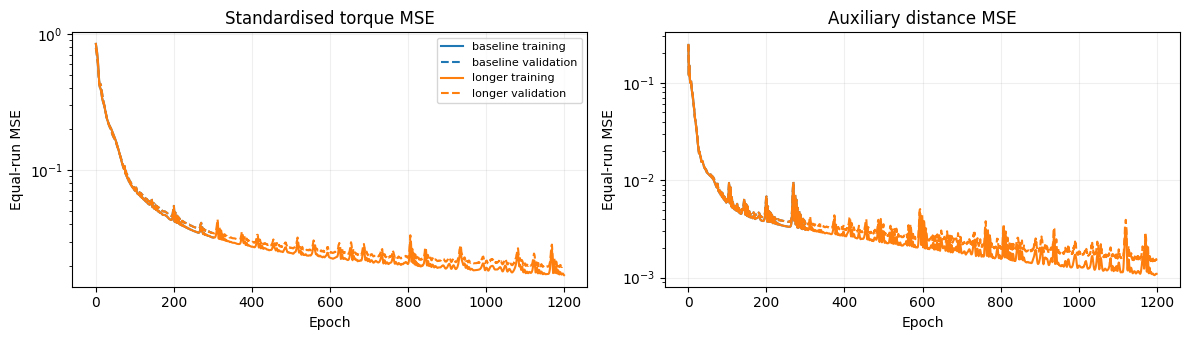

In [3]:
ab_name='longer';ab_parent='baseline'
fig,axes=plt.subplots(1,2,figsize=(12,3.5))
for label,directory,colour in [(ab_parent,Path('../arm/models/golden_11109') if ab_parent=='baseline' else AB/'models'/ab_parent,'tab:blue'),(ab_name,AB/'models'/ab_name,'tab:orange')]:
    h=pd.DataFrame(json.loads((directory/'torque_seed7_history.json').read_text()))
    for ax,field,title in zip(axes,['command','aux'],['Standardised torque MSE','Auxiliary distance MSE']):
        ax.plot(h.epoch,h['train_'+field],color=colour,label=label+' training')
        ax.plot(h.epoch,h['val_'+field],color=colour,linestyle='--',label=label+' validation')
        ax.set(xlabel='Epoch',ylabel='Equal-run MSE',title=title,yscale='log');ax.grid(alpha=.2)
axes[0].legend(fontsize=8);fig.tight_layout();plt.show()

#### Six full validation episodes


In [4]:
ab_name='longer';ab_parent='baseline'
display(ab_data[ab_data.variant.isin([ab_parent,ab_name])].pivot(index='dot',columns='variant',values=['closest_mm','at_stop_mm','drift_mm']).round(1))
display(ab_score.loc[[ab_parent,ab_name]].round(2))

closest_mm        at_stop_mm        drift_mm       
variant   baseline longer   baseline longer baseline longer
dot                                                        
16           155.2  160.5      180.3  979.1    154.6  468.0
333          213.5   77.4      219.3  255.9    143.5  331.0
506          130.4  108.9      264.9  499.1     -6.0  162.2
673          163.5  143.5      280.2  461.7     -0.7  392.6
720           24.3   10.5       67.2   67.2    -27.7  -34.0
830           30.2   10.4     1134.9   48.3   -178.5   46.1

,attempts,PARK,STOP,median_park_cm,median_closest_mm,median_STOP_mm,success_10mm
variant,,,,,,,
baseline,6,6,6,4.41,142.78,242.11,0
longer,6,6,6,4.41,93.17,358.76,0


#### Actual distance and frozen STOP prediction during reaching


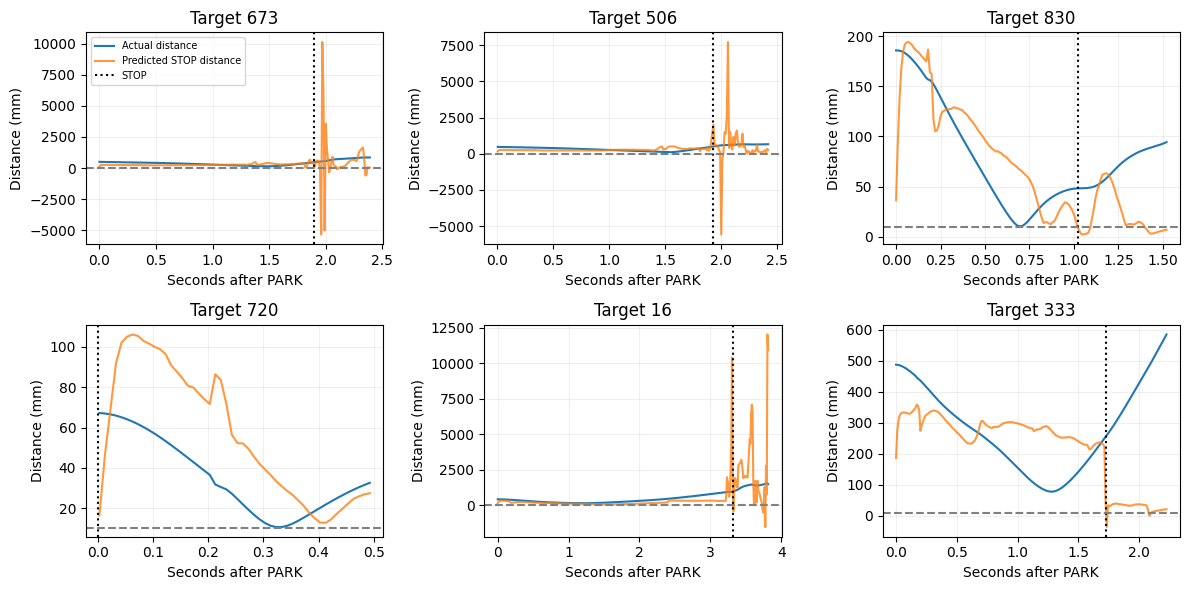

In [5]:
fig,axes=plt.subplots(2,3,figsize=(12,6),sharex=False)
for ax,dot in zip(axes.flat,ab_config['validation_cases']):
    r=json.loads((AB/'results'/f'longer_dot{dot}.json').read_text());d=pd.DataFrame(r['log'])
    if len(d):
        ax.plot(d.t-r['park_s'],d.ee_mm,label='Actual distance')
        ax.plot(d.t-r['park_s'],1000*d.ttp_s,label='Predicted STOP distance',alpha=.8)
        if r['stop_s'] is not None:ax.axvline(r['stop_s']-r['park_s'],color='black',linestyle=':',label='STOP')
    ax.axhline(10,color='grey',linestyle='--');ax.set(title=f'Target {dot}',xlabel='Seconds after PARK',ylabel='Distance (mm)');ax.grid(alpha=.2)
axes.flat[0].legend(fontsize=7);fig.tight_layout();plt.show()

#### Reading this comparison


In [6]:
ab_name='longer';ab_parent='baseline'
b=ab_score.loc[ab_parent];c=ab_score.loc[ab_name]
pairs=ab_data[ab_data.variant.isin([ab_parent,ab_name])].pivot(index='dot',columns='variant',values='closest_mm')
better=int((pairs[ab_name]<pairs[ab_parent]).sum())
display(Markdown(f"""Against **{ab_parent}**, **{ab_name}** improved closest approach on **{better}/6** targets. Median closest distance changed from **{b.median_closest_mm:.1f} mm to {c.median_closest_mm:.1f} mm**; median distance at STOP changed from **{b.median_STOP_mm:.1f} mm to {c.median_STOP_mm:.1f} mm**. STOP was issued in **{int(c.STOP)}/6** runs, with **{int(c.success_10mm)}/6** within 10 mm at STOP.

The driving model and separate STOP weights were frozen. STOP predictions can still change because each torque policy creates different sensor observations. Undefined STOP distances are omitted from their median, while all six attempts remain in the counts. The full episode, including the handover, is evaluated from the normal start.

This cumulative, single-seed six-target screen does not establish generalisation or isolate interactions among changes. Selected epochs use offline validation loss only. No official MLflow iteration or reserved-test evaluation was created."""))

Against **baseline**, **longer** improved closest approach on **5/6** targets. Median closest distance changed from **142.8 mm to 93.2 mm**; median distance at STOP changed from **242.1 mm to 358.8 mm**. STOP was issued in **6/6** runs, with **0/6** within 10 mm at STOP.

The driving model and separate STOP weights were frozen. STOP predictions can still change because each torque policy creates different sensor observations. Undefined STOP distances are omitted from their median, while all six attempts remain in the counts. The full episode, including the handover, is evaluated from the normal start.

This cumulative, single-seed six-target screen does not establish generalisation or isolate interactions among changes. Selected epochs use offline validation loss only. No official MLflow iteration or reserved-test evaluation was created.

### 1,200 epochs, 128-unit layers


In [7]:
ab_name='wider';ab_parent='longer'
ab_meta=next(x for x in ab_training['variants'] if x['variant']==ab_name)
display(pd.DataFrame([{k:ab_meta[k] for k in ['variant','width','history','selected_epoch','selected_val_loss','elapsed_s','train_rows','val_rows']}]))
print('Current sensor values only for frozen STOP. Torque history order: current, 50 ms ago, 100 ms ago.' if ab_meta['history'] else 'Torque and frozen STOP use current sensor values.')
print('Checkpoint chosen by validation loss, not the six simulator results.')
print('The auxiliary distance head trains with the torque network; the separate frozen STOP network makes the runtime STOP decision.')


,variant,width,history,selected_epoch,selected_val_loss,elapsed_s,train_rows,val_rows
0,wider,128,False,1171,0.015504,88.206729,295084,288818


Torque and frozen STOP use current sensor values.
Checkpoint chosen by validation loss, not the six simulator results.
The auxiliary distance head trains with the torque network; the separate frozen STOP network makes the runtime STOP decision.


#### Training and validation losses


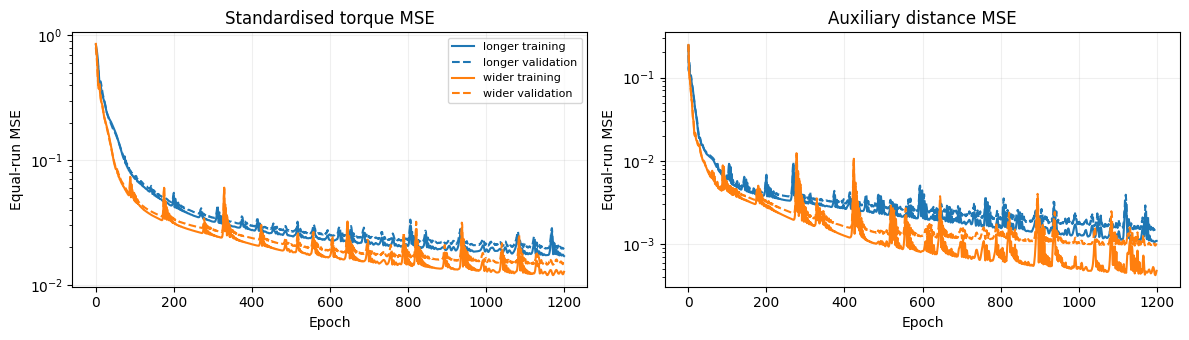

In [8]:
ab_name='wider';ab_parent='longer'
fig,axes=plt.subplots(1,2,figsize=(12,3.5))
for label,directory,colour in [(ab_parent,Path('../arm/models/golden_11109') if ab_parent=='baseline' else AB/'models'/ab_parent,'tab:blue'),(ab_name,AB/'models'/ab_name,'tab:orange')]:
    h=pd.DataFrame(json.loads((directory/'torque_seed7_history.json').read_text()))
    for ax,field,title in zip(axes,['command','aux'],['Standardised torque MSE','Auxiliary distance MSE']):
        ax.plot(h.epoch,h['train_'+field],color=colour,label=label+' training')
        ax.plot(h.epoch,h['val_'+field],color=colour,linestyle='--',label=label+' validation')
        ax.set(xlabel='Epoch',ylabel='Equal-run MSE',title=title,yscale='log');ax.grid(alpha=.2)
axes[0].legend(fontsize=8);fig.tight_layout();plt.show()

#### Six full validation episodes


In [9]:
ab_name='wider';ab_parent='longer'
display(ab_data[ab_data.variant.isin([ab_parent,ab_name])].pivot(index='dot',columns='variant',values=['closest_mm','at_stop_mm','drift_mm']).round(1))
display(ab_score.loc[[ab_parent,ab_name]].round(2))

closest_mm        at_stop_mm        drift_mm      
variant     longer  wider     longer  wider   longer wider
dot                                                       
16           160.5   84.1      979.1   91.3    468.0  29.2
333           77.4   77.9      255.9  172.0    331.0 -94.3
506          108.9  203.4      499.1  221.1    162.2   4.0
673          143.5  218.1      461.7  259.3    392.6 -42.4
720           10.5   12.3       67.2   67.2    -34.0 -38.2
830           10.4   31.3       48.3   33.6     46.1  22.5

,attempts,PARK,STOP,median_park_cm,median_closest_mm,median_STOP_mm,success_10mm
variant,,,,,,,
longer,6,6,6,4.41,93.17,358.76,0
wider,6,6,6,4.41,81.03,131.66,0


#### Actual distance and frozen STOP prediction during reaching


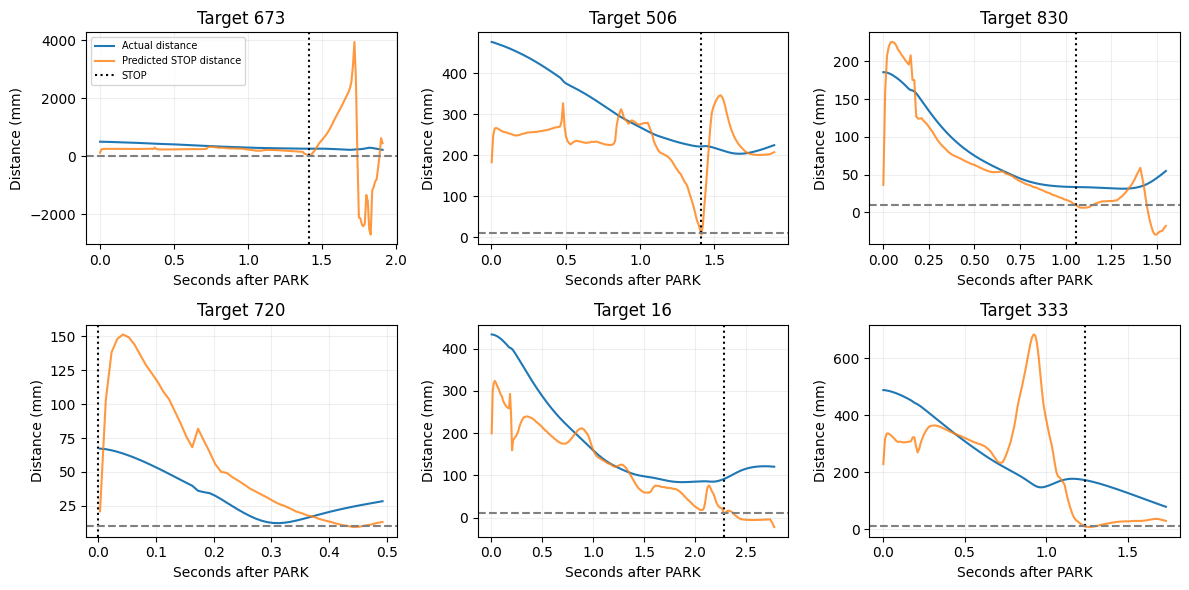

In [10]:
fig,axes=plt.subplots(2,3,figsize=(12,6),sharex=False)
for ax,dot in zip(axes.flat,ab_config['validation_cases']):
    r=json.loads((AB/'results'/f'wider_dot{dot}.json').read_text());d=pd.DataFrame(r['log'])
    if len(d):
        ax.plot(d.t-r['park_s'],d.ee_mm,label='Actual distance')
        ax.plot(d.t-r['park_s'],1000*d.ttp_s,label='Predicted STOP distance',alpha=.8)
        if r['stop_s'] is not None:ax.axvline(r['stop_s']-r['park_s'],color='black',linestyle=':',label='STOP')
    ax.axhline(10,color='grey',linestyle='--');ax.set(title=f'Target {dot}',xlabel='Seconds after PARK',ylabel='Distance (mm)');ax.grid(alpha=.2)
axes.flat[0].legend(fontsize=7);fig.tight_layout();plt.show()

#### Reading this comparison


In [11]:
ab_name='wider';ab_parent='longer'
b=ab_score.loc[ab_parent];c=ab_score.loc[ab_name]
pairs=ab_data[ab_data.variant.isin([ab_parent,ab_name])].pivot(index='dot',columns='variant',values='closest_mm')
better=int((pairs[ab_name]<pairs[ab_parent]).sum())
display(Markdown(f"""Against **{ab_parent}**, **{ab_name}** improved closest approach on **{better}/6** targets. Median closest distance changed from **{b.median_closest_mm:.1f} mm to {c.median_closest_mm:.1f} mm**; median distance at STOP changed from **{b.median_STOP_mm:.1f} mm to {c.median_STOP_mm:.1f} mm**. STOP was issued in **{int(c.STOP)}/6** runs, with **{int(c.success_10mm)}/6** within 10 mm at STOP.

The driving model and separate STOP weights were frozen. STOP predictions can still change because each torque policy creates different sensor observations. Undefined STOP distances are omitted from their median, while all six attempts remain in the counts. The full episode, including the handover, is evaluated from the normal start.

This cumulative, single-seed six-target screen does not establish generalisation or isolate interactions among changes. Selected epochs use offline validation loss only. No official MLflow iteration or reserved-test evaluation was created."""))

Against **longer**, **wider** improved closest approach on **1/6** targets. Median closest distance changed from **93.2 mm to 81.0 mm**; median distance at STOP changed from **358.8 mm to 131.7 mm**. STOP was issued in **6/6** runs, with **0/6** within 10 mm at STOP.

The driving model and separate STOP weights were frozen. STOP predictions can still change because each torque policy creates different sensor observations. Undefined STOP distances are omitted from their median, while all six attempts remain in the counts. The full episode, including the handover, is evaluated from the normal start.

This cumulative, single-seed six-target screen does not establish generalisation or isolate interactions among changes. Selected epochs use offline validation loss only. No official MLflow iteration or reserved-test evaluation was created.

### 1,200 epochs, 128-unit layers, short sensor history


In [12]:
ab_name='history';ab_parent='wider'
ab_meta=next(x for x in ab_training['variants'] if x['variant']==ab_name)
display(pd.DataFrame([{k:ab_meta[k] for k in ['variant','width','history','selected_epoch','selected_val_loss','elapsed_s','train_rows','val_rows']}]))
print('Current sensor values only for frozen STOP. Torque history order: current, 50 ms ago, 100 ms ago.' if ab_meta['history'] else 'Torque and frozen STOP use current sensor values.')
print('Checkpoint chosen by validation loss, not the six simulator results.')
print('The auxiliary distance head trains with the torque network; the separate frozen STOP network makes the runtime STOP decision.')


,variant,width,history,selected_epoch,selected_val_loss,elapsed_s,train_rows,val_rows
0,history,128,True,1194,0.013163,90.837755,295084,288818


Current sensor values only for frozen STOP. Torque history order: current, 50 ms ago, 100 ms ago.
Checkpoint chosen by validation loss, not the six simulator results.
The auxiliary distance head trains with the torque network; the separate frozen STOP network makes the runtime STOP decision.


#### Training and validation losses


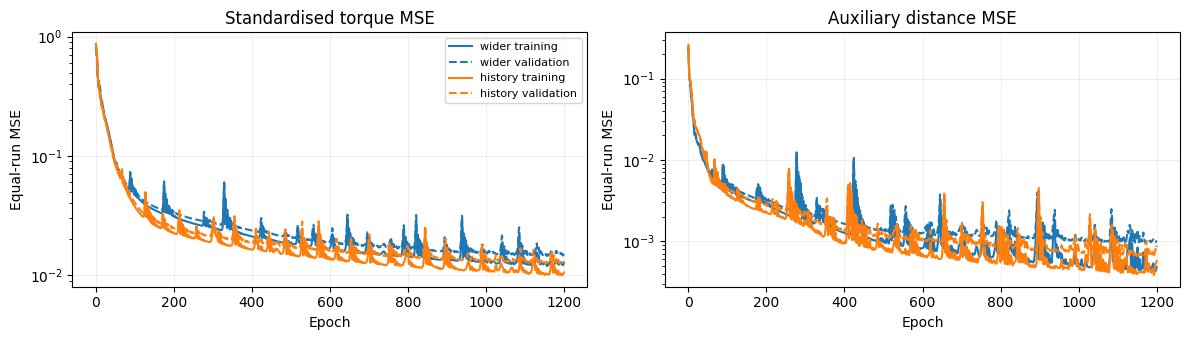

In [13]:
ab_name='history';ab_parent='wider'
fig,axes=plt.subplots(1,2,figsize=(12,3.5))
for label,directory,colour in [(ab_parent,Path('../arm/models/golden_11109') if ab_parent=='baseline' else AB/'models'/ab_parent,'tab:blue'),(ab_name,AB/'models'/ab_name,'tab:orange')]:
    h=pd.DataFrame(json.loads((directory/'torque_seed7_history.json').read_text()))
    for ax,field,title in zip(axes,['command','aux'],['Standardised torque MSE','Auxiliary distance MSE']):
        ax.plot(h.epoch,h['train_'+field],color=colour,label=label+' training')
        ax.plot(h.epoch,h['val_'+field],color=colour,linestyle='--',label=label+' validation')
        ax.set(xlabel='Epoch',ylabel='Equal-run MSE',title=title,yscale='log');ax.grid(alpha=.2)
axes[0].legend(fontsize=8);fig.tight_layout();plt.show()

#### Six full validation episodes


In [14]:
ab_name='history';ab_parent='wider'
display(ab_data[ab_data.variant.isin([ab_parent,ab_name])].pivot(index='dot',columns='variant',values=['closest_mm','at_stop_mm','drift_mm']).round(1))
display(ab_score.loc[[ab_parent,ab_name]].round(2))

closest_mm        at_stop_mm        drift_mm      
variant    history  wider    history  wider  history wider
dot                                                       
16            95.3   84.1       96.6   91.3     41.5  29.2
333           51.9   77.9      370.7  172.0    241.6 -94.3
506          146.8  203.4      348.6  221.1     55.4   4.0
673          198.1  218.1      338.4  259.3     77.6 -42.4
720           15.0   12.3       67.2   67.2    -51.7 -38.2
830           52.4   31.3       54.9   33.6    113.0  22.5

,attempts,PARK,STOP,median_park_cm,median_closest_mm,median_STOP_mm,success_10mm
variant,,,,,,,
wider,6,6,6,4.41,81.03,131.66,0
history,6,6,6,4.41,73.87,217.52,0


#### Actual distance and frozen STOP prediction during reaching


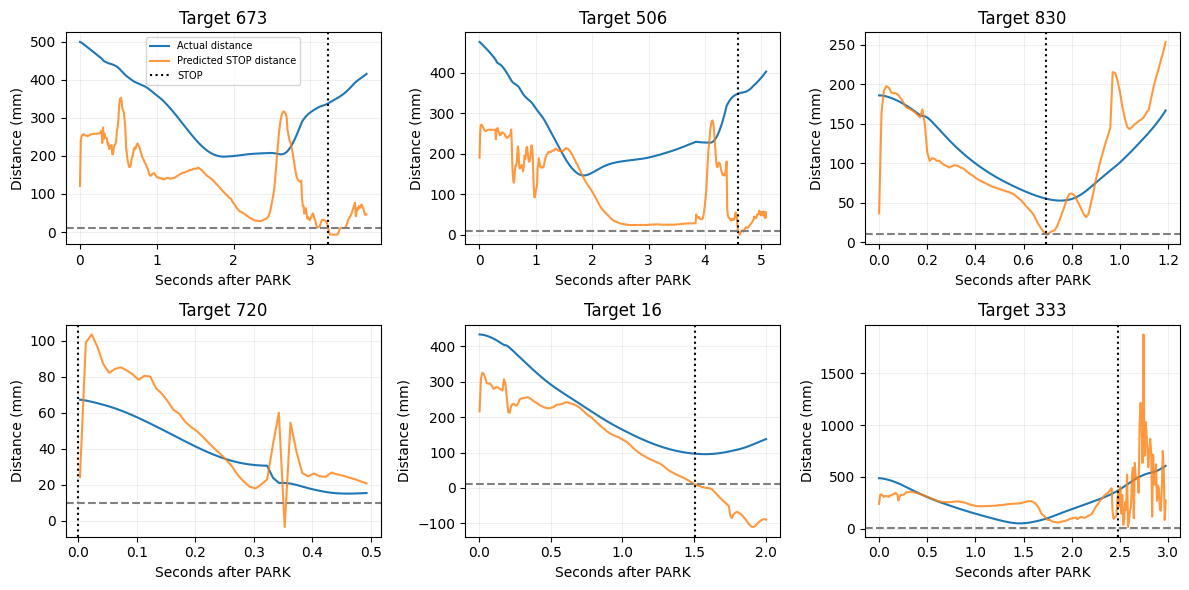

In [15]:
fig,axes=plt.subplots(2,3,figsize=(12,6),sharex=False)
for ax,dot in zip(axes.flat,ab_config['validation_cases']):
    r=json.loads((AB/'results'/f'history_dot{dot}.json').read_text());d=pd.DataFrame(r['log'])
    if len(d):
        ax.plot(d.t-r['park_s'],d.ee_mm,label='Actual distance')
        ax.plot(d.t-r['park_s'],1000*d.ttp_s,label='Predicted STOP distance',alpha=.8)
        if r['stop_s'] is not None:ax.axvline(r['stop_s']-r['park_s'],color='black',linestyle=':',label='STOP')
    ax.axhline(10,color='grey',linestyle='--');ax.set(title=f'Target {dot}',xlabel='Seconds after PARK',ylabel='Distance (mm)');ax.grid(alpha=.2)
axes.flat[0].legend(fontsize=7);fig.tight_layout();plt.show()

#### Reading this comparison


In [16]:
ab_name='history';ab_parent='wider'
b=ab_score.loc[ab_parent];c=ab_score.loc[ab_name]
pairs=ab_data[ab_data.variant.isin([ab_parent,ab_name])].pivot(index='dot',columns='variant',values='closest_mm')
better=int((pairs[ab_name]<pairs[ab_parent]).sum())
display(Markdown(f"""Against **{ab_parent}**, **{ab_name}** improved closest approach on **{better}/6** targets. Median closest distance changed from **{b.median_closest_mm:.1f} mm to {c.median_closest_mm:.1f} mm**; median distance at STOP changed from **{b.median_STOP_mm:.1f} mm to {c.median_STOP_mm:.1f} mm**. STOP was issued in **{int(c.STOP)}/6** runs, with **{int(c.success_10mm)}/6** within 10 mm at STOP.

The driving model and separate STOP weights were frozen. STOP predictions can still change because each torque policy creates different sensor observations. Undefined STOP distances are omitted from their median, while all six attempts remain in the counts. The full episode, including the handover, is evaluated from the normal start.

This cumulative, single-seed six-target screen does not establish generalisation or isolate interactions among changes. Selected epochs use offline validation loss only. No official MLflow iteration or reserved-test evaluation was created."""))

Against **wider**, **history** improved closest approach on **3/6** targets. Median closest distance changed from **81.0 mm to 73.9 mm**; median distance at STOP changed from **131.7 mm to 217.5 mm**. STOP was issued in **6/6** runs, with **0/6** within 10 mm at STOP.

The driving model and separate STOP weights were frozen. STOP predictions can still change because each torque policy creates different sensor observations. Undefined STOP distances are omitted from their median, while all six attempts remain in the counts. The full episode, including the handover, is evaluated from the normal start.

This cumulative, single-seed six-target screen does not establish generalisation or isolate interactions among changes. Selected epochs use offline validation loss only. No official MLflow iteration or reserved-test evaluation was created.

## Development batch: distance-based PARK loss

Plan recorded before training. Repeat four cumulative configurations on the same six initially visible validation targets: 673, 506, 830, 720, 16, 333. Train on the same 100 golden training runs and select checkpoints on the same 100 validation runs, seed 7. The test set stays reserved.

Replace time-to-PARK supervision with horizontal Euclidean distance from the current expert base position to its position at the recorded PARK step. Positions are used only for training labels and evaluation, never policy inputs. Use the same numeric cap and divisor of 3, now in metres: target = min(distance_m, 3) / 3. Retain the actual small residual distance in post-PARK rows rather than forcing those labels to zero. Driving loss remains equal-run wheel-command MSE plus PARK-head MSE, weights 1 and 1. The runtime threshold changes from 0.25 seconds to 0.05 metres, fixed before evaluation and not tuned on these six runs. This is supervised distance prediction, not differentiation through the simulation.

The four configurations are: (1) height-enabled 17-input driving and original arm; (2) remove six driving speed inputs, giving 11 inputs, and original arm; (3) retain that driving network and use the longer-trained 64/64 arm; (4) retain that driving network and use the longer-trained 128/128 arm. There is no history variant in this batch. Driving remains 16/16 hidden units and 300 epochs for both new models, FP32, Adam 0.01, unchanged scaling and equal-run weighting. The earlier suggestion of 500 driving epochs is not part of this controlled rerun.

Reuse the existing exact original/longer/wider arm checkpoints, whose inputs, torque loss and separate STOP network are unchanged. This keeps all four comparisons against the preceding time-based PARK results controlled. Arm training budgets and selected checkpoints remain as recorded in the preceding sections; the arm STOP threshold stays 10 mm. Two new driving trainings and 24 new full simulations are needed.

Hypothesis: predicting remaining distance may make the PARK decision more accurate than predicting remaining time. Compare each configuration to its own saved time-based PARK counterpart; lower median parking error supports the hypothesis on this small screen. Report every case including non-parks and non-stops, closest reach and distance at arm STOP. Six initially visible targets and one seed do not establish generalisation or search ability. Full rendering, sensor rates, physics, command clipping and deadlines are unchanged. No validation animations or official MLflow iterations.


### Distance-based PARK: four paired comparisons


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
PD=Path('../arm/results/park_distance_four')
pd_config=json.loads((PD/'config.json').read_text())
pd_training=json.loads((PD/'training_summary.json').read_text())
pd_controls={'height':('driving_height17','height'), 'no_speed':('driving_height_no_speed11','height_no_speed'), 'longer_arm':('arm_cumulative','longer'), 'wider_arm':('arm_cumulative','wider')}
pd_rows=[]
for variant,(folder,old_name) in pd_controls.items():
    for r in json.loads((PD.parent/folder/'results/summary.json').read_text()):
        if r['variant']==old_name:pd_rows.append(dict(r,variant=variant,park_target='time'))
pd_rows.extend(dict(r,park_target='distance') for r in json.loads((PD/'results/summary.json').read_text()))
pd_data=pd.DataFrame([dict(variant=r['variant'],park_target=r['park_target'],dot=r['dot'],parked=r['parked'],stopped=r['stop_s'] is not None,
    park_cm=100*r['park_error_vs_expert_m'] if r['parked'] else np.nan,closest_mm=r['min_mm'],at_stop_mm=r['at_network_stop_mm'],
    drift_mm=r['post_stop_drift_mm'],park_s=r['park_s'],stop_s=r['stop_s'],success=r['success']) for r in pd_rows])
assert len(pd_data)==48 and pd_data.groupby(['variant','park_target']).size().eq(6).all()
pd_score=pd_data.groupby(['variant','park_target'],sort=False).agg(attempts=('dot','size'),PARK=('parked','sum'),STOP=('stopped','sum'),median_park_cm=('park_cm','median'),median_closest_mm=('closest_mm','median'),median_arm_STOP_mm=('at_stop_mm','median'),success_10mm=('success','sum'))
display(pd_score.round(2))
print('Two driving trainings including loading: %.1f s; 24 full simulations: %.1f s' % (pd_training['elapsed_s'],json.loads((PD/'results/completion.json').read_text())['elapsed_s']))
print('Seed 7. Same six initially visible validation targets. No reserved test evaluation or official MLflow run.')

,,attempts,PARK,STOP,median_park_cm,median_closest_mm,median_arm_STOP_mm,success_10mm
variant,park_target,,,,,,,
height,time,6,6,6,23.31,428.82,552.86,0
no_speed,time,6,6,6,4.41,142.78,242.11,0
longer_arm,time,6,6,6,4.41,93.17,358.76,0
wider_arm,time,6,6,6,4.41,81.03,131.66,0
height,distance,6,4,4,11.92,66.52,387.49,0
no_speed,distance,6,6,6,8.37,125.63,273.28,0
longer_arm,distance,6,6,6,8.37,107.57,370.48,0
wider_arm,distance,6,6,6,8.37,104.88,214.56,0


Two driving trainings including loading: 13.8 s; 24 full simulations: 84.6 s
Seed 7. Same six initially visible validation targets. No reserved test evaluation or official MLflow run.


Parking error is base distance to the expert PARK position. Reach distances are gripper-to-dot distances. Closest reach includes the 0.5-second observation after arm STOP, during which torque control continues. Missing PARK/STOP outcomes remain in counts and have no corresponding distance median.


### Camera height, original arm


In [2]:
pd_name='height';pd_drive='height17'
pd_meta=next(r for r in pd_training['variants'] if r['variant']==pd_drive)
display(pd.DataFrame([{k:pd_meta[k] for k in ['variant','selected_epoch','selected_val_loss','train_rows','val_rows','park_distance_scale_m','park_distance_threshold_m']}]))
print('Driving loss = mean wheel-command squared error + mean normalized PARK-distance squared error; each run weighted equally.')
print('Same exact arm checkpoint as this configuration’s preceding time-based PARK comparison; no arm or STOP retraining.')
print('Driving 300 epochs; two 16-unit hidden layers. Sensor inputs only; expert position is used only for the distance label and evaluation.')

,variant,selected_epoch,selected_val_loss,train_rows,val_rows,park_distance_scale_m,park_distance_threshold_m
0,height17,300,0.055244,25928,26428,3.0,0.05


Driving loss = mean wheel-command squared error + mean normalized PARK-distance squared error; each run weighted equally.
Same exact arm checkpoint as this configuration’s preceding time-based PARK comparison; no arm or STOP retraining.
Driving 300 epochs; two 16-unit hidden layers. Sensor inputs only; expert position is used only for the distance label and evaluation.


#### Driving training and validation losses


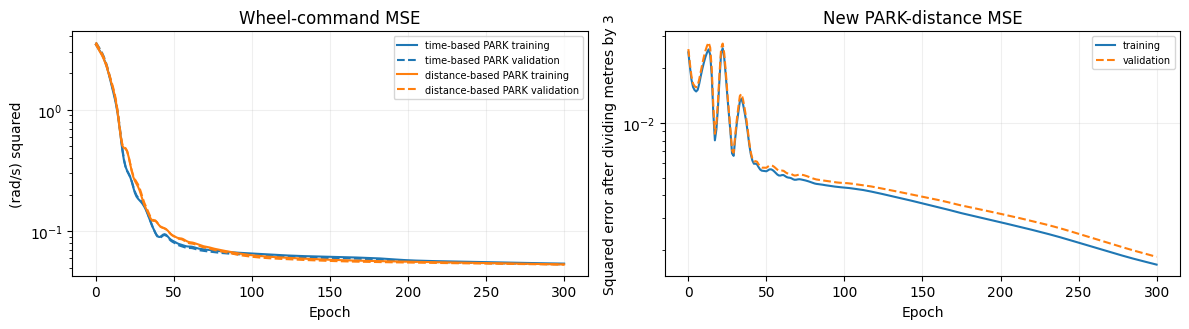

The old time-target loss and new distance-target loss measure different quantities; their magnitudes are not directly comparable.


In [3]:
pd_drive='height17'
pd_h=pd.DataFrame(json.loads((PD/'models'/pd_drive/'driving_seed7_history.json').read_text()))
pd_old_dir='driving_height17' if pd_drive=='height17' else 'driving_height_no_speed11'
pd_old_h=pd.DataFrame(json.loads((PD.parent/pd_old_dir/'models/driving_seed7_history.json').read_text()))
fig,axes=plt.subplots(1,2,figsize=(12,3.4))
for h,label,col in [(pd_old_h,'time-based PARK','tab:blue'),(pd_h,'distance-based PARK','tab:orange')]:
    axes[0].plot(h.epoch,h.train_command,label=label+' training',color=col)
    axes[0].plot(h.epoch,h.val_command,label=label+' validation',color=col,linestyle='--')
axes[1].plot(pd_h.epoch,pd_h.train_aux,label='training')
axes[1].plot(pd_h.epoch,pd_h.val_aux,label='validation',linestyle='--')
axes[0].set(title='Wheel-command MSE',ylabel='(rad/s) squared')
axes[1].set(title='New PARK-distance MSE',ylabel='Squared error after dividing metres by 3')
for ax in axes:ax.set(xlabel='Epoch',yscale='log');ax.grid(alpha=.2);ax.legend(fontsize=7)
fig.tight_layout();plt.show()
print('The old time-target loss and new distance-target loss measure different quantities; their magnitudes are not directly comparable.')

#### Same six full validation episodes


In [4]:
pd_name='height'
display(pd_data[pd_data.variant==pd_name].pivot(index='dot',columns='park_target',values=['parked','stopped','park_cm','closest_mm','at_stop_mm']).round(2))
display(pd_score.loc[pd_name].round(2))

parked        stopped          park_cm             closest_mm  \
park_target distance  time distance  time   distance       time    distance   
dot                                                                           
16              True  True     True  True   14.04218  15.949824   86.742966   
333             True  True     True  True  49.723723  60.048838  494.357253   
506            False  True    False  True        NaN  49.447182         NaN   
673            False  True    False  True        NaN  12.086373         NaN   
720             True  True     True  True   5.471026  30.662233   41.030364   
830             True  True     True  True   9.793112  14.207778   46.297988   

                          at_stop_mm              
park_target        time     distance        time  
dot                                               
16           337.725323   265.994862  486.116197  
333          577.852506   508.994974  619.611997  
506          652.031192          NaN  752.800752  
673          519.915625          NaN  793.228496  
720          299.212443    78.861427  314.361182  
830          249.449948  1260.775209  279.680645

,attempts,PARK,STOP,median_park_cm,median_closest_mm,median_arm_STOP_mm,success_10mm
park_target,,,,,,,
time,6,6,6,23.31,428.82,552.86,0
distance,6,4,4,11.92,66.52,387.49,0


#### PARK prediction versus actual distance to the expert parking position


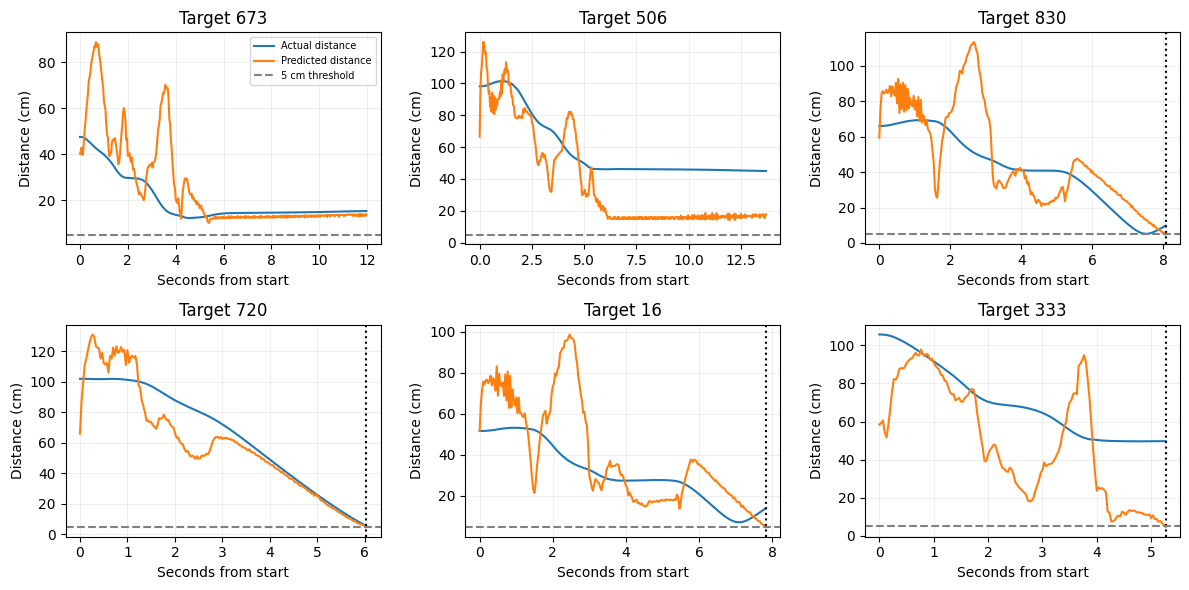

In [5]:
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,dot in zip(axes.flat,pd_config['validation_cases']):
    r=json.loads((PD/'results'/f'height_dot{dot}.json').read_text())
    frames=[f for f in r['frames'] if f.get('driving_park_distance_m') is not None]
    if frames:
        t=[f['time_s'] for f in frames]
        actual=[100*np.linalg.norm(np.array(f['base'][:2])-r['expert_park_base_xy']) for f in frames]
        ax.plot(t,actual,label='Actual distance')
        ax.plot(t,[100*f['driving_park_distance_m'] for f in frames],label='Predicted distance')
    if r['park_s'] is not None:ax.axvline(r['park_s'],color='black',linestyle=':',label='PARK')
    ax.axhline(5,color='grey',linestyle='--',label='5 cm threshold')
    ax.set(title=f'Target {dot}',xlabel='Seconds from start',ylabel='Distance (cm)');ax.grid(alpha=.2)
axes.flat[0].legend(fontsize=7);fig.tight_layout();plt.show()

#### Reaching after the new PARK decision


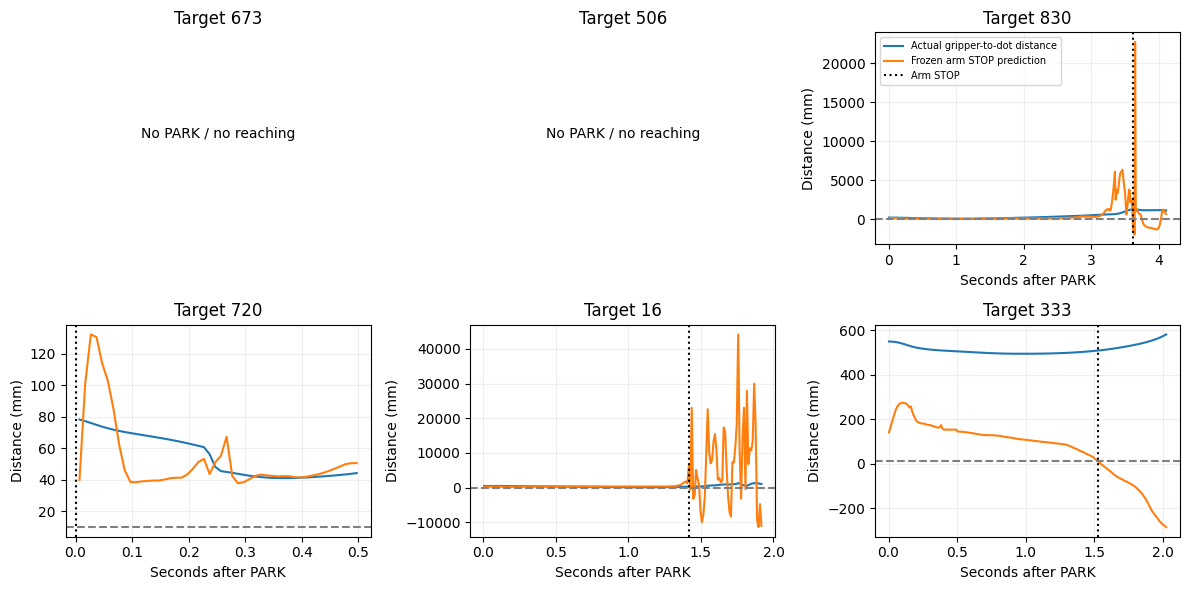

In [2]:
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,dot in zip(axes.flat,pd_config['validation_cases']):
    r=json.loads((PD/'results'/f'height_dot{dot}.json').read_text());d=pd.DataFrame(r['log'])
    if len(d):
        ax.plot(d.t-r['park_s'],d.ee_mm,label='Actual gripper-to-dot distance')
        ax.plot(d.t-r['park_s'],1000*d.ttp_s,label='Frozen arm STOP prediction')
        if r['stop_s'] is not None:ax.axvline(r['stop_s']-r['park_s'],color='black',linestyle=':',label='Arm STOP')
    else:
        ax.text(.5,.5,'No PARK / no reaching',ha='center',transform=ax.transAxes)
        ax.set_title(f'Target {dot}');ax.set_axis_off();continue
    ax.axhline(10,color='grey',linestyle='--');ax.set(title=f'Target {dot}',xlabel='Seconds after PARK',ylabel='Distance (mm)');ax.grid(alpha=.2)
axes.flat[2].legend(fontsize=7);fig.tight_layout();plt.show()

#### What changed


In [7]:
pd_name='height';before=pd_score.loc[(pd_name,'time')];after=pd_score.loc[(pd_name,'distance')]
pairs=pd_data[pd_data.variant==pd_name].pivot(index='dot',columns='park_target',values='park_cm')
valid=pairs.dropna();improved=int((valid['distance']<valid['time']).sum())
display(Markdown(f"""Changing PARK supervision improved parking error on **{improved}/{len(valid)}** targets with PARK in both conditions. Median parking error changed from **{before.median_park_cm:.1f} to {after.median_park_cm:.1f} cm**; median closest reach from **{before.median_closest_mm:.1f} to {after.median_closest_mm:.1f} mm**; median distance at arm STOP from **{before.median_arm_STOP_mm:.1f} to {after.median_arm_STOP_mm:.1f} mm**.

The distance-based configuration issued PARK on **{int(after.PARK)}/6** and arm STOP on **{int(after.STOP)}/6**, with **{int(after.success_10mm)}/6** within 10 mm at arm STOP. This comparison changes the PARK target and its threshold units, with the same wheel-command loss and arm weights. Both the wheel and PARK heads share a trunk, so retraining can change wheel commands as well as the PARK decision.

The 5 cm threshold was fixed before the runs. Training checkpoints were selected by offline validation loss, not these outcomes. Six initially visible targets and one seed remain a development check; no claim of generalisation follows."""))

Changing PARK supervision improved parking error on **4/4** targets with PARK in both conditions. Median parking error changed from **23.3 to 11.9 cm**; median closest reach from **428.8 to 66.5 mm**; median distance at arm STOP from **552.9 to 387.5 mm**.

The distance-based configuration issued PARK on **4/6** and arm STOP on **4/6**, with **0/6** within 10 mm at arm STOP. This comparison changes the PARK target and its threshold units, with the same wheel-command loss and arm weights. Both the wheel and PARK heads share a trunk, so retraining can change wheel commands as well as the PARK decision.

The 5 cm threshold was fixed before the runs. Training checkpoints were selected by offline validation loss, not these outcomes. Six initially visible targets and one seed remain a development check; no claim of generalisation follows.

### Remove driving speed inputs, original arm


In [8]:
pd_name='no_speed';pd_drive='no_speed11'
pd_meta=next(r for r in pd_training['variants'] if r['variant']==pd_drive)
display(pd.DataFrame([{k:pd_meta[k] for k in ['variant','selected_epoch','selected_val_loss','train_rows','val_rows','park_distance_scale_m','park_distance_threshold_m']}]))
print('Driving loss = mean wheel-command squared error + mean normalized PARK-distance squared error; each run weighted equally.')
print('Same exact arm checkpoint as this configuration’s preceding time-based PARK comparison; no arm or STOP retraining.')
print('Driving 300 epochs; two 16-unit hidden layers. Sensor inputs only; expert position is used only for the distance label and evaluation.')

,variant,selected_epoch,selected_val_loss,train_rows,val_rows,park_distance_scale_m,park_distance_threshold_m
0,no_speed11,297,0.389133,25928,26428,3.0,0.05


Driving loss = mean wheel-command squared error + mean normalized PARK-distance squared error; each run weighted equally.
Same exact arm checkpoint as this configuration’s preceding time-based PARK comparison; no arm or STOP retraining.
Driving 300 epochs; two 16-unit hidden layers. Sensor inputs only; expert position is used only for the distance label and evaluation.


#### Driving training and validation losses


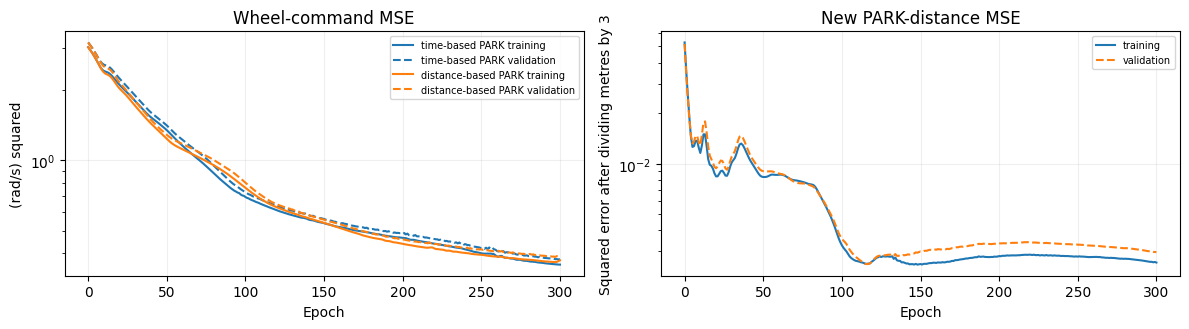

The old time-target loss and new distance-target loss measure different quantities; their magnitudes are not directly comparable.


In [9]:
pd_drive='no_speed11'
pd_h=pd.DataFrame(json.loads((PD/'models'/pd_drive/'driving_seed7_history.json').read_text()))
pd_old_dir='driving_height17' if pd_drive=='height17' else 'driving_height_no_speed11'
pd_old_h=pd.DataFrame(json.loads((PD.parent/pd_old_dir/'models/driving_seed7_history.json').read_text()))
fig,axes=plt.subplots(1,2,figsize=(12,3.4))
for h,label,col in [(pd_old_h,'time-based PARK','tab:blue'),(pd_h,'distance-based PARK','tab:orange')]:
    axes[0].plot(h.epoch,h.train_command,label=label+' training',color=col)
    axes[0].plot(h.epoch,h.val_command,label=label+' validation',color=col,linestyle='--')
axes[1].plot(pd_h.epoch,pd_h.train_aux,label='training')
axes[1].plot(pd_h.epoch,pd_h.val_aux,label='validation',linestyle='--')
axes[0].set(title='Wheel-command MSE',ylabel='(rad/s) squared')
axes[1].set(title='New PARK-distance MSE',ylabel='Squared error after dividing metres by 3')
for ax in axes:ax.set(xlabel='Epoch',yscale='log');ax.grid(alpha=.2);ax.legend(fontsize=7)
fig.tight_layout();plt.show()
print('The old time-target loss and new distance-target loss measure different quantities; their magnitudes are not directly comparable.')

#### Same six full validation episodes


In [10]:
pd_name='no_speed'
display(pd_data[pd_data.variant==pd_name].pivot(index='dot',columns='park_target',values=['parked','stopped','park_cm','closest_mm','at_stop_mm']).round(2))
display(pd_score.loc[pd_name].round(2))

parked        stopped          park_cm             closest_mm  \
park_target distance  time distance  time   distance       time    distance   
dot                                                                           
16              True  True     True  True   9.770025   8.625313  213.089919   
333             True  True     True  True  27.263601  19.349422  288.317551   
506             True  True     True  True   5.486256   3.794478   59.839473   
673             True  True     True  True   1.216561   3.829892  133.725155   
720             True  True     True  True  12.539656   4.053917  117.530617   
830             True  True     True  True   6.962757   4.773166   74.807087   

                          at_stop_mm               
park_target        time     distance         time  
dot                                                
16           155.195436   238.513562   180.319776  
333          213.524927   292.085977   219.279844  
506          130.372783   283.981263   264.934603  
673           163.53819   262.575916   280.200084  
720           24.286698   145.765168    67.248003  
830            30.15105  1138.855675  1134.908278

,attempts,PARK,STOP,median_park_cm,median_closest_mm,median_arm_STOP_mm,success_10mm
park_target,,,,,,,
time,6,6,6,4.41,142.78,242.11,0
distance,6,6,6,8.37,125.63,273.28,0


#### PARK prediction versus actual distance to the expert parking position


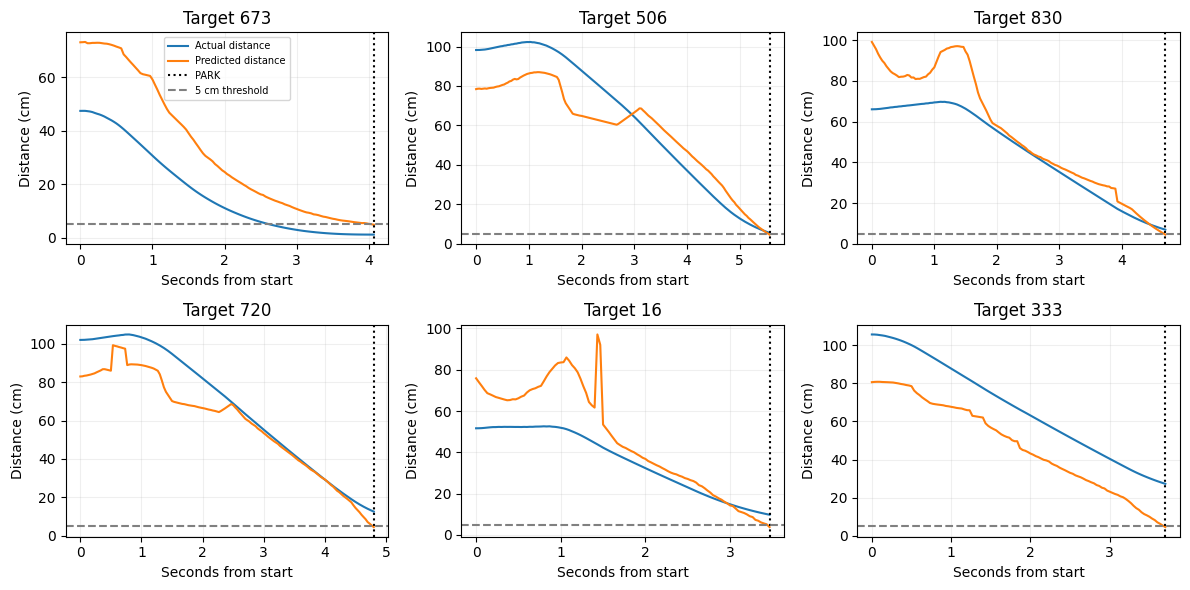

In [11]:
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,dot in zip(axes.flat,pd_config['validation_cases']):
    r=json.loads((PD/'results'/f'no_speed_dot{dot}.json').read_text())
    frames=[f for f in r['frames'] if f.get('driving_park_distance_m') is not None]
    if frames:
        t=[f['time_s'] for f in frames]
        actual=[100*np.linalg.norm(np.array(f['base'][:2])-r['expert_park_base_xy']) for f in frames]
        ax.plot(t,actual,label='Actual distance')
        ax.plot(t,[100*f['driving_park_distance_m'] for f in frames],label='Predicted distance')
    if r['park_s'] is not None:ax.axvline(r['park_s'],color='black',linestyle=':',label='PARK')
    ax.axhline(5,color='grey',linestyle='--',label='5 cm threshold')
    ax.set(title=f'Target {dot}',xlabel='Seconds from start',ylabel='Distance (cm)');ax.grid(alpha=.2)
axes.flat[0].legend(fontsize=7);fig.tight_layout();plt.show()

#### Reaching after the new PARK decision


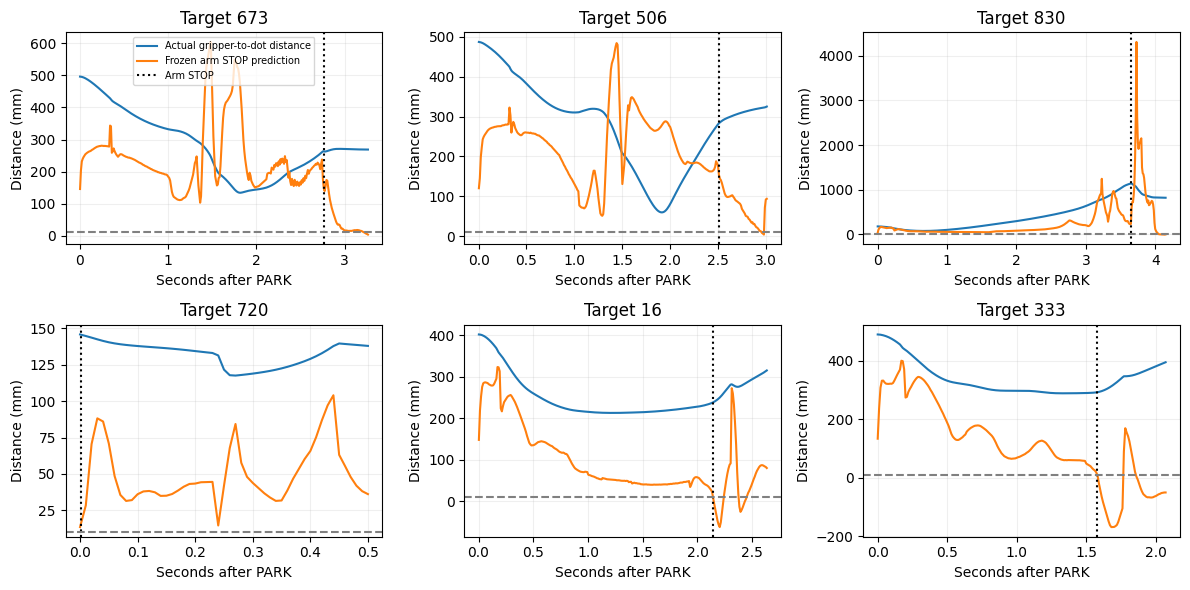

In [12]:
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,dot in zip(axes.flat,pd_config['validation_cases']):
    r=json.loads((PD/'results'/f'no_speed_dot{dot}.json').read_text());d=pd.DataFrame(r['log'])
    if len(d):
        ax.plot(d.t-r['park_s'],d.ee_mm,label='Actual gripper-to-dot distance')
        ax.plot(d.t-r['park_s'],1000*d.ttp_s,label='Frozen arm STOP prediction')
        if r['stop_s'] is not None:ax.axvline(r['stop_s']-r['park_s'],color='black',linestyle=':',label='Arm STOP')
    else:ax.text(.5,.5,'No PARK / no reaching',ha='center',transform=ax.transAxes)
    ax.axhline(10,color='grey',linestyle='--');ax.set(title=f'Target {dot}',xlabel='Seconds after PARK',ylabel='Distance (mm)');ax.grid(alpha=.2)
axes.flat[0].legend(fontsize=7);fig.tight_layout();plt.show()

#### What changed


In [13]:
pd_name='no_speed';before=pd_score.loc[(pd_name,'time')];after=pd_score.loc[(pd_name,'distance')]
pairs=pd_data[pd_data.variant==pd_name].pivot(index='dot',columns='park_target',values='park_cm')
valid=pairs.dropna();improved=int((valid['distance']<valid['time']).sum())
display(Markdown(f"""Changing PARK supervision improved parking error on **{improved}/{len(valid)}** targets with PARK in both conditions. Median parking error changed from **{before.median_park_cm:.1f} to {after.median_park_cm:.1f} cm**; median closest reach from **{before.median_closest_mm:.1f} to {after.median_closest_mm:.1f} mm**; median distance at arm STOP from **{before.median_arm_STOP_mm:.1f} to {after.median_arm_STOP_mm:.1f} mm**.

The distance-based configuration issued PARK on **{int(after.PARK)}/6** and arm STOP on **{int(after.STOP)}/6**, with **{int(after.success_10mm)}/6** within 10 mm at arm STOP. This comparison changes the PARK target and its threshold units, with the same wheel-command loss and arm weights. Both the wheel and PARK heads share a trunk, so retraining can change wheel commands as well as the PARK decision.

The 5 cm threshold was fixed before the runs. Training checkpoints were selected by offline validation loss, not these outcomes. Six initially visible targets and one seed remain a development check; no claim of generalisation follows."""))

Changing PARK supervision improved parking error on **1/6** targets with PARK in both conditions. Median parking error changed from **4.4 to 8.4 cm**; median closest reach from **142.8 to 125.6 mm**; median distance at arm STOP from **242.1 to 273.3 mm**.

The distance-based configuration issued PARK on **6/6** and arm STOP on **6/6**, with **0/6** within 10 mm at arm STOP. This comparison changes the PARK target and its threshold units, with the same wheel-command loss and arm weights. Both the wheel and PARK heads share a trunk, so retraining can change wheel commands as well as the PARK decision.

The 5 cm threshold was fixed before the runs. Training checkpoints were selected by offline validation loss, not these outcomes. Six initially visible targets and one seed remain a development check; no claim of generalisation follows.

### Retain those changes, longer-trained arm


In [14]:
pd_name='longer_arm';pd_drive='no_speed11'
pd_meta=next(r for r in pd_training['variants'] if r['variant']==pd_drive)
display(pd.DataFrame([{k:pd_meta[k] for k in ['variant','selected_epoch','selected_val_loss','train_rows','val_rows','park_distance_scale_m','park_distance_threshold_m']}]))
print('Driving loss = mean wheel-command squared error + mean normalized PARK-distance squared error; each run weighted equally.')
print('Same exact arm checkpoint as this configuration’s preceding time-based PARK comparison; no arm or STOP retraining.')
print('Driving 300 epochs; two 16-unit hidden layers. Sensor inputs only; expert position is used only for the distance label and evaluation.')

,variant,selected_epoch,selected_val_loss,train_rows,val_rows,park_distance_scale_m,park_distance_threshold_m
0,no_speed11,297,0.389133,25928,26428,3.0,0.05


Driving loss = mean wheel-command squared error + mean normalized PARK-distance squared error; each run weighted equally.
Same exact arm checkpoint as this configuration’s preceding time-based PARK comparison; no arm or STOP retraining.
Driving 300 epochs; two 16-unit hidden layers. Sensor inputs only; expert position is used only for the distance label and evaluation.


#### Driving training and validation losses


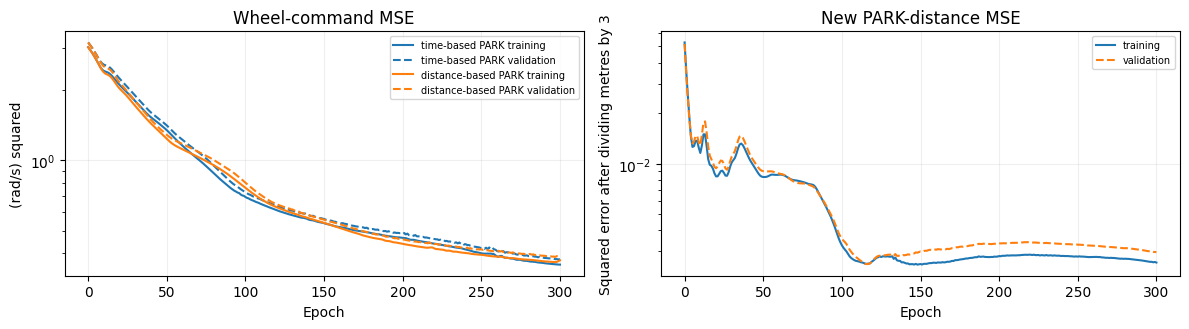

The old time-target loss and new distance-target loss measure different quantities; their magnitudes are not directly comparable.


In [15]:
pd_drive='no_speed11'
pd_h=pd.DataFrame(json.loads((PD/'models'/pd_drive/'driving_seed7_history.json').read_text()))
pd_old_dir='driving_height17' if pd_drive=='height17' else 'driving_height_no_speed11'
pd_old_h=pd.DataFrame(json.loads((PD.parent/pd_old_dir/'models/driving_seed7_history.json').read_text()))
fig,axes=plt.subplots(1,2,figsize=(12,3.4))
for h,label,col in [(pd_old_h,'time-based PARK','tab:blue'),(pd_h,'distance-based PARK','tab:orange')]:
    axes[0].plot(h.epoch,h.train_command,label=label+' training',color=col)
    axes[0].plot(h.epoch,h.val_command,label=label+' validation',color=col,linestyle='--')
axes[1].plot(pd_h.epoch,pd_h.train_aux,label='training')
axes[1].plot(pd_h.epoch,pd_h.val_aux,label='validation',linestyle='--')
axes[0].set(title='Wheel-command MSE',ylabel='(rad/s) squared')
axes[1].set(title='New PARK-distance MSE',ylabel='Squared error after dividing metres by 3')
for ax in axes:ax.set(xlabel='Epoch',yscale='log');ax.grid(alpha=.2);ax.legend(fontsize=7)
fig.tight_layout();plt.show()
print('The old time-target loss and new distance-target loss measure different quantities; their magnitudes are not directly comparable.')

#### Same six full validation episodes


In [16]:
pd_name='longer_arm'
display(pd_data[pd_data.variant==pd_name].pivot(index='dot',columns='park_target',values=['parked','stopped','park_cm','closest_mm','at_stop_mm']).round(2))
display(pd_score.loc[pd_name].round(2))

parked        stopped          park_cm             closest_mm  \
park_target distance  time distance  time   distance       time    distance   
dot                                                                           
16              True  True     True  True   9.770025   8.625313    63.73113   
333             True  True     True  True  27.263601  19.349422  171.606921   
506             True  True     True  True   5.486256   3.794478   91.638974   
673             True  True     True  True   1.216561   3.829892  132.003623   
720             True  True     True  True  12.539656   4.053917   123.49814   
830             True  True     True  True   6.962757   4.773166   36.881058   

                         at_stop_mm              
park_target        time    distance        time  
dot                                              
16           160.513323  234.625192  979.123115  
333           77.435024  341.692854  255.861795  
506          108.908609   547.62502  499.126193  
673          143.458251  399.258634  461.657281  
720           10.527163  145.763484   67.248003  
830           10.447678   772.67333    48.27908

,attempts,PARK,STOP,median_park_cm,median_closest_mm,median_arm_STOP_mm,success_10mm
park_target,,,,,,,
time,6,6,6,4.41,93.17,358.76,0
distance,6,6,6,8.37,107.57,370.48,0


#### PARK prediction versus actual distance to the expert parking position


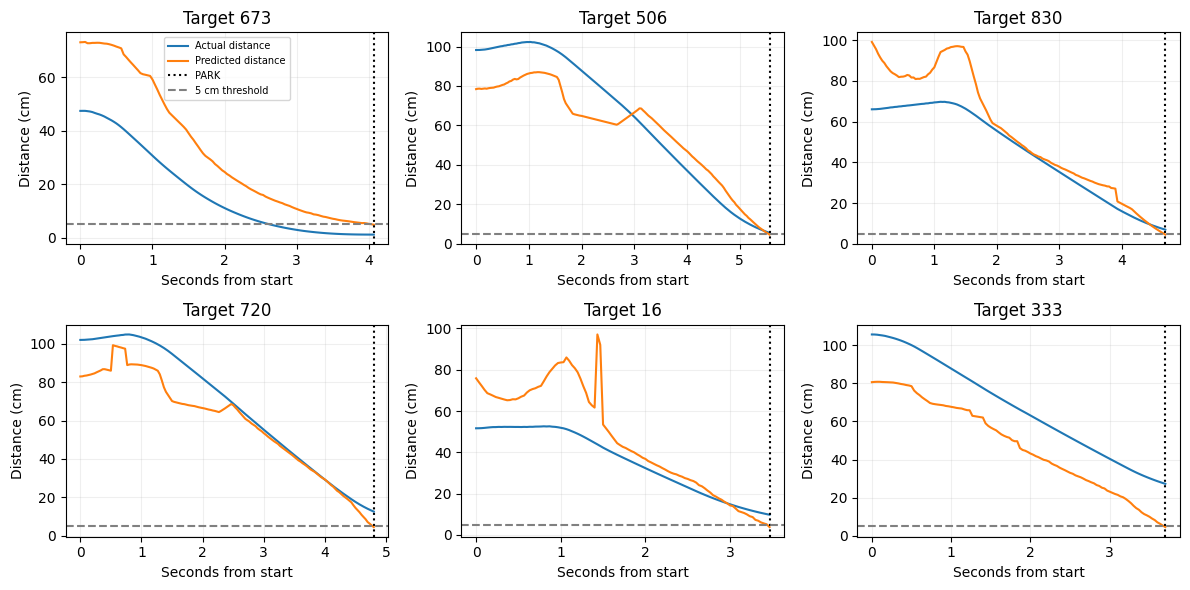

In [17]:
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,dot in zip(axes.flat,pd_config['validation_cases']):
    r=json.loads((PD/'results'/f'longer_arm_dot{dot}.json').read_text())
    frames=[f for f in r['frames'] if f.get('driving_park_distance_m') is not None]
    if frames:
        t=[f['time_s'] for f in frames]
        actual=[100*np.linalg.norm(np.array(f['base'][:2])-r['expert_park_base_xy']) for f in frames]
        ax.plot(t,actual,label='Actual distance')
        ax.plot(t,[100*f['driving_park_distance_m'] for f in frames],label='Predicted distance')
    if r['park_s'] is not None:ax.axvline(r['park_s'],color='black',linestyle=':',label='PARK')
    ax.axhline(5,color='grey',linestyle='--',label='5 cm threshold')
    ax.set(title=f'Target {dot}',xlabel='Seconds from start',ylabel='Distance (cm)');ax.grid(alpha=.2)
axes.flat[0].legend(fontsize=7);fig.tight_layout();plt.show()

#### Reaching after the new PARK decision


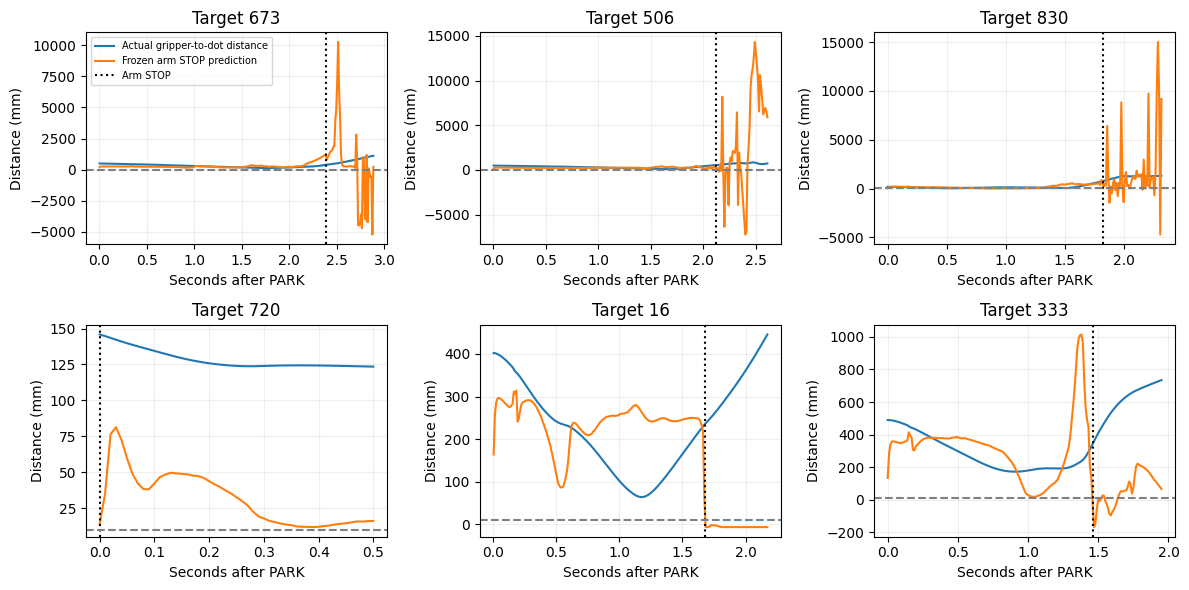

In [18]:
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,dot in zip(axes.flat,pd_config['validation_cases']):
    r=json.loads((PD/'results'/f'longer_arm_dot{dot}.json').read_text());d=pd.DataFrame(r['log'])
    if len(d):
        ax.plot(d.t-r['park_s'],d.ee_mm,label='Actual gripper-to-dot distance')
        ax.plot(d.t-r['park_s'],1000*d.ttp_s,label='Frozen arm STOP prediction')
        if r['stop_s'] is not None:ax.axvline(r['stop_s']-r['park_s'],color='black',linestyle=':',label='Arm STOP')
    else:ax.text(.5,.5,'No PARK / no reaching',ha='center',transform=ax.transAxes)
    ax.axhline(10,color='grey',linestyle='--');ax.set(title=f'Target {dot}',xlabel='Seconds after PARK',ylabel='Distance (mm)');ax.grid(alpha=.2)
axes.flat[0].legend(fontsize=7);fig.tight_layout();plt.show()

#### What changed


In [19]:
pd_name='longer_arm';before=pd_score.loc[(pd_name,'time')];after=pd_score.loc[(pd_name,'distance')]
pairs=pd_data[pd_data.variant==pd_name].pivot(index='dot',columns='park_target',values='park_cm')
valid=pairs.dropna();improved=int((valid['distance']<valid['time']).sum())
display(Markdown(f"""Changing PARK supervision improved parking error on **{improved}/{len(valid)}** targets with PARK in both conditions. Median parking error changed from **{before.median_park_cm:.1f} to {after.median_park_cm:.1f} cm**; median closest reach from **{before.median_closest_mm:.1f} to {after.median_closest_mm:.1f} mm**; median distance at arm STOP from **{before.median_arm_STOP_mm:.1f} to {after.median_arm_STOP_mm:.1f} mm**.

The distance-based configuration issued PARK on **{int(after.PARK)}/6** and arm STOP on **{int(after.STOP)}/6**, with **{int(after.success_10mm)}/6** within 10 mm at arm STOP. This comparison changes the PARK target and its threshold units, with the same wheel-command loss and arm weights. Both the wheel and PARK heads share a trunk, so retraining can change wheel commands as well as the PARK decision.

The 5 cm threshold was fixed before the runs. Training checkpoints were selected by offline validation loss, not these outcomes. Six initially visible targets and one seed remain a development check; no claim of generalisation follows."""))

Changing PARK supervision improved parking error on **1/6** targets with PARK in both conditions. Median parking error changed from **4.4 to 8.4 cm**; median closest reach from **93.2 to 107.6 mm**; median distance at arm STOP from **358.8 to 370.5 mm**.

The distance-based configuration issued PARK on **6/6** and arm STOP on **6/6**, with **0/6** within 10 mm at arm STOP. This comparison changes the PARK target and its threshold units, with the same wheel-command loss and arm weights. Both the wheel and PARK heads share a trunk, so retraining can change wheel commands as well as the PARK decision.

The 5 cm threshold was fixed before the runs. Training checkpoints were selected by offline validation loss, not these outcomes. Six initially visible targets and one seed remain a development check; no claim of generalisation follows.

### Retain those changes, wider arm


In [20]:
pd_name='wider_arm';pd_drive='no_speed11'
pd_meta=next(r for r in pd_training['variants'] if r['variant']==pd_drive)
display(pd.DataFrame([{k:pd_meta[k] for k in ['variant','selected_epoch','selected_val_loss','train_rows','val_rows','park_distance_scale_m','park_distance_threshold_m']}]))
print('Driving loss = mean wheel-command squared error + mean normalized PARK-distance squared error; each run weighted equally.')
print('Same exact arm checkpoint as this configuration’s preceding time-based PARK comparison; no arm or STOP retraining.')
print('Driving 300 epochs; two 16-unit hidden layers. Sensor inputs only; expert position is used only for the distance label and evaluation.')

,variant,selected_epoch,selected_val_loss,train_rows,val_rows,park_distance_scale_m,park_distance_threshold_m
0,no_speed11,297,0.389133,25928,26428,3.0,0.05


Driving loss = mean wheel-command squared error + mean normalized PARK-distance squared error; each run weighted equally.
Same exact arm checkpoint as this configuration’s preceding time-based PARK comparison; no arm or STOP retraining.
Driving 300 epochs; two 16-unit hidden layers. Sensor inputs only; expert position is used only for the distance label and evaluation.


#### Driving training and validation losses


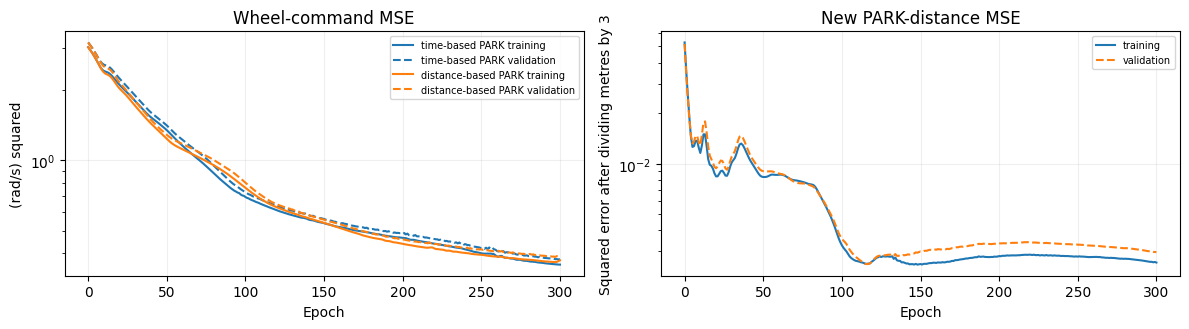

The old time-target loss and new distance-target loss measure different quantities; their magnitudes are not directly comparable.


In [21]:
pd_drive='no_speed11'
pd_h=pd.DataFrame(json.loads((PD/'models'/pd_drive/'driving_seed7_history.json').read_text()))
pd_old_dir='driving_height17' if pd_drive=='height17' else 'driving_height_no_speed11'
pd_old_h=pd.DataFrame(json.loads((PD.parent/pd_old_dir/'models/driving_seed7_history.json').read_text()))
fig,axes=plt.subplots(1,2,figsize=(12,3.4))
for h,label,col in [(pd_old_h,'time-based PARK','tab:blue'),(pd_h,'distance-based PARK','tab:orange')]:
    axes[0].plot(h.epoch,h.train_command,label=label+' training',color=col)
    axes[0].plot(h.epoch,h.val_command,label=label+' validation',color=col,linestyle='--')
axes[1].plot(pd_h.epoch,pd_h.train_aux,label='training')
axes[1].plot(pd_h.epoch,pd_h.val_aux,label='validation',linestyle='--')
axes[0].set(title='Wheel-command MSE',ylabel='(rad/s) squared')
axes[1].set(title='New PARK-distance MSE',ylabel='Squared error after dividing metres by 3')
for ax in axes:ax.set(xlabel='Epoch',yscale='log');ax.grid(alpha=.2);ax.legend(fontsize=7)
fig.tight_layout();plt.show()
print('The old time-target loss and new distance-target loss measure different quantities; their magnitudes are not directly comparable.')

#### Same six full validation episodes


In [22]:
pd_name='wider_arm'
display(pd_data[pd_data.variant==pd_name].pivot(index='dot',columns='park_target',values=['parked','stopped','park_cm','closest_mm','at_stop_mm']).round(2))
display(pd_score.loc[pd_name].round(2))

parked        stopped          park_cm             closest_mm  \
park_target distance  time distance  time   distance       time    distance   
dot                                                                           
16              True  True     True  True   9.770025   8.625313  101.775705   
333             True  True     True  True  27.263601  19.349422     29.0385   
506             True  True     True  True   5.486256   3.794478  218.439542   
673             True  True     True  True   1.216561   3.829892  386.214906   
720             True  True     True  True  12.539656   4.053917  107.976842   
830             True  True     True  True   6.962757   4.773166   46.782024   

                         at_stop_mm              
park_target        time    distance        time  
dot                                              
16            84.106477  304.212378   91.293351  
333           77.947934   37.603724  172.030713  
506          203.376576  283.366232  221.054577  
673          218.119402  391.789289  259.266139  
720           12.345657   145.76135   67.248003  
830           31.331838   55.240336   33.567181

,attempts,PARK,STOP,median_park_cm,median_closest_mm,median_arm_STOP_mm,success_10mm
park_target,,,,,,,
time,6,6,6,4.41,81.03,131.66,0
distance,6,6,6,8.37,104.88,214.56,0


#### PARK prediction versus actual distance to the expert parking position


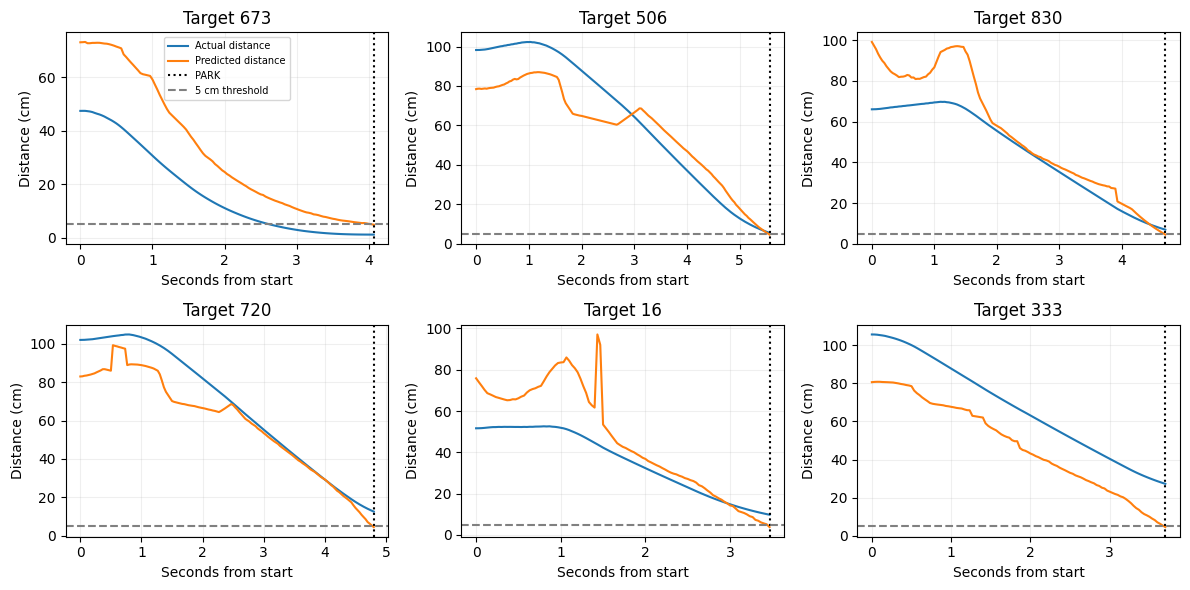

In [23]:
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,dot in zip(axes.flat,pd_config['validation_cases']):
    r=json.loads((PD/'results'/f'wider_arm_dot{dot}.json').read_text())
    frames=[f for f in r['frames'] if f.get('driving_park_distance_m') is not None]
    if frames:
        t=[f['time_s'] for f in frames]
        actual=[100*np.linalg.norm(np.array(f['base'][:2])-r['expert_park_base_xy']) for f in frames]
        ax.plot(t,actual,label='Actual distance')
        ax.plot(t,[100*f['driving_park_distance_m'] for f in frames],label='Predicted distance')
    if r['park_s'] is not None:ax.axvline(r['park_s'],color='black',linestyle=':',label='PARK')
    ax.axhline(5,color='grey',linestyle='--',label='5 cm threshold')
    ax.set(title=f'Target {dot}',xlabel='Seconds from start',ylabel='Distance (cm)');ax.grid(alpha=.2)
axes.flat[0].legend(fontsize=7);fig.tight_layout();plt.show()

#### Reaching after the new PARK decision


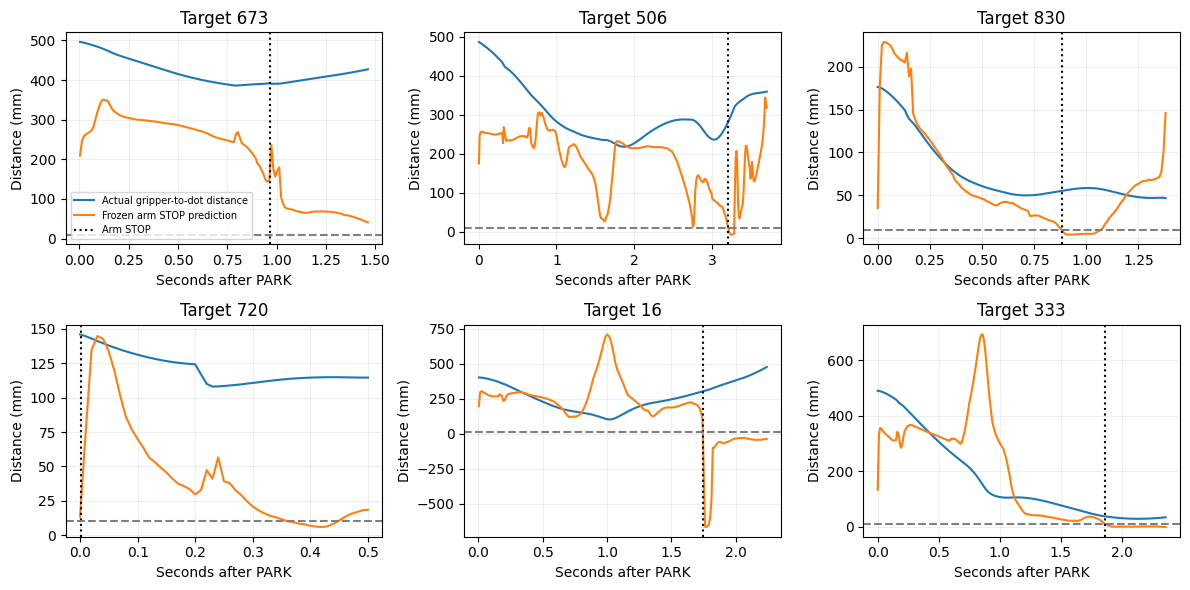

In [24]:
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,dot in zip(axes.flat,pd_config['validation_cases']):
    r=json.loads((PD/'results'/f'wider_arm_dot{dot}.json').read_text());d=pd.DataFrame(r['log'])
    if len(d):
        ax.plot(d.t-r['park_s'],d.ee_mm,label='Actual gripper-to-dot distance')
        ax.plot(d.t-r['park_s'],1000*d.ttp_s,label='Frozen arm STOP prediction')
        if r['stop_s'] is not None:ax.axvline(r['stop_s']-r['park_s'],color='black',linestyle=':',label='Arm STOP')
    else:ax.text(.5,.5,'No PARK / no reaching',ha='center',transform=ax.transAxes)
    ax.axhline(10,color='grey',linestyle='--');ax.set(title=f'Target {dot}',xlabel='Seconds after PARK',ylabel='Distance (mm)');ax.grid(alpha=.2)
axes.flat[0].legend(fontsize=7);fig.tight_layout();plt.show()

#### What changed


In [25]:
pd_name='wider_arm';before=pd_score.loc[(pd_name,'time')];after=pd_score.loc[(pd_name,'distance')]
pairs=pd_data[pd_data.variant==pd_name].pivot(index='dot',columns='park_target',values='park_cm')
valid=pairs.dropna();improved=int((valid['distance']<valid['time']).sum())
display(Markdown(f"""Changing PARK supervision improved parking error on **{improved}/{len(valid)}** targets with PARK in both conditions. Median parking error changed from **{before.median_park_cm:.1f} to {after.median_park_cm:.1f} cm**; median closest reach from **{before.median_closest_mm:.1f} to {after.median_closest_mm:.1f} mm**; median distance at arm STOP from **{before.median_arm_STOP_mm:.1f} to {after.median_arm_STOP_mm:.1f} mm**.

The distance-based configuration issued PARK on **{int(after.PARK)}/6** and arm STOP on **{int(after.STOP)}/6**, with **{int(after.success_10mm)}/6** within 10 mm at arm STOP. This comparison changes the PARK target and its threshold units, with the same wheel-command loss and arm weights. Both the wheel and PARK heads share a trunk, so retraining can change wheel commands as well as the PARK decision.

The 5 cm threshold was fixed before the runs. Training checkpoints were selected by offline validation loss, not these outcomes. Six initially visible targets and one seed remain a development check; no claim of generalisation follows."""))

Changing PARK supervision improved parking error on **1/6** targets with PARK in both conditions. Median parking error changed from **4.4 to 8.4 cm**; median closest reach from **81.0 to 104.9 mm**; median distance at arm STOP from **131.7 to 214.6 mm**.

The distance-based configuration issued PARK on **6/6** and arm STOP on **6/6**, with **0/6** within 10 mm at arm STOP. This comparison changes the PARK target and its threshold units, with the same wheel-command loss and arm weights. Both the wheel and PARK heads share a trunk, so retraining can change wheel commands as well as the PARK decision.

The 5 cm threshold was fixed before the runs. Training checkpoints were selected by offline validation loss, not these outcomes. Six initially visible targets and one seed remain a development check; no claim of generalisation follows.

## Development check: tenfold PARK-distance loss weight

Plan recorded before training. Test only the first proposed intervention: increase the normalized PARK-distance MSE coefficient from 1 to 10, retaining wheel-command MSE coefficient 1. No near-completion resampling, new head, new input, history, threshold adjustment or training-budget change.

Use the current 11-input no-speed driving model, two 16-unit layers, seed 7, 300 epochs, FP32 and Adam 0.01, with the same 100 training/100 validation runs. Start from the same seeded initialization. Select the checkpoint with minimum weighted total validation loss. Save raw component losses and the weighted total separately; totals with different weights are not directly comparable. Labels remain horizontal distance to the expert PARK base position, clipped at 3 metres and divided by 3. The runtime PARK threshold stays 5 cm.

Freeze the wider arm checkpoint and its separate STOP network from the preceding distance-PARK comparison. Evaluate only six full validation episodes from the normal start: 673, 506, 830, 720, 16, 333. Compare against the six saved weight-1 wider-arm runs. This fixes arm weights while changing only the driving loss coefficient. Camera and driving remain at 30 Hz, arm torque and physics at 1 kHz, with unchanged rendering, sensor models, clipping and deadlines. The test set remains untouched.

Hypothesis: increasing PARK's influence may reduce actual parking error from the weight-1 median of 8.4 cm, without increasing non-parks. Equal or worse median parking error does not support that improvement on this screen. A lower PARK prediction loss alone does not establish better driving. Report raw wheel/PARK validation losses, all six PARK/STOP outcomes, actual parking and gripper distances. No official iteration, MLflow run or validation animation. Preserve the preceding 166 notebook cells.


### PARK weight 10 versus weight 1


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
PW=Path('../arm/results/park_weight10');PW_BASE=PW.parent/'park_distance_four'
pw_config=json.loads((PW/'config.json').read_text());pw_training=json.loads((PW/'training_summary.json').read_text())
pw_rows=[dict(r,weight=1) for r in json.loads((PW_BASE/'results/summary.json').read_text()) if r['variant']=='wider_arm']
pw_rows += [dict(r,weight=10) for r in json.loads((PW/'results/summary.json').read_text())]
pw_data=pd.DataFrame([dict(weight=r['weight'],dot=r['dot'],PARK=r['parked'],STOP=r['stop_s'] is not None,park_cm=100*r['park_error_vs_expert_m'] if r['parked'] else np.nan,closest_mm=r['min_mm'],arm_STOP_mm=r['at_network_stop_mm'],success=r['success']) for r in pw_rows])
assert len(pw_data)==12 and pw_data.groupby('weight').size().eq(6).all()
pw_score=pw_data.groupby('weight').agg(attempts=('dot','size'),PARK=('PARK','sum'),STOP=('STOP','sum'),median_park_cm=('park_cm','median'),median_closest_mm=('closest_mm','median'),median_arm_STOP_mm=('arm_STOP_mm','median'),within_10mm=('success','sum'))
display(pw_score.round(2))
print('New training/loading %.1f s; six full simulations %.1f s' % (pw_training['elapsed_s'],json.loads((PW/'results/completion.json').read_text())['elapsed_s']))
print('Seed 7, 300 epochs, 11 sensor inputs, 16/16 hidden layers, 5 cm PARK threshold; exact wider arm and STOP checkpoint unchanged.')
print('Selected epoch:',pw_training['variants'][0]['selected_epoch'])
print('Closest distance includes the 0.5-second observation after arm STOP. Missing PARK/STOP values remain in counts, but are omitted from their distance medians.')

,attempts,PARK,STOP,median_park_cm,median_closest_mm,median_arm_STOP_mm,within_10mm
weight,,,,,,,
1,6,6,6,8.37,104.88,214.56,0
10,6,6,6,11.11,113.23,220.63,0


New training/loading 11.8 s; six full simulations 22.5 s
Seed 7, 300 epochs, 11 sensor inputs, 16/16 hidden layers, 5 cm PARK threshold; exact wider arm and STOP checkpoint unchanged.
Selected epoch: 300
Closest distance includes the 0.5-second observation after arm STOP. Missing PARK/STOP values remain in counts, but are omitted from their distance medians.


#### Raw training and validation losses


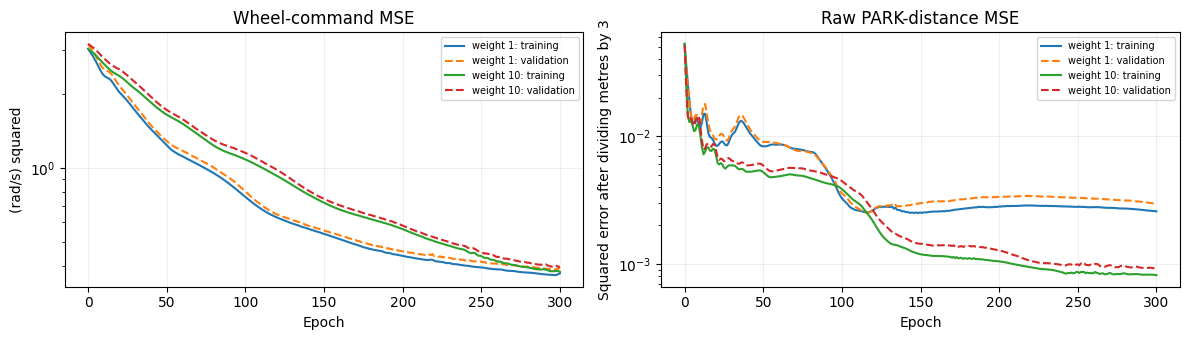

,weight,epoch,val_wheel_MSE,val_raw_PARK_MSE,val_weighted_total
0,1,297,0.386144,0.002990,0.389133
1,10,300,0.396763,0.000919,0.405955


Raw component losses are comparable; total loss has a different coefficient and is not directly comparable across weights.


In [2]:
pw_hist={weight:pd.DataFrame(json.loads((root/'models/no_speed11/driving_seed7_history.json').read_text())) for weight,root in [(1,PW_BASE),(10,PW)]}
fig,axes=plt.subplots(1,2,figsize=(12,3.5))
for weight,h in pw_hist.items():
    for ax,field in zip(axes,['command','aux']):
        ax.plot(h.epoch,h['train_'+field],label=f'weight {weight}: training')
        ax.plot(h.epoch,h['val_'+field],linestyle='--',label=f'weight {weight}: validation')
axes[0].set(title='Wheel-command MSE',ylabel='(rad/s) squared');axes[1].set(title='Raw PARK-distance MSE',ylabel='Squared error after dividing metres by 3')
for ax in axes:ax.set(xlabel='Epoch',yscale='log');ax.grid(alpha=.2);ax.legend(fontsize=7)
fig.tight_layout();plt.show()
pw_losses=[]
for weight,root in [(1,PW_BASE),(10,PW)]:
    m=json.loads((root/'models/no_speed11/driving_seed7_summary.json').read_text());r=pw_hist[weight].set_index('epoch').loc[m['selected_epoch']]
    pw_losses.append(dict(weight=weight,epoch=m['selected_epoch'],val_wheel_MSE=r.val_command,val_raw_PARK_MSE=r.val_aux,val_weighted_total=r.val_total))
display(pd.DataFrame(pw_losses))
print('Raw component losses are comparable; total loss has a different coefficient and is not directly comparable across weights.')

#### Paired outcomes for the same six targets


In [3]:
display(pw_data.pivot(index='dot',columns='weight',values=['PARK','STOP','park_cm','closest_mm','arm_STOP_mm']).round(2))
pw_pairs=pw_data.pivot(index='dot',columns='weight',values='park_cm').dropna()
print('Parking error improved on %d/%d targets with PARK in both conditions.' % ((pw_pairs[10]<pw_pairs[1]).sum(),len(pw_pairs)))

PARK        STOP          park_cm             closest_mm              \
weight    1     10    1     10         1          10          1           10   
dot                                                                            
16      True  True  True  True   9.770025  11.909654  101.775705  166.727325   
333     True  True  True  True  27.263601  37.683314     29.0385   99.615567   
506     True  True  True  True   5.486256   9.487884  218.439542    361.7784   
673     True  True  True  True   1.216561   6.579514  386.214906   42.549489   
720     True  True  True  True  12.539656   19.27331  107.976842  126.841199   
830     True  True  True  True   6.962757  10.302678   46.782024   60.660075   

       arm_STOP_mm              
weight          1           10  
dot                             
16      304.212378  358.559072  
333      37.603724  101.839256  
506     283.366232  454.042391  
673     391.789289  276.708852  
720      145.76135  164.552413  
830      55.240336   78.738578

Parking error improved on 0/6 targets with PARK in both conditions.


#### PARK predictions versus actual remaining distance


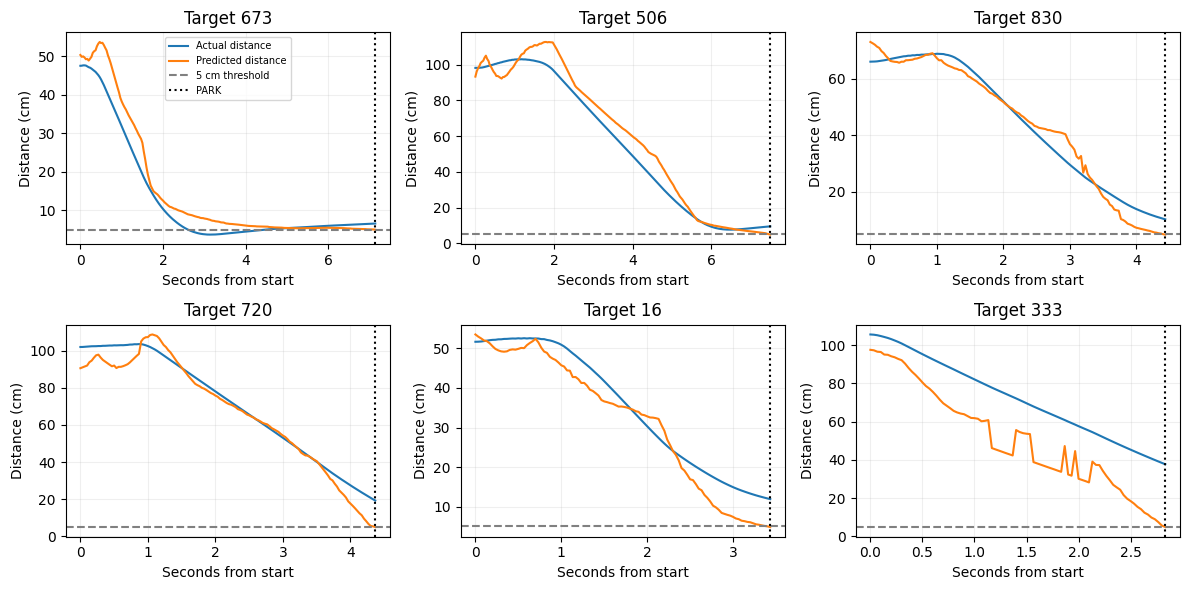

In [4]:
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,dot in zip(axes.flat,pw_config['validation_cases']):
    r=json.loads((PW/'results'/f'wider_arm_dot{dot}.json').read_text())
    f=[f for f in r['frames'] if f.get('driving_park_distance_m') is not None]
    ax.plot([x['time_s'] for x in f],[100*np.linalg.norm(np.array(x['base'][:2])-r['expert_park_base_xy']) for x in f],label='Actual distance')
    ax.plot([x['time_s'] for x in f],[100*x['driving_park_distance_m'] for x in f],label='Predicted distance')
    ax.axhline(5,color='grey',linestyle='--',label='5 cm threshold')
    if r['park_s'] is not None:ax.axvline(r['park_s'],color='black',linestyle=':',label='PARK')
    ax.set(title=f'Target {dot}',xlabel='Seconds from start',ylabel='Distance (cm)');ax.grid(alpha=.2)
axes.flat[0].legend(fontsize=7);fig.tight_layout();plt.show()

#### Reaching with the unchanged arm checkpoint


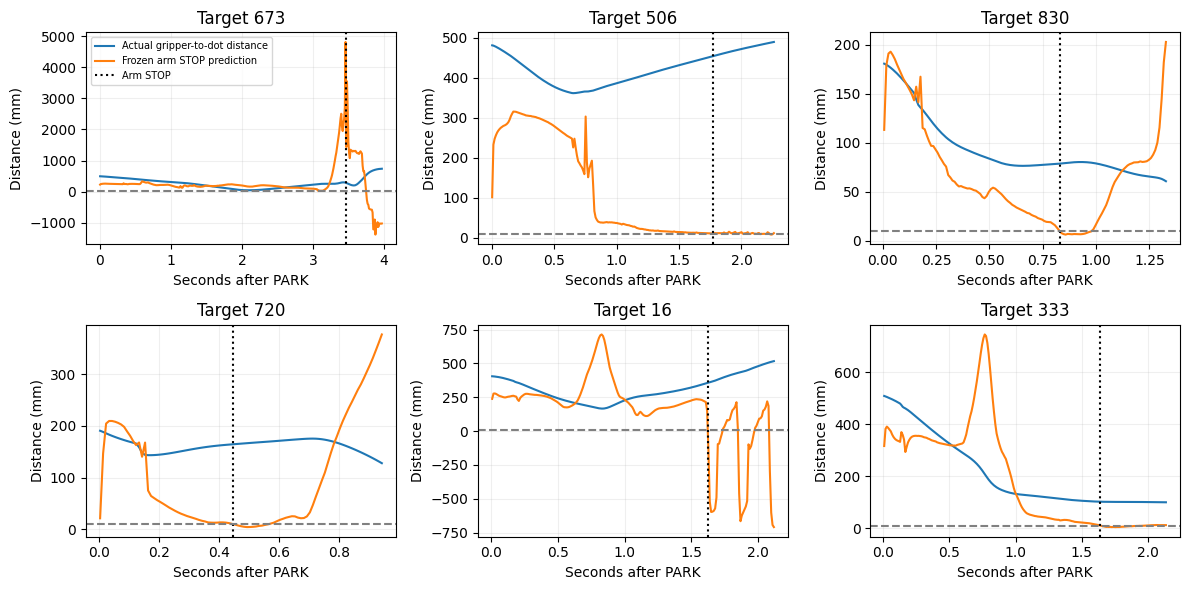

In [5]:
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,dot in zip(axes.flat,pw_config['validation_cases']):
    r=json.loads((PW/'results'/f'wider_arm_dot{dot}.json').read_text());d=pd.DataFrame(r['log'])
    if not len(d):ax.text(.5,.5,'No PARK / no reaching',ha='center',transform=ax.transAxes);ax.set_title(f'Target {dot}');ax.set_axis_off();continue
    ax.plot(d.t-r['park_s'],d.ee_mm,label='Actual gripper-to-dot distance')
    ax.plot(d.t-r['park_s'],1000*d.ttp_s,label='Frozen arm STOP prediction')
    if r['stop_s'] is not None:ax.axvline(r['stop_s']-r['park_s'],color='black',linestyle=':',label='Arm STOP')
    ax.axhline(10,color='grey',linestyle='--');ax.set(title=f'Target {dot}',xlabel='Seconds after PARK',ylabel='Distance (mm)');ax.grid(alpha=.2)
for ax in axes.flat:
    if ax.get_legend_handles_labels()[0]:ax.legend(fontsize=7);break
fig.tight_layout();plt.show()

#### Reading this single-change experiment


In [6]:
b=pw_score.loc[1];c=pw_score.loc[10]
display(Markdown(f"""Increasing the PARK-distance coefficient from 1 to 10 changed median parking error from **{b.median_park_cm:.1f} to {c.median_park_cm:.1f} cm**. The new model issued PARK in **{int(c.PARK)}/6** and arm STOP in **{int(c.STOP)}/6** runs. Median closest reach changed from **{b.median_closest_mm:.1f} to {c.median_closest_mm:.1f} mm**, and median distance at arm STOP from **{b.median_arm_STOP_mm:.1f} to {c.median_arm_STOP_mm:.1f} mm**. Success within 10 mm at arm STOP was **{int(c.within_10mm)}/6**.

Only the driving loss coefficient changed. The shared trunk means this can alter wheel commands as well as PARK predictions. The arm weights stayed identical; changes in reaching reflect a different handover and subsequent trajectory. Neither the 5 cm threshold nor the training budget was adjusted after these results. The six cases are initially visible validation targets and use one seed, so this is a development comparison, not a generalisation result. No official MLflow run or reserved-test evaluation was created."""))

Increasing the PARK-distance coefficient from 1 to 10 changed median parking error from **8.4 to 11.1 cm**. The new model issued PARK in **6/6** and arm STOP in **6/6** runs. Median closest reach changed from **104.9 to 113.2 mm**, and median distance at arm STOP from **214.6 to 220.6 mm**. Success within 10 mm at arm STOP was **0/6**.

Only the driving loss coefficient changed. The shared trunk means this can alter wheel commands as well as PARK predictions. The arm weights stayed identical; changes in reaching reflect a different handover and subsequent trajectory. Neither the 5 cm threshold nor the training budget was adjusted after these results. The six cases are initially visible validation targets and use one seed, so this is a development comparison, not a generalisation result. No official MLflow run or reserved-test evaluation was created.

### Development checks: half-metre PARK labels, then longer driving training

Plan recorded before training: use the 11-input no-wheel-speed driving model, seed 7, 16/16 hidden layers, Adam 0.01, equal weight per run and unchanged wider arm plus STOP checkpoint. Both full runs retain camera/driving at 30 Hz and arm torque/physics at 1 kHz.

1. Clip PARK labels at 0.5 m instead of 3 m and divide by 0.5; restore loss weight to 1. Train 300 epochs. The physical PARK threshold remains 5 cm, now 0.1 in output units.
2. Keep that setup and extend driving training to 1,000 epochs, selecting the lowest total validation loss. Retrain with the same seed so the first 300 updates can be checked against the first experiment.

Both use 100 training trajectories and 100 offline validation trajectories, followed by the same six full validation episodes (673, 506, 830, 720, 16, 333). No test trajectories, animations or official MLflow iterations.

Prediction supplied before training: the first change raises accurate first PARK triggers within 5 cm from 38 to above 70 of 100 validation trajectories and reduces live median parking error from 8.4 to about 5 cm. Longer training is expected to add a smaller gain. If offline prediction improves without live parking improving, this would motivate investigating wheel commands and unfamiliar trajectory states; it would not by itself identify the cause. Changing the target scale also changes its effective squared-error weight in metre units, so this is not independent of loss balance.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
PC_ROOT=Path('../arm/results')
pc_names=['park_distance_four','park_weight10','park_clip05_e300','park_clip05_e1000']
pc_labels=['3 m, 300 epochs, weight 1','3 m, 300 epochs, weight 10','0.5 m, 300 epochs, weight 1','0.5 m, 1000 epochs, weight 1']
pc_scores=[]
for name,label in zip(pc_names,pc_labels):
    root=PC_ROOT/name
    rs=[r for r in json.loads((root/'results/summary.json').read_text()) if r['variant']=='wider_arm']
    m=json.loads((root/'models/no_speed11/driving_seed7_summary.json').read_text())
    pc_scores.append(dict(model=label,selected_epoch=m['selected_epoch'],PARK=sum(r['parked'] for r in rs),STOP=sum(r['stop_s'] is not None for r in rs),park_cm=np.median([r['park_error_vs_expert_m']*100 for r in rs if r['parked']]),closest_mm=np.median([r['min_mm'] for r in rs if r['parked']]),arm_STOP_mm=np.median([r['at_network_stop_mm'] for r in rs if r['stop_s'] is not None]),success_10mm=sum(r['success'] for r in rs)))
display(pd.DataFrame(pc_scores).round(2))
print('Six full validation episodes per new model; one seed. Same frozen wider arm and separate STOP checkpoint.')

,model,selected_epoch,PARK,STOP,park_cm,closest_mm,arm_STOP_mm,success_10mm
0,"3 m, 300 epochs, weight 1",297,6,6,8.37,104.88,214.56,0
1,"3 m, 300 epochs, weight 10",300,6,6,11.11,113.23,220.63,0
2,"0.5 m, 300 epochs, weight 1",300,6,6,6.68,91.23,108.09,0
3,"0.5 m, 1000 epochs, weight 1",993,5,5,6.81,64.02,185.35,0


Six full validation episodes per new model; one seed. Same frozen wider arm and separate STOP checkpoint.


### Half-metre PARK target: 300 driving epochs


In [2]:
PC=PC_ROOT/'park_clip05_e300'
pc_config=json.loads((PC/'config.json').read_text());pc_train=json.loads((PC/'training_summary.json').read_text())
pc_model=json.loads((PC/'models/no_speed11/driving_seed7_summary.json').read_text())
pc_history=pd.DataFrame(json.loads((PC/'models/no_speed11/driving_seed7_history.json').read_text()))
pc_rows=json.loads((PC/'results/summary.json').read_text())
display(pd.DataFrame([dict(dot=r['dot'],PARK=r['parked'],STOP=r['stop_s'] is not None,park_cm=r['park_error_vs_expert_m']*100 if r['parked'] else np.nan,closest_mm=r['min_mm'],arm_STOP_mm=r['at_network_stop_mm']) for r in pc_rows]).round(2))
print('Selected epoch',pc_model['selected_epoch'],'of 300; training including loading %.1f s; six simulations %.1f s' % (pc_train['elapsed_s'],json.loads((PC/'results/completion.json').read_text())['elapsed_s']))
print('Input: 11 sensor features. Hidden layers: 16/16. Loss: wheel MSE + normalized PARK-distance MSE. Threshold: 5 cm.')

,dot,PARK,STOP,park_cm,closest_mm,arm_STOP_mm
0,673,True,True,5.11,116.68,233.53
1,506,True,True,6.70,262.55,385.67
2,830,True,True,5.54,49.98,54.64
3,720,True,True,6.66,40.76,86.91
4,16,True,True,8.10,104.82,104.82
5,333,True,True,22.88,77.63,111.35


Selected epoch 300 of 300; training including loading 11.7 s; six simulations 20.5 s
Input: 11 sensor features. Hidden layers: 16/16. Loss: wheel MSE + normalized PARK-distance MSE. Threshold: 5 cm.


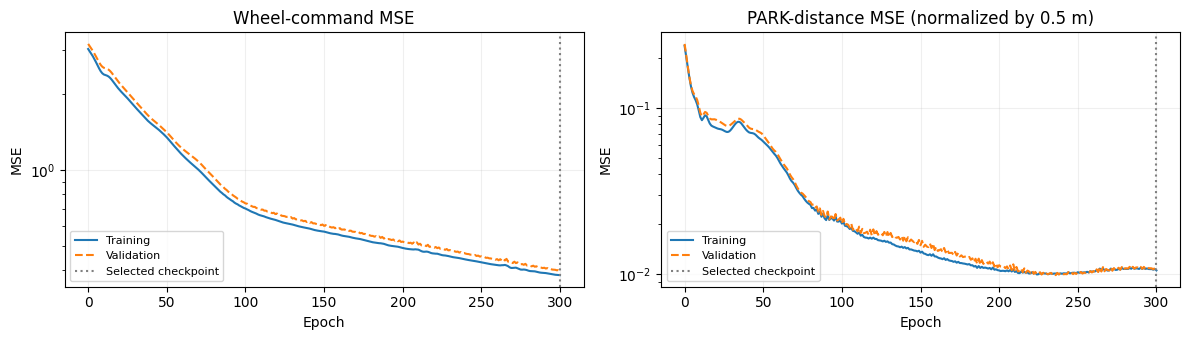

,train_command,train_aux,train_total,val_command,val_aux,val_total,seconds
epoch,,,,,,,
0,3.035195,0.237454,3.272648,3.180272,0.243928,3.424199,0.112749
300,0.381578,0.010516,0.392095,0.397223,0.010571,0.407794,0.003629


Normalized PARK MSE is not directly comparable to the 3 m target. Use physical prediction errors below.


In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,3.5))
for ax,key,title in zip(axes,['command','aux'],['Wheel-command MSE','PARK-distance MSE (normalized by 0.5 m)']):
    ax.plot(pc_history.epoch,pc_history['train_'+key],label='Training')
    ax.plot(pc_history.epoch,pc_history['val_'+key],linestyle='--',label='Validation')
    ax.axvline(pc_model['selected_epoch'],linestyle=':',color='grey',label='Selected checkpoint')
    ax.set(title=title,xlabel='Epoch',ylabel='MSE',yscale='log');ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.tight_layout();plt.show()
display(pc_history.set_index('epoch').loc[[0,300,pc_model['selected_epoch']]].drop_duplicates())
print('Normalized PARK MSE is not directly comparable to the 3 m target. Use physical prediction errors below.')

In [4]:
pc_audit=json.loads((PC/'offline_audit.json').read_text())
pc_offline=pd.DataFrame(pc_audit['summary'])
display(pc_offline[['model','runs','ever_trigger','within_5cm','over_10cm','median_actual_at_trigger_m','mean_run_near_mae_m']].round(4))
print('First-trigger counts use all 100 recorded validation trajectories. No trigger counts as a failure. Near-PARK MAE is an equal-run mean before the expert PARK step.')
print('Checks:',pc_audit['checks'])

,model,runs,ever_trigger,within_5cm,over_10cm,median_actual_at_trigger_m,mean_run_near_mae_m
0,park_distance_four,100,94,38,17,0.0598,0.0567
1,park_weight10,100,98,62,17,0.0130,0.0465
2,park_clip05_e300,100,98,60,8,0.0342,0.0314
3,park_clip05_e1000,100,100,37,12,0.0662,0.0182


First-trigger counts use all 100 recorded validation trajectories. No trigger counts as a failure. Near-PARK MAE is an equal-run mean before the expert PARK step.
Checks: {'first_300_updates_max_difference': 0.0, 'frozen_arm_identical': True, 'checkpoint_selection_verified': True, 'test_trajectories_opened': 0}


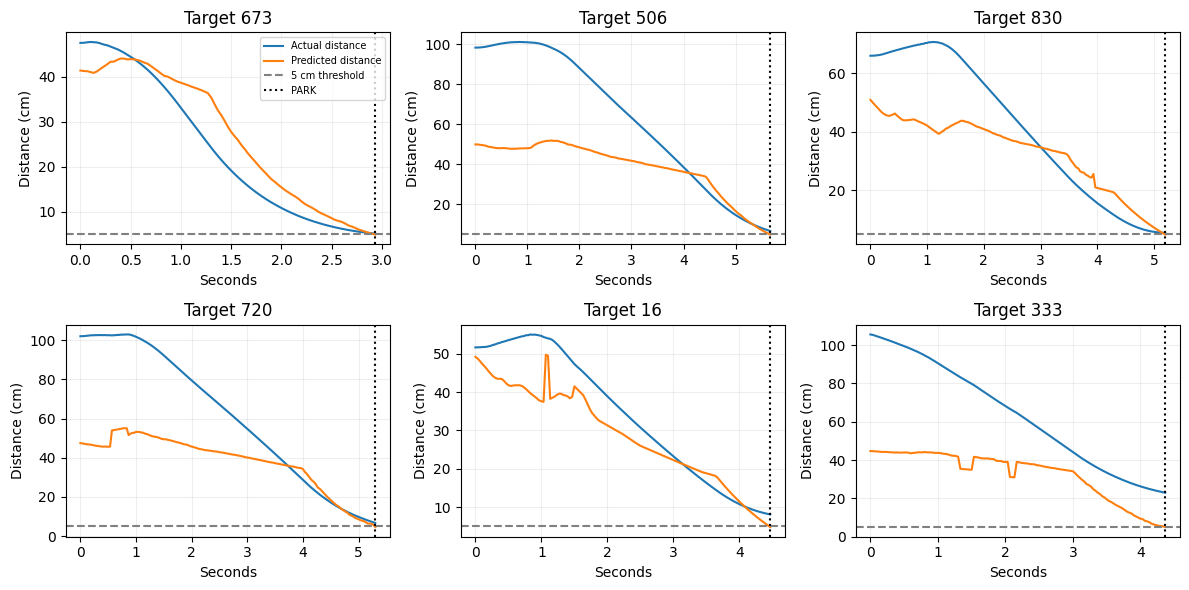

In [5]:
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,dot in zip(axes.flat,pc_config['validation_cases']):
    r=json.loads((PC/'results'/f'wider_arm_dot{dot}.json').read_text())
    f=[x for x in r['frames'] if x.get('driving_park_distance_m') is not None]
    ax.plot([x['time_s'] for x in f],[100*np.linalg.norm(np.array(x['base'][:2])-r['expert_park_base_xy']) for x in f],label='Actual distance')
    ax.plot([x['time_s'] for x in f],[100*x['driving_park_distance_m'] for x in f],label='Predicted distance')
    ax.axhline(5,color='grey',linestyle='--',label='5 cm threshold')
    if r['park_s'] is not None:ax.axvline(r['park_s'],color='black',linestyle=':',label='PARK')
    ax.set(title=f'Target {dot}',xlabel='Seconds',ylabel='Distance (cm)');ax.grid(alpha=.2)
axes.flat[0].legend(fontsize=7);fig.tight_layout();plt.show()

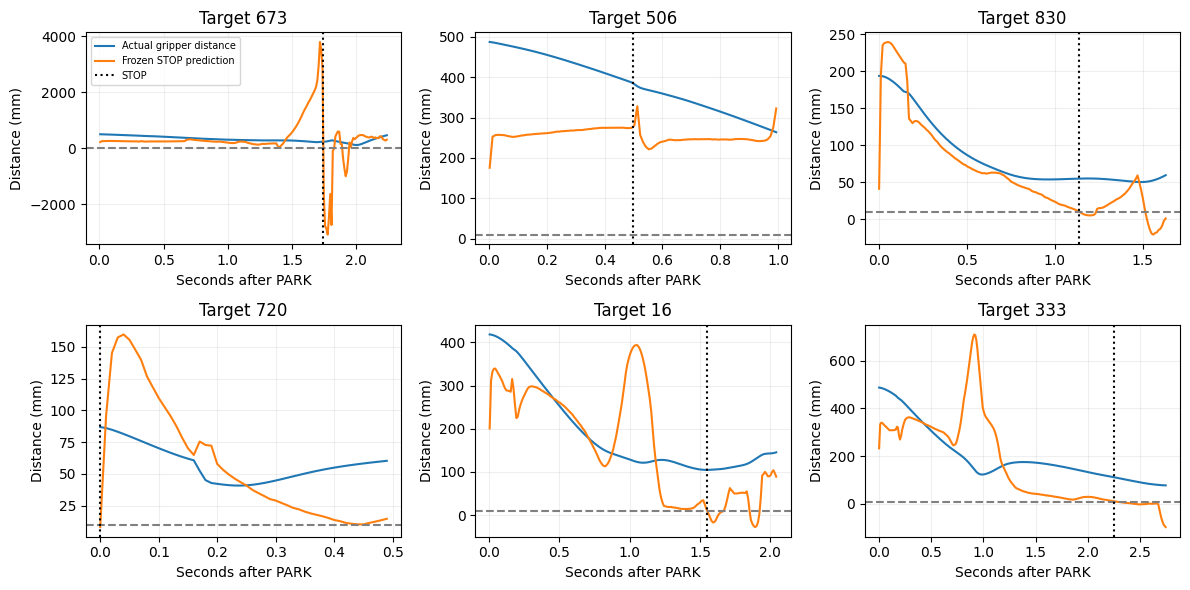

Arm weights are unchanged. The traces include 0.5 seconds after STOP with learned holding torques. Closest distance includes that period; distance at STOP does not.


In [6]:
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,dot in zip(axes.flat,pc_config['validation_cases']):
    r=json.loads((PC/'results'/f'wider_arm_dot{dot}.json').read_text());d=pd.DataFrame(r['log'])
    if not len(d):ax.set_title(f'Target {dot}: no reaching');continue
    ax.plot(d.t-r['park_s'],d.ee_mm,label='Actual gripper distance')
    ax.plot(d.t-r['park_s'],1000*d.ttp_s,label='Frozen STOP prediction')
    ax.axhline(10,color='grey',linestyle='--')
    if r['stop_s'] is not None:ax.axvline(r['stop_s']-r['park_s'],color='black',linestyle=':',label='STOP')
    ax.set(title=f'Target {dot}',xlabel='Seconds after PARK',ylabel='Distance (mm)');ax.grid(alpha=.2)
axes.flat[0].legend(fontsize=7);fig.tight_layout();plt.show()
print('Arm weights are unchanged. The traces include 0.5 seconds after STOP with learned holding torques. Closest distance includes that period; distance at STOP does not.')

### Half-metre PARK target: 1000 driving epochs


In [7]:
PC=PC_ROOT/'park_clip05_e1000'
pc_config=json.loads((PC/'config.json').read_text());pc_train=json.loads((PC/'training_summary.json').read_text())
pc_model=json.loads((PC/'models/no_speed11/driving_seed7_summary.json').read_text())
pc_history=pd.DataFrame(json.loads((PC/'models/no_speed11/driving_seed7_history.json').read_text()))
pc_rows=json.loads((PC/'results/summary.json').read_text())
display(pd.DataFrame([dict(dot=r['dot'],PARK=r['parked'],STOP=r['stop_s'] is not None,park_cm=r['park_error_vs_expert_m']*100 if r['parked'] else np.nan,closest_mm=r['min_mm'],arm_STOP_mm=r['at_network_stop_mm']) for r in pc_rows]).round(2))
print('Selected epoch',pc_model['selected_epoch'],'of 1000; training including loading %.1f s; six simulations %.1f s' % (pc_train['elapsed_s'],json.loads((PC/'results/completion.json').read_text())['elapsed_s']))
print('Input: 11 sensor features. Hidden layers: 16/16. Loss: wheel MSE + normalized PARK-distance MSE. Threshold: 5 cm.')

,dot,PARK,STOP,park_cm,closest_mm,arm_STOP_mm
0,673,True,True,6.41,240.58,263.85
1,506,True,True,6.81,141.76,185.35
2,830,False,False,NaN,NaN,NaN
3,720,True,True,5.86,40.93,85.05
4,16,True,True,7.43,64.02,266.35
5,333,True,True,21.28,44.04,76.54


Selected epoch 993 of 1000; training including loading 14.6 s; six simulations 24.8 s
Input: 11 sensor features. Hidden layers: 16/16. Loss: wheel MSE + normalized PARK-distance MSE. Threshold: 5 cm.


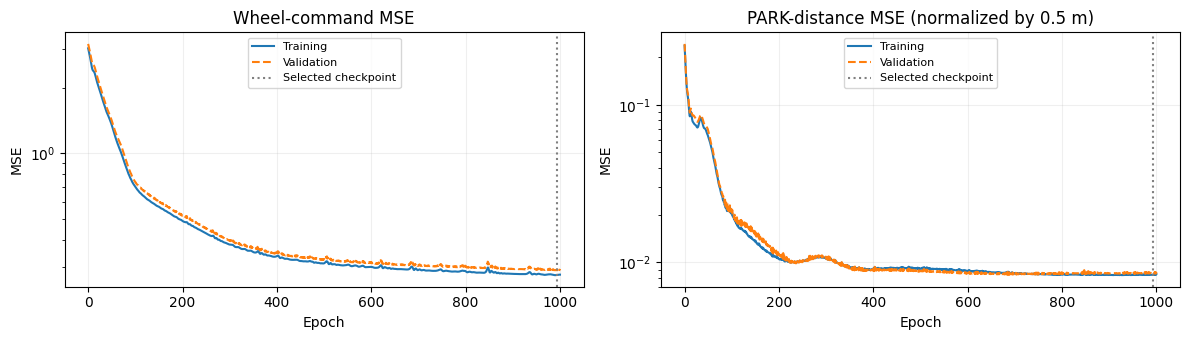

,train_command,train_aux,train_total,val_command,val_aux,val_total,seconds
epoch,,,,,,,
0,3.035195,0.237454,3.272648,3.180272,0.243928,3.424199,0.112354
300,0.381578,0.010516,0.392095,0.397223,0.010571,0.407794,0.002773
993,0.276457,0.008317,0.284774,0.290903,0.008522,0.299425,0.003546


Normalized PARK MSE is not directly comparable to the 3 m target. Use physical prediction errors below.


In [8]:
fig,axes=plt.subplots(1,2,figsize=(12,3.5))
for ax,key,title in zip(axes,['command','aux'],['Wheel-command MSE','PARK-distance MSE (normalized by 0.5 m)']):
    ax.plot(pc_history.epoch,pc_history['train_'+key],label='Training')
    ax.plot(pc_history.epoch,pc_history['val_'+key],linestyle='--',label='Validation')
    ax.axvline(pc_model['selected_epoch'],linestyle=':',color='grey',label='Selected checkpoint')
    ax.set(title=title,xlabel='Epoch',ylabel='MSE',yscale='log');ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.tight_layout();plt.show()
display(pc_history.set_index('epoch').loc[[0,300,pc_model['selected_epoch']]].drop_duplicates())
print('Normalized PARK MSE is not directly comparable to the 3 m target. Use physical prediction errors below.')

In [9]:
pc_audit=json.loads((PC/'offline_audit.json').read_text())
pc_offline=pd.DataFrame(pc_audit['summary'])
display(pc_offline[['model','runs','ever_trigger','within_5cm','over_10cm','median_actual_at_trigger_m','mean_run_near_mae_m']].round(4))
print('First-trigger counts use all 100 recorded validation trajectories. No trigger counts as a failure. Near-PARK MAE is an equal-run mean before the expert PARK step.')
print('Checks:',pc_audit['checks'])

,model,runs,ever_trigger,within_5cm,over_10cm,median_actual_at_trigger_m,mean_run_near_mae_m
0,park_distance_four,100,94,38,17,0.0598,0.0567
1,park_weight10,100,98,62,17,0.0130,0.0465
2,park_clip05_e300,100,98,60,8,0.0342,0.0314
3,park_clip05_e1000,100,100,37,12,0.0662,0.0182


First-trigger counts use all 100 recorded validation trajectories. No trigger counts as a failure. Near-PARK MAE is an equal-run mean before the expert PARK step.
Checks: {'first_300_updates_max_difference': 0.0, 'frozen_arm_identical': True, 'checkpoint_selection_verified': True, 'test_trajectories_opened': 0}


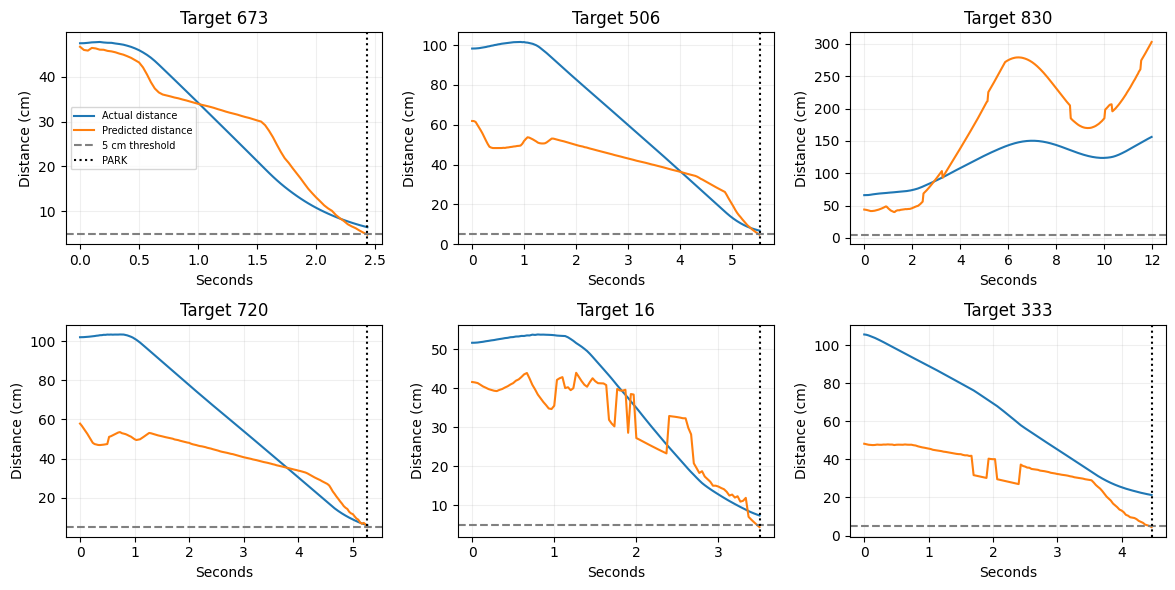

In [10]:
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,dot in zip(axes.flat,pc_config['validation_cases']):
    r=json.loads((PC/'results'/f'wider_arm_dot{dot}.json').read_text())
    f=[x for x in r['frames'] if x.get('driving_park_distance_m') is not None]
    ax.plot([x['time_s'] for x in f],[100*np.linalg.norm(np.array(x['base'][:2])-r['expert_park_base_xy']) for x in f],label='Actual distance')
    ax.plot([x['time_s'] for x in f],[100*x['driving_park_distance_m'] for x in f],label='Predicted distance')
    ax.axhline(5,color='grey',linestyle='--',label='5 cm threshold')
    if r['park_s'] is not None:ax.axvline(r['park_s'],color='black',linestyle=':',label='PARK')
    ax.set(title=f'Target {dot}',xlabel='Seconds',ylabel='Distance (cm)');ax.grid(alpha=.2)
axes.flat[0].legend(fontsize=7);fig.tight_layout();plt.show()

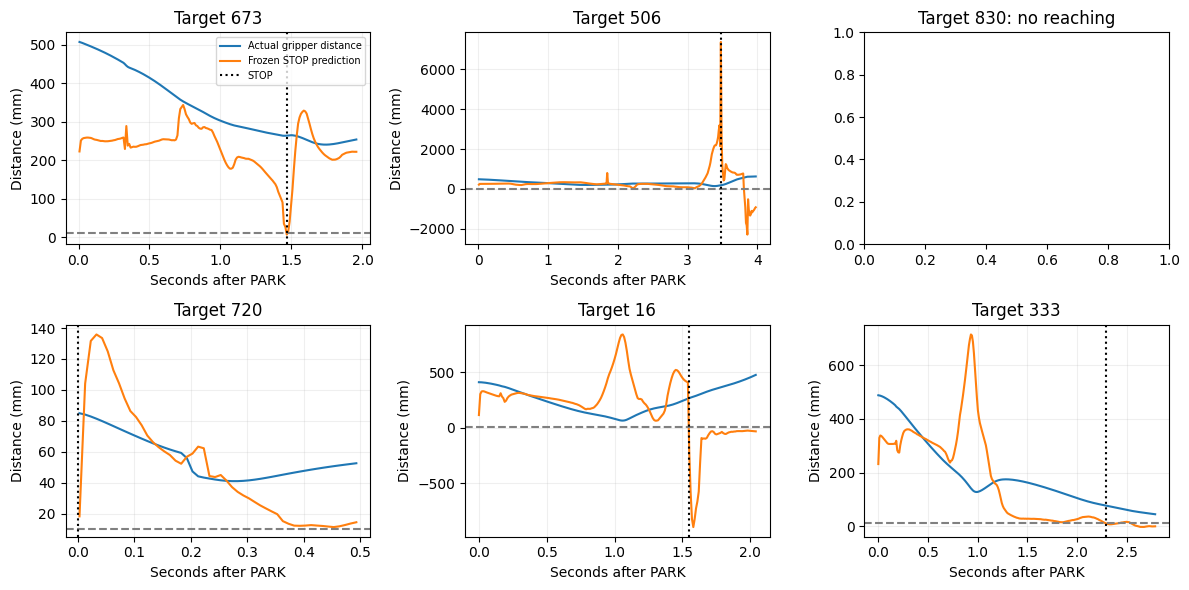

Arm weights are unchanged. The traces include 0.5 seconds after STOP with learned holding torques. Closest distance includes that period; distance at STOP does not.


In [11]:
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,dot in zip(axes.flat,pc_config['validation_cases']):
    r=json.loads((PC/'results'/f'wider_arm_dot{dot}.json').read_text());d=pd.DataFrame(r['log'])
    if not len(d):ax.set_title(f'Target {dot}: no reaching');continue
    ax.plot(d.t-r['park_s'],d.ee_mm,label='Actual gripper distance')
    ax.plot(d.t-r['park_s'],1000*d.ttp_s,label='Frozen STOP prediction')
    ax.axhline(10,color='grey',linestyle='--')
    if r['stop_s'] is not None:ax.axvline(r['stop_s']-r['park_s'],color='black',linestyle=':',label='STOP')
    ax.set(title=f'Target {dot}',xlabel='Seconds after PARK',ylabel='Distance (mm)');ax.grid(alpha=.2)
axes.flat[0].legend(fontsize=7);fig.tight_layout();plt.show()
print('Arm weights are unchanged. The traces include 0.5 seconds after STOP with learned holding torques. Closest distance includes that period; distance at STOP does not.')

### Reading the half-metre and longer-training checks

The original prediction was above 70 accurate first triggers out of 100 recorded validation trajectories. The half-metre target at 300 epochs reaches 60, up from 38, so it improves the result without meeting that prediction. It also reduces first triggers beyond 10 cm from 17 to 8. At 1,000 epochs, accurate first triggers fall to 37 despite a lower mean error near PARK: regression error and a first threshold crossing measure different things.

The two runs share exactly the same first 300 updates, verified from all six raw/total loss fields. The arm checkpoint is identical and the physical PARK threshold is unchanged. The 1,000-epoch model is selected at epoch 993 by total offline validation loss. Changing the target clip alters supervision far from PARK and increases the squared-error contribution of physical errors within the final half metre; this is not a pure change of units.

These are six repeatedly used, initially visible validation targets and one seed. They support a development decision, not a generalisation claim. Keep test data untouched. No new official MLflow runs or replay animations were created.


### Iterations 37 to 40: cumulative time-to-PARK full test plan

Freeze the four existing seed-7 configurations before testing: (37) camera height with original arm; (38) remove six wheel-speed features; (39) retain that driving model and extend arm torque training to 1,200 epochs; (40) widen the arm torque layers to 128/128. Driving remains 300 epochs with wheel MSE plus time-to-PARK MSE, 3-second normalization and a 0.25-second trigger. Arm STOP remains the same separately trained distance network.

Evaluate each on every one of the same 100 test targets, with both learned networks, full camera rendering, 30 Hz camera/driving and 1 kHz arm torque/physics. Keep native arm holding before PARK, fixed fingers, existing encoder quantisation, thresholds and timeouts unchanged. Save camera previews and complete recorded trajectories for all 400 attempts. No search rule, retraining, new seed, noise or threshold adjustment.

The six-case validation results suggested that removing wheel speeds helps parking, longer arm training alone hurts STOP distance, and widening improves it. Test whether those directions persist across all bearings, ranges and heights; do not assume the initially visible six cases predict blind-start behaviour. Report every failure, PARK/STOP counts, parking error, closest reach, distance at STOP and the 10 mm full-task success rate. Missing-event medians are conditional.

These test targets were already used for baseline iterations 34 to 36 and informed earlier diagnosis. This subsequent frozen comparison is not a new blind test. Do not tune these checkpoints from its outcomes. Use original training/validation histories, four official MLflow runs and four selectable animation players, each with ghost expert and camera inset. Previous notebook cells remain unchanged.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
sys.path.insert(0,str(Path('../arm').resolve()))
import report_time_cumulative as tc
# Retain the same click-to-load player used by earlier notebook sections.
import uuid
def lazy_player(url,height=810):
    k=uuid.uuid4().hex[:8]
    return HTML(f"<div><button onclick=\"var f=document.getElementById('player{k}');f.src='{url}';f.style.display='block';this.style.display='none'\" style=\"padding:8px 14px;font-size:14px\">Load the 3D player</button><iframe id=\"player{k}\" style=\"display:none;width:100%;height:{height}px;border:0\"></iframe></div>")
tc_scores=pd.DataFrame(tc.scores())
display(tc_scores[['iteration','change','attempts','parked','stopped','success_10mm','median_park_error_cm','median_closest_mm','median_stop_mm','execution_failures']].round(2))
print('Four frozen seed-7 configurations; all 100 test targets each. No retraining or test-based checkpoint selection.')
print('Test targets were previously used for baseline evaluation; this is not a new blind test.')
print('Total simulation wall time:',json.loads((tc.ROOT/'completion.json').read_text())['elapsed_s'],'seconds')

,iteration,change,attempts,parked,stopped,success_10mm,median_park_error_cm,median_closest_mm,median_stop_mm,execution_failures
0,37,Add camera height,100,87,80,0,18.68,293.53,387.47,0
1,38,Remove wheel-speed inputs,100,100,92,0,5.60,52.50,298.47,0
2,39,Longer arm training,100,100,98,0,5.60,98.26,193.65,0
3,40,Wider arm layers,100,100,96,2,5.60,59.14,85.22,0


Four frozen seed-7 configurations; all 100 test targets each. No retraining or test-based checkpoint selection.
Test targets were previously used for baseline evaluation; this is not a new blind test.
Total simulation wall time: 1132.591391891241 seconds


### Iteration 37: cumulative time-to-PARK height


In [2]:
tc_name='height'
tc_report=tc.select(tc_name)
tc_config=json.loads((tc.ROOT/tc_name/'config.json').read_text())
display(pd.DataFrame([tc_report.score(7)]).round(2))
print('Driving inputs:',tc_config['drive_inputs'],'; arm hidden width:',tc_config['arm_hidden'])
print('PARK: predicted time <= 0.25 s. Arm STOP: predicted gripper distance <= 1 cm. Same thresholds as the validation checks.')
for kind in ['driving','torque','stop']:
    chosen=json.loads((tc.ROOT/tc_name/'models'/f'{kind}_seed7_summary.json').read_text())
    print(kind,': selected epoch',chosen['selected_epoch'],'; original training rows',chosen['train_rows'],'; validation rows',chosen['val_rows'])

,seed,attempts,parked,stopped,success_10mm,success_percent,wilson95_low_percent,wilson95_high_percent,median_park_error_cm,median_abs_heading_error_deg,median_closest_mm,median_stop_mm,median_park_s,median_stop_s,timeouts,execution_failures,sum_case_wall_s,median_case_wall_s
0,7,100,87,80,0,0.0,0.0,3.7,18.68,10.5,293.53,387.47,8.73,9.28,20,0,1698.39,17.55


Driving inputs: 17 ; arm hidden width: 64
PARK: predicted time <= 0.25 s. Arm STOP: predicted gripper distance <= 1 cm. Same thresholds as the validation checks.
driving : selected epoch 300 ; original training rows 25928 ; validation rows 26428
torque : selected epoch 300 ; original training rows 295084 ; validation rows 288818
stop : selected epoch 600 ; original training rows 295084 ; validation rows 288818


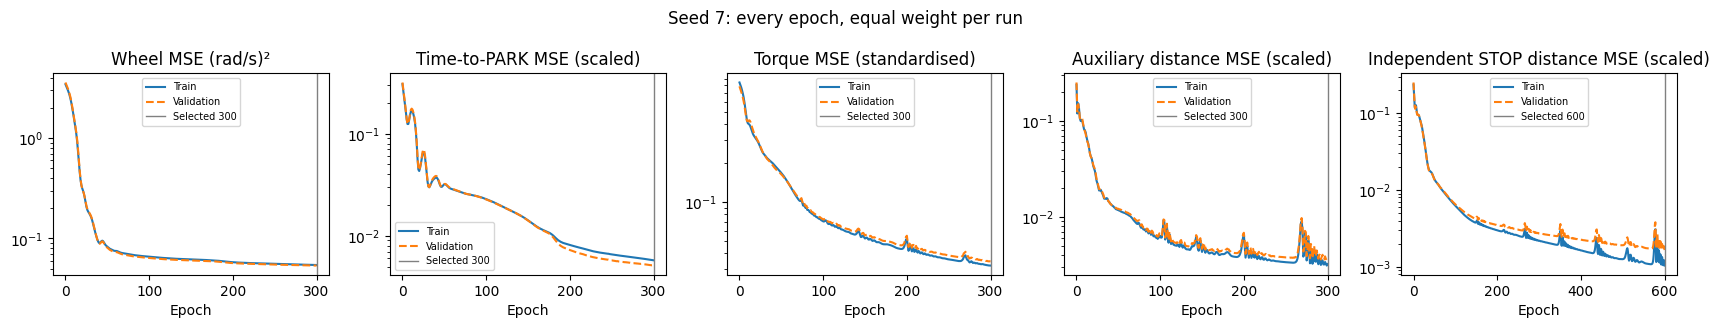

Original training histories, not retraining. Each checkpoint was selected on its own total offline validation loss. Test outcomes are not per-epoch losses.


In [3]:
tc.losses(tc_name);plt.show()
print('Original training histories, not retraining. Each checkpoint was selected on its own total offline validation loss. Test outcomes are not per-epoch losses.')

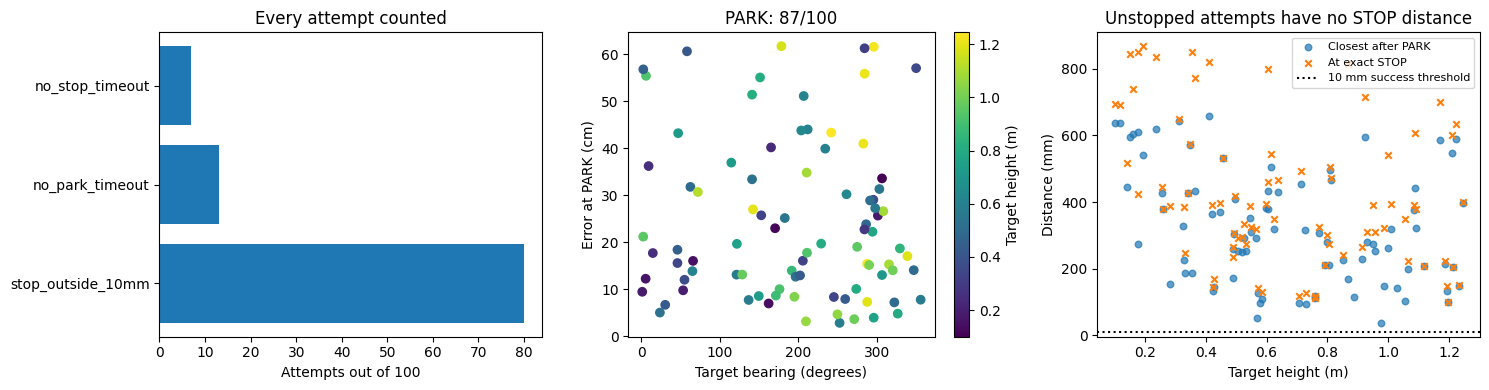

,status,success,parked,park_s,stop_s,park_error_cm,park_heading_error_deg,at_stop_mm,closest_mm,end_mm,post_stop_drift_mm,post_park_base_drift_cm,timed_out,elapsed_s,camera_visible_fraction,target_bearing_deg,target_range_m,target_height_m
dot,,,,,,,,,,,,,,,,,,
11,stop_outside_10mm,False,True,7.300,8.209,9.457,-19.981,851.396,609.565,1206.087,354.691,19.944,False,14.483,0.981,0.986,1.042,0.178
17,no_stop_timeout,False,True,9.800,NaN,8.392,12.901,NaN,143.235,467.269,NaN,0.475,True,20.435,0.457,194.926,1.095,1.028
33,stop_outside_10mm,False,True,8.233,9.315,7.915,-3.808,145.074,133.293,159.635,14.561,0.473,False,17.250,0.610,259.736,1.504,0.422
35,no_park_timeout,False,False,NaN,NaN,NaN,NaN,NaN,NaN,646.831,NaN,NaN,True,18.142,0.172,111.687,1.257,0.589
40,stop_outside_10mm,False,True,9.133,11.212,16.066,-6.532,386.621,227.368,501.949,115.328,0.645,False,19.145,0.656,205.751,1.041,0.328
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
958,stop_outside_10mm,False,True,8.167,9.100,14.062,-9.365,307.620,303.136,377.175,69.554,0.377,False,15.661,0.941,347.116,1.181,0.493
981,stop_outside_10mm,False,True,6.733,7.442,27.246,16.481,318.659,293.535,298.304,-20.354,0.446,False,14.533,0.933,297.945,1.569,0.564
985,stop_outside_10mm,False,True,4.000,5.831,55.881,19.196,600.571,547.746,673.881,73.310,1.099,False,12.964,0.789,284.446,1.417,1.210


,attempts,PARK,STOP,success_10mm,median_park_cm,median_STOP_mm
initially_visible,,,,,,
False,53,40,33,0,18.39,347.98
True,47,47,47,0,18.68,392.34


In [4]:
tc_report=tc.select(tc_name)
tc_report.outcomes(7);plt.show()
display(tc_report.table(7).round(3))
# Compare the initially visible validation setting with blind starts in this full test.
tc_raw=json.loads((tc.ROOT/tc_name/'seed7.json').read_text())
tc_visible={r['dot']:r['frames'][0]['visible'] if r['frames'] else None for r in tc_raw}
tc_strata=tc_report.table(7).copy();tc_strata['initially_visible']=tc_strata.index.map(tc_visible)
display(tc_strata.groupby('initially_visible',dropna=False).agg(attempts=('parked','size'),PARK=('parked','sum'),STOP=('stop_s',lambda x:x.notna().sum()),success_10mm=('success','sum'),median_park_cm=('park_error_cm','median'),median_STOP_mm=('at_stop_mm','median')).round(2))


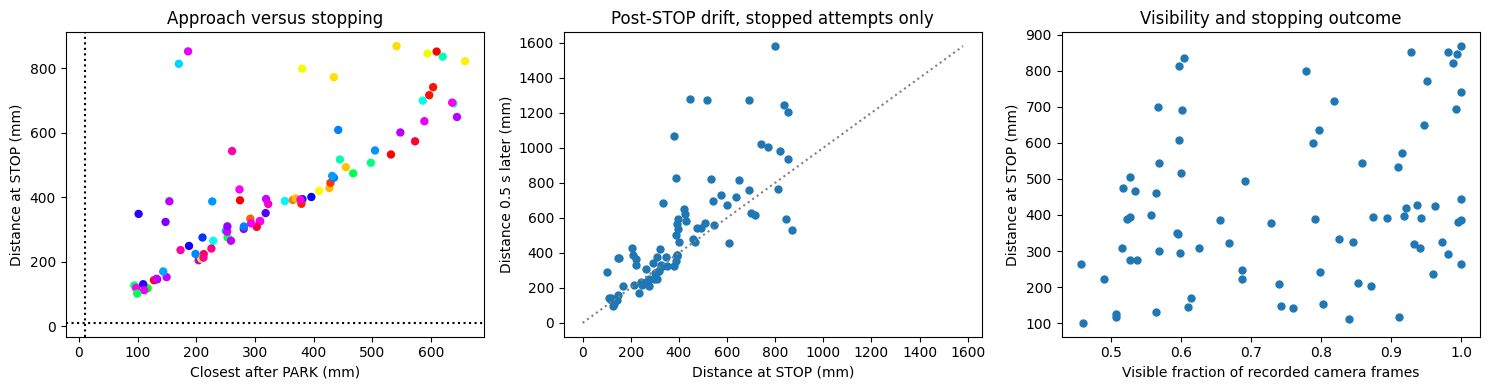

Medians for PARK and STOP exclude missing events. The success denominator retains all 100 attempts. Closest approach is not the STOP error.


In [5]:
tc_report.stopping(7);plt.show()
print('Medians for PARK and STOP exclude missing events. The success denominator retains all 100 attempts. Closest approach is not the STOP error.')

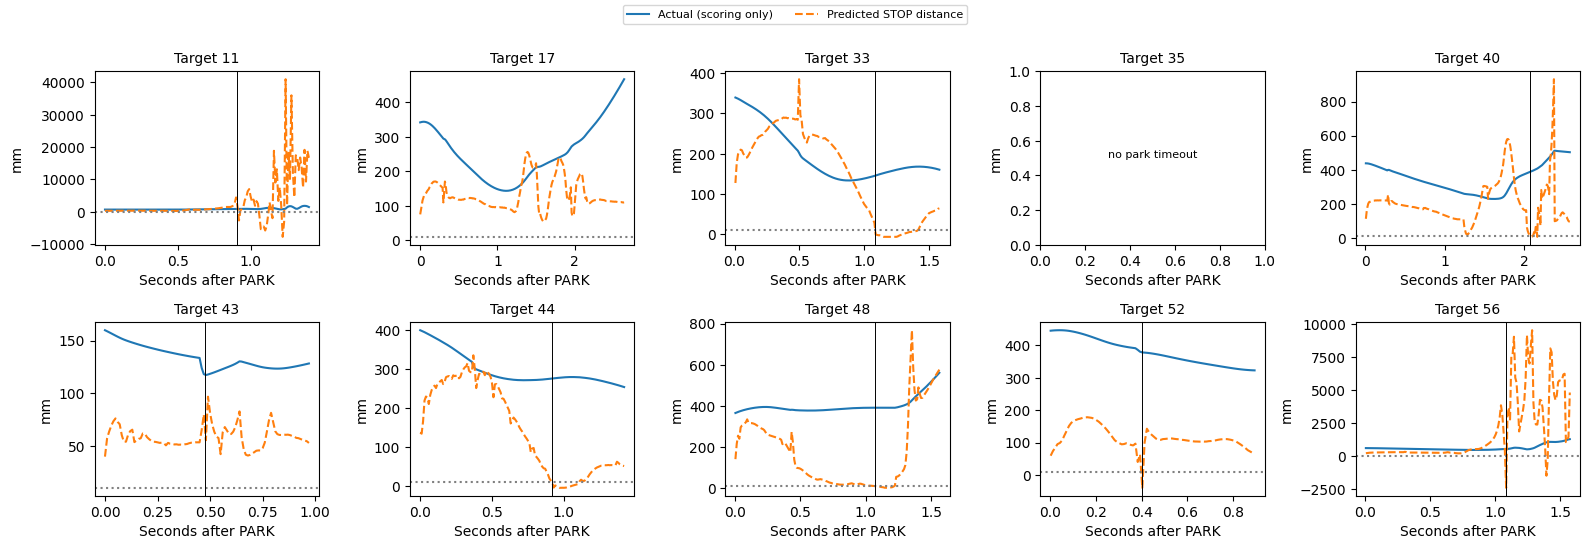

First ten test IDs in manifest order, selected independently of outcomes. Every recorded attempt is available in the player below.


In [6]:
tc_report.distances(7);plt.show()
print('First ten test IDs in manifest order, selected independently of outcomes. Every recorded attempt is available in the player below.')

In [7]:
tc_url=tc.player_url(tc_name)
display(lazy_player(tc_url))
display(HTML(f'<a href="{tc_url}" target="_blank">Open all 100 test runs with ghost expert and camera</a>'))
print('Select a target, then Play / Pause / Restart. Camera previews load on demand; the model used the full-resolution sensor. No simulation rerun is needed.')

Select a target, then Play / Pause / Restart. Camera previews load on demand; the model used the full-resolution sensor. No simulation rerun is needed.


In [8]:
display(Markdown(tc.reading(tc_name)))

Iteration 37: 87/100 PARK, 80/100 STOP, 0/100 within 10 mm at STOP. Median park error 18.7 cm among parked attempts; median distance at STOP 387.5 mm among stopped attempts. 0 execution/termination failures. Missing PARK or STOP remains a failed full task. Closest distance includes the 0.5-second observation after STOP. These are the same seed-7 checkpoints previously checked on six validation targets. The test targets were previously evaluated for baseline iterations 34 to 36, so this is a subsequent frozen comparison, not a new blind test.

### Iteration 38: cumulative time-to-PARK no-speed


In [9]:
tc_name='no_speed'
tc_report=tc.select(tc_name)
tc_config=json.loads((tc.ROOT/tc_name/'config.json').read_text())
display(pd.DataFrame([tc_report.score(7)]).round(2))
print('Driving inputs:',tc_config['drive_inputs'],'; arm hidden width:',tc_config['arm_hidden'])
print('PARK: predicted time <= 0.25 s. Arm STOP: predicted gripper distance <= 1 cm. Same thresholds as the validation checks.')
for kind in ['driving','torque','stop']:
    chosen=json.loads((tc.ROOT/tc_name/'models'/f'{kind}_seed7_summary.json').read_text())
    print(kind,': selected epoch',chosen['selected_epoch'],'; original training rows',chosen['train_rows'],'; validation rows',chosen['val_rows'])

,seed,attempts,parked,stopped,success_10mm,success_percent,wilson95_low_percent,wilson95_high_percent,median_park_error_cm,median_abs_heading_error_deg,median_closest_mm,median_stop_mm,median_park_s,median_stop_s,timeouts,execution_failures,sum_case_wall_s,median_case_wall_s
0,7,100,100,92,0,0.0,0.0,3.7,5.6,2.68,52.5,298.47,7.25,9.09,8,0,1730.96,17.39


Driving inputs: 11 ; arm hidden width: 64
PARK: predicted time <= 0.25 s. Arm STOP: predicted gripper distance <= 1 cm. Same thresholds as the validation checks.
driving : selected epoch 299 ; original training rows 25928 ; validation rows 26428
torque : selected epoch 300 ; original training rows 295084 ; validation rows 288818
stop : selected epoch 600 ; original training rows 295084 ; validation rows 288818


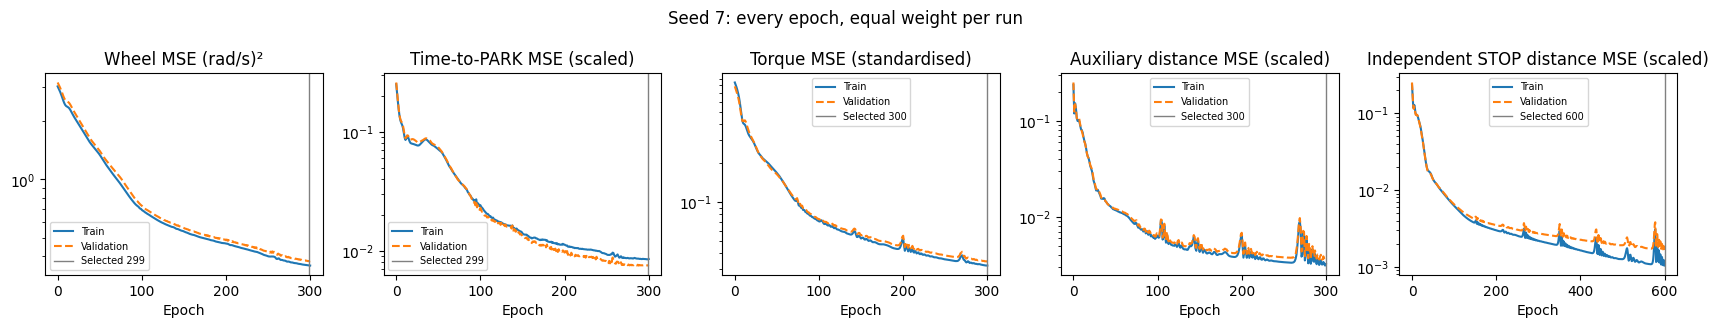

Original training histories, not retraining. Each checkpoint was selected on its own total offline validation loss. Test outcomes are not per-epoch losses.


In [10]:
tc.losses(tc_name);plt.show()
print('Original training histories, not retraining. Each checkpoint was selected on its own total offline validation loss. Test outcomes are not per-epoch losses.')

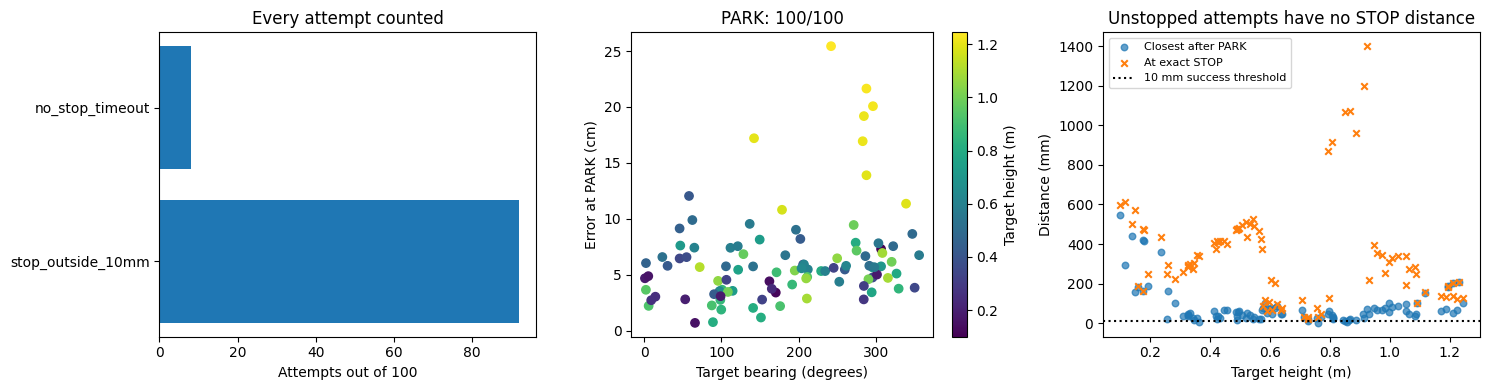

,status,success,parked,park_s,stop_s,park_error_cm,park_heading_error_deg,at_stop_mm,closest_mm,end_mm,post_stop_drift_mm,post_park_base_drift_cm,timed_out,elapsed_s,camera_visible_fraction,target_bearing_deg,target_range_m,target_height_m
dot,,,,,,,,,,,,,,,,,,
11,stop_outside_10mm,False,True,2.367,5.334,4.686,5.795,163.487,162.510,755.807,592.320,1.637,False,12.496,0.977,0.986,1.042,0.178
17,stop_outside_10mm,False,True,7.433,9.869,5.378,-1.436,341.118,86.602,429.422,88.304,1.122,False,18.639,0.481,194.926,1.095,1.028
33,stop_outside_10mm,False,True,8.000,10.741,5.468,-3.223,413.724,23.434,457.143,43.419,0.663,False,19.483,0.651,259.736,1.504,0.422
35,stop_outside_10mm,False,True,9.267,10.542,7.410,-4.816,60.226,49.622,104.039,43.813,0.380,False,18.277,0.614,111.687,1.257,0.589
40,stop_outside_10mm,False,True,6.700,9.269,5.912,-3.983,290.135,48.200,330.560,40.425,0.747,False,17.091,0.622,205.751,1.041,0.328
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
958,stop_outside_10mm,False,True,2.700,5.418,8.652,-0.769,476.189,59.128,524.373,48.183,0.458,False,12.679,0.618,347.116,1.181,0.493
981,stop_outside_10mm,False,True,6.000,8.543,5.680,-1.510,467.917,22.171,527.228,59.310,0.702,False,16.857,0.695,297.945,1.569,0.564
985,stop_outside_10mm,False,True,5.667,7.046,19.183,-0.560,136.551,52.977,429.389,292.838,0.433,False,14.140,0.833,284.446,1.417,1.210


,attempts,PARK,STOP,success_10mm,median_park_cm,median_STOP_mm
initially_visible,,,,,,
False,53,53,45,0,5.33,290.14
True,47,47,47,0,5.81,311.08


In [11]:
tc_report=tc.select(tc_name)
tc_report.outcomes(7);plt.show()
display(tc_report.table(7).round(3))
# Compare the initially visible validation setting with blind starts in this full test.
tc_raw=json.loads((tc.ROOT/tc_name/'seed7.json').read_text())
tc_visible={r['dot']:r['frames'][0]['visible'] if r['frames'] else None for r in tc_raw}
tc_strata=tc_report.table(7).copy();tc_strata['initially_visible']=tc_strata.index.map(tc_visible)
display(tc_strata.groupby('initially_visible',dropna=False).agg(attempts=('parked','size'),PARK=('parked','sum'),STOP=('stop_s',lambda x:x.notna().sum()),success_10mm=('success','sum'),median_park_cm=('park_error_cm','median'),median_STOP_mm=('at_stop_mm','median')).round(2))


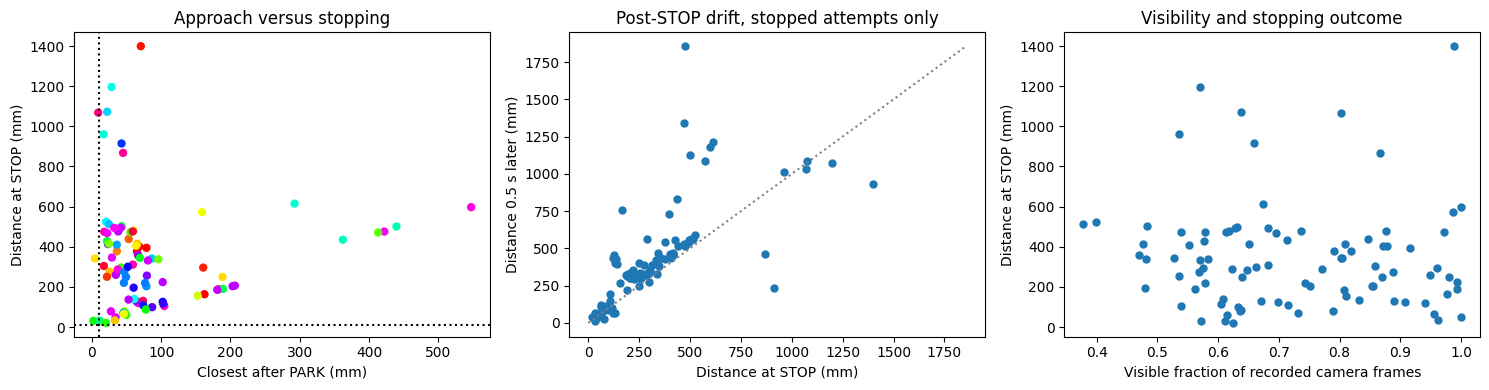

Medians for PARK and STOP exclude missing events. The success denominator retains all 100 attempts. Closest approach is not the STOP error.


In [12]:
tc_report.stopping(7);plt.show()
print('Medians for PARK and STOP exclude missing events. The success denominator retains all 100 attempts. Closest approach is not the STOP error.')

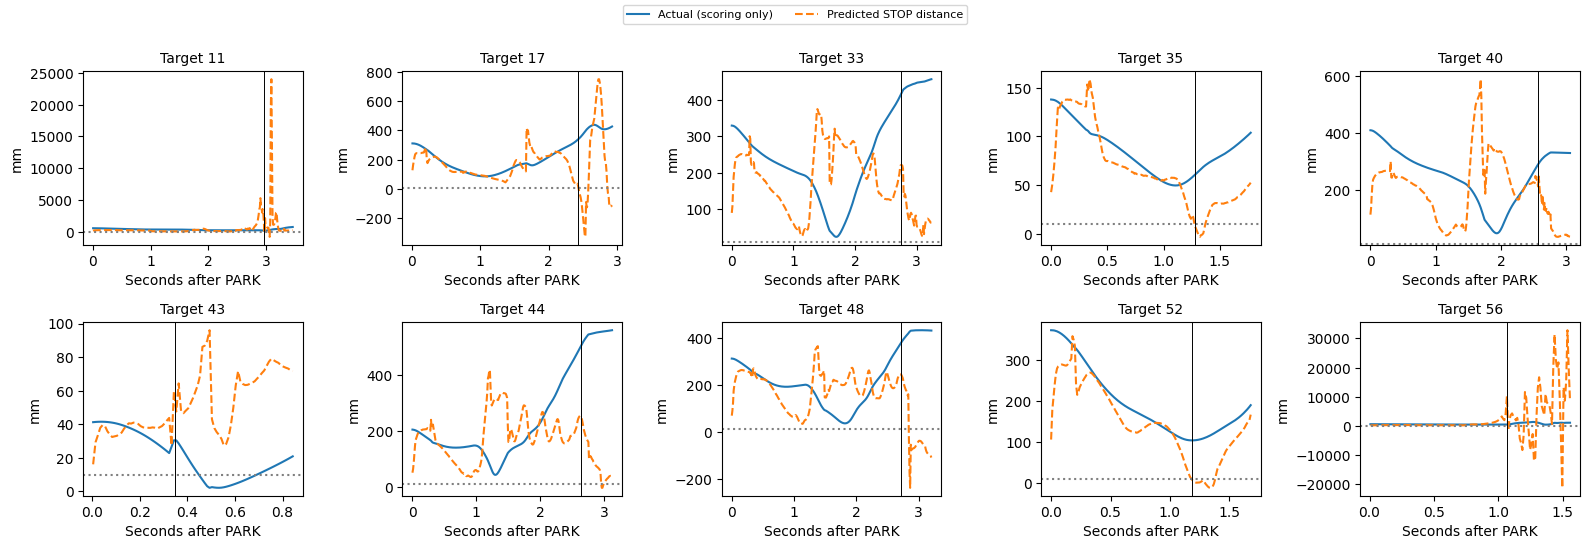

First ten test IDs in manifest order, selected independently of outcomes. Every recorded attempt is available in the player below.


In [13]:
tc_report.distances(7);plt.show()
print('First ten test IDs in manifest order, selected independently of outcomes. Every recorded attempt is available in the player below.')

In [14]:
tc_url=tc.player_url(tc_name)
display(lazy_player(tc_url))
display(HTML(f'<a href="{tc_url}" target="_blank">Open all 100 test runs with ghost expert and camera</a>'))
print('Select a target, then Play / Pause / Restart. Camera previews load on demand; the model used the full-resolution sensor. No simulation rerun is needed.')

Select a target, then Play / Pause / Restart. Camera previews load on demand; the model used the full-resolution sensor. No simulation rerun is needed.


In [15]:
display(Markdown(tc.reading(tc_name)))

Iteration 38: 100/100 PARK, 92/100 STOP, 0/100 within 10 mm at STOP. Median park error 5.6 cm among parked attempts; median distance at STOP 298.5 mm among stopped attempts. 0 execution/termination failures. Missing PARK or STOP remains a failed full task. Closest distance includes the 0.5-second observation after STOP. These are the same seed-7 checkpoints previously checked on six validation targets. The test targets were previously evaluated for baseline iterations 34 to 36, so this is a subsequent frozen comparison, not a new blind test.

### Iteration 39: cumulative time-to-PARK longer-arm


In [16]:
tc_name='longer_arm'
tc_report=tc.select(tc_name)
tc_config=json.loads((tc.ROOT/tc_name/'config.json').read_text())
display(pd.DataFrame([tc_report.score(7)]).round(2))
print('Driving inputs:',tc_config['drive_inputs'],'; arm hidden width:',tc_config['arm_hidden'])
print('PARK: predicted time <= 0.25 s. Arm STOP: predicted gripper distance <= 1 cm. Same thresholds as the validation checks.')
for kind in ['driving','torque','stop']:
    chosen=json.loads((tc.ROOT/tc_name/'models'/f'{kind}_seed7_summary.json').read_text())
    print(kind,': selected epoch',chosen['selected_epoch'],'; original training rows',chosen['train_rows'],'; validation rows',chosen['val_rows'])

,seed,attempts,parked,stopped,success_10mm,success_percent,wilson95_low_percent,wilson95_high_percent,median_park_error_cm,median_abs_heading_error_deg,median_closest_mm,median_stop_mm,median_park_s,median_stop_s,timeouts,execution_failures,sum_case_wall_s,median_case_wall_s
0,7,100,100,98,0,0.0,0.0,3.7,5.6,2.68,98.26,193.65,7.25,8.65,2,0,1617.47,16.06


Driving inputs: 11 ; arm hidden width: 64
PARK: predicted time <= 0.25 s. Arm STOP: predicted gripper distance <= 1 cm. Same thresholds as the validation checks.
driving : selected epoch 299 ; original training rows 25928 ; validation rows 26428
torque : selected epoch 1200 ; original training rows 295084 ; validation rows 288818
stop : selected epoch 600 ; original training rows 295084 ; validation rows 288818


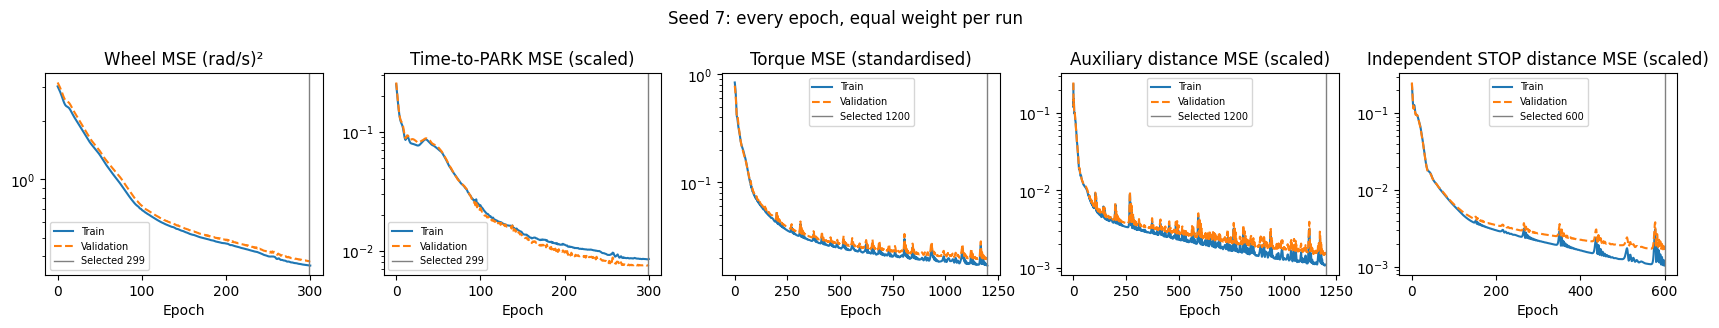

Original training histories, not retraining. Each checkpoint was selected on its own total offline validation loss. Test outcomes are not per-epoch losses.


In [17]:
tc.losses(tc_name);plt.show()
print('Original training histories, not retraining. Each checkpoint was selected on its own total offline validation loss. Test outcomes are not per-epoch losses.')

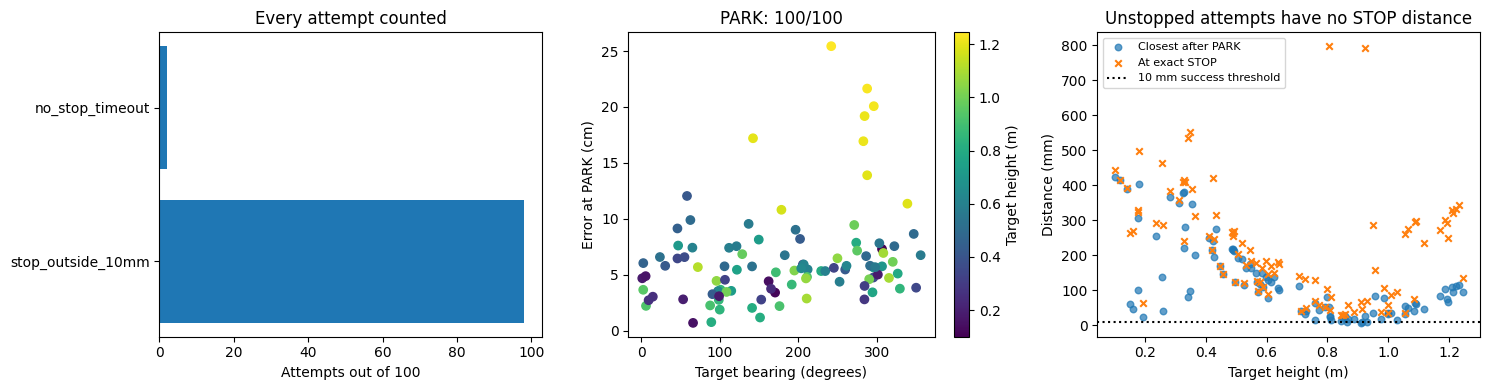

,status,success,parked,park_s,stop_s,park_error_cm,park_heading_error_deg,at_stop_mm,closest_mm,end_mm,post_stop_drift_mm,post_park_base_drift_cm,timed_out,elapsed_s,camera_visible_fraction,target_bearing_deg,target_range_m,target_height_m
dot,,,,,,,,,,,,,,,,,,
11,stop_outside_10mm,False,True,2.367,5.075,4.686,5.795,329.847,101.648,282.760,-47.087,0.801,False,12.254,0.935,0.986,1.042,0.178
17,stop_outside_10mm,False,True,7.433,8.608,5.378,-1.436,93.517,16.121,318.906,225.389,0.550,False,16.054,0.449,194.926,1.095,1.028
33,stop_outside_10mm,False,True,8.000,11.874,5.468,-3.223,421.502,242.010,500.625,79.123,1.152,False,21.482,0.788,259.736,1.504,0.422
35,stop_outside_10mm,False,True,9.267,9.850,7.410,-4.816,110.561,108.131,152.304,41.743,0.244,False,17.297,0.588,111.687,1.257,0.589
40,stop_outside_10mm,False,True,6.700,7.371,5.912,-3.983,413.771,380.606,406.988,-6.783,0.229,False,13.924,0.603,205.751,1.041,0.328
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
958,stop_outside_10mm,False,True,2.700,3.305,8.652,-0.769,268.486,211.872,357.932,89.447,0.131,False,9.051,0.870,347.116,1.181,0.493
981,stop_outside_10mm,False,True,6.000,6.616,5.680,-1.510,177.698,148.453,264.633,86.935,0.205,False,13.658,0.748,297.945,1.569,0.564
985,stop_outside_10mm,False,True,5.667,7.378,19.183,-0.560,328.622,109.144,672.899,344.277,2.535,False,15.123,0.869,284.446,1.417,1.210


,attempts,PARK,STOP,success_10mm,median_park_cm,median_STOP_mm
initially_visible,,,,,,
False,53,53,51,0,5.33,164.54
True,47,47,47,0,5.81,262.99


In [18]:
tc_report=tc.select(tc_name)
tc_report.outcomes(7);plt.show()
display(tc_report.table(7).round(3))
# Compare the initially visible validation setting with blind starts in this full test.
tc_raw=json.loads((tc.ROOT/tc_name/'seed7.json').read_text())
tc_visible={r['dot']:r['frames'][0]['visible'] if r['frames'] else None for r in tc_raw}
tc_strata=tc_report.table(7).copy();tc_strata['initially_visible']=tc_strata.index.map(tc_visible)
display(tc_strata.groupby('initially_visible',dropna=False).agg(attempts=('parked','size'),PARK=('parked','sum'),STOP=('stop_s',lambda x:x.notna().sum()),success_10mm=('success','sum'),median_park_cm=('park_error_cm','median'),median_STOP_mm=('at_stop_mm','median')).round(2))


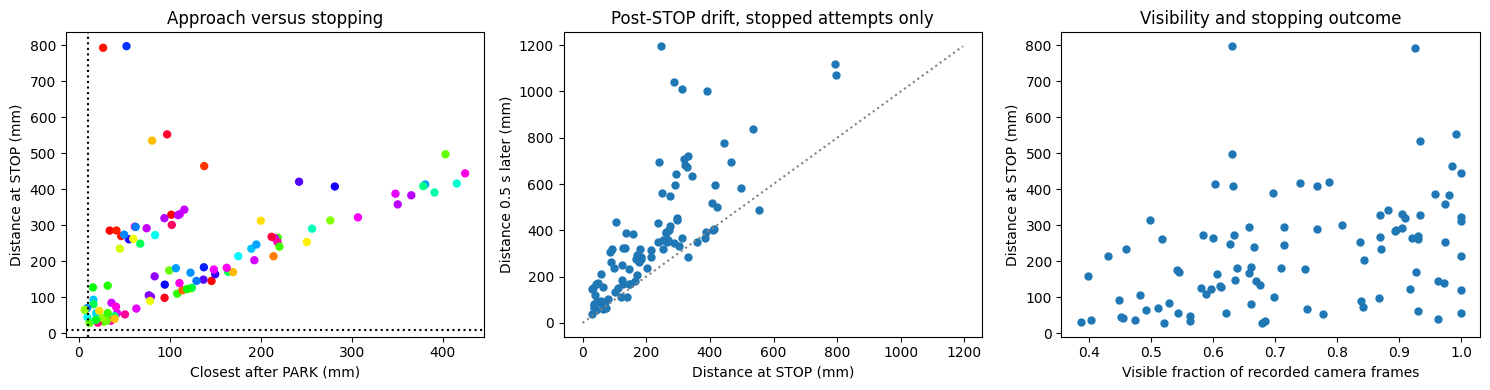

Medians for PARK and STOP exclude missing events. The success denominator retains all 100 attempts. Closest approach is not the STOP error.


In [19]:
tc_report.stopping(7);plt.show()
print('Medians for PARK and STOP exclude missing events. The success denominator retains all 100 attempts. Closest approach is not the STOP error.')

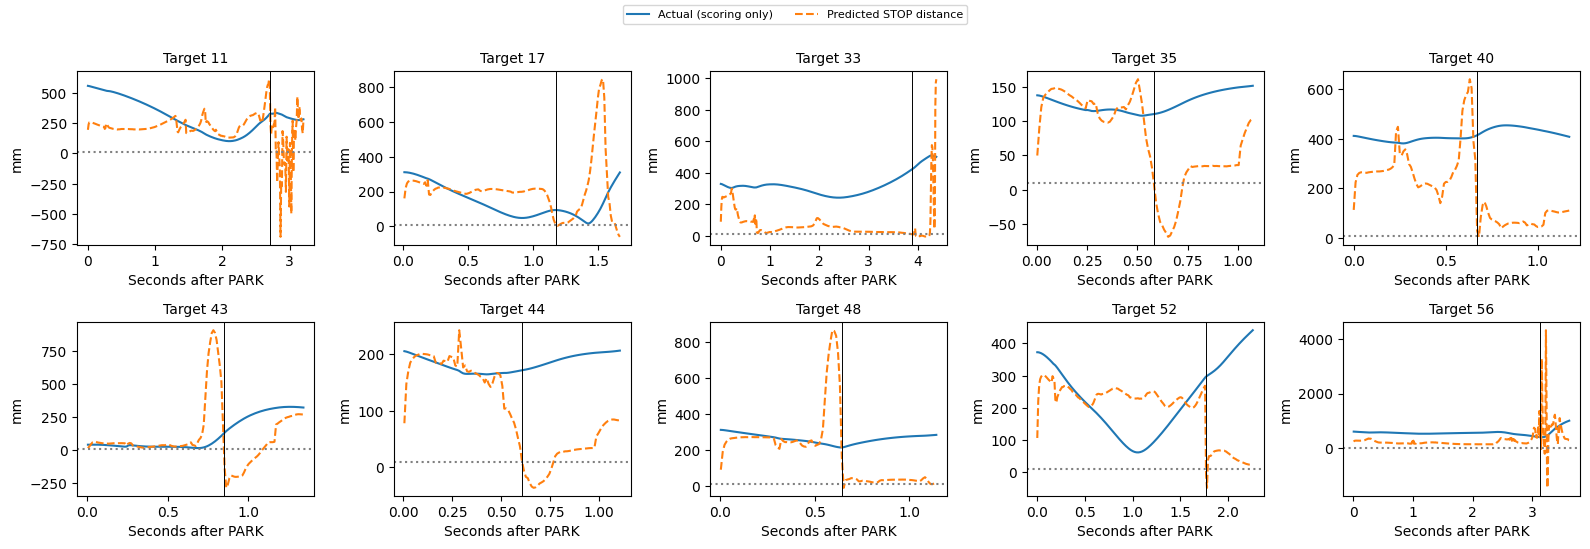

First ten test IDs in manifest order, selected independently of outcomes. Every recorded attempt is available in the player below.


In [20]:
tc_report.distances(7);plt.show()
print('First ten test IDs in manifest order, selected independently of outcomes. Every recorded attempt is available in the player below.')

In [21]:
tc_url=tc.player_url(tc_name)
display(lazy_player(tc_url))
display(HTML(f'<a href="{tc_url}" target="_blank">Open all 100 test runs with ghost expert and camera</a>'))
print('Select a target, then Play / Pause / Restart. Camera previews load on demand; the model used the full-resolution sensor. No simulation rerun is needed.')

Select a target, then Play / Pause / Restart. Camera previews load on demand; the model used the full-resolution sensor. No simulation rerun is needed.


In [22]:
display(Markdown(tc.reading(tc_name)))

Iteration 39: 100/100 PARK, 98/100 STOP, 0/100 within 10 mm at STOP. Median park error 5.6 cm among parked attempts; median distance at STOP 193.7 mm among stopped attempts. 0 execution/termination failures. Missing PARK or STOP remains a failed full task. Closest distance includes the 0.5-second observation after STOP. These are the same seed-7 checkpoints previously checked on six validation targets. The test targets were previously evaluated for baseline iterations 34 to 36, so this is a subsequent frozen comparison, not a new blind test.

### Iteration 40: cumulative time-to-PARK wider-arm


In [23]:
tc_name='wider_arm'
tc_report=tc.select(tc_name)
tc_config=json.loads((tc.ROOT/tc_name/'config.json').read_text())
display(pd.DataFrame([tc_report.score(7)]).round(2))
print('Driving inputs:',tc_config['drive_inputs'],'; arm hidden width:',tc_config['arm_hidden'])
print('PARK: predicted time <= 0.25 s. Arm STOP: predicted gripper distance <= 1 cm. Same thresholds as the validation checks.')
for kind in ['driving','torque','stop']:
    chosen=json.loads((tc.ROOT/tc_name/'models'/f'{kind}_seed7_summary.json').read_text())
    print(kind,': selected epoch',chosen['selected_epoch'],'; original training rows',chosen['train_rows'],'; validation rows',chosen['val_rows'])

,seed,attempts,parked,stopped,success_10mm,success_percent,wilson95_low_percent,wilson95_high_percent,median_park_error_cm,median_abs_heading_error_deg,median_closest_mm,median_stop_mm,median_park_s,median_stop_s,timeouts,execution_failures,sum_case_wall_s,median_case_wall_s
0,7,100,100,96,2,2.0,0.55,7.0,5.6,2.68,59.14,85.22,7.25,9.01,4,0,1676.07,16.94


Driving inputs: 11 ; arm hidden width: 128
PARK: predicted time <= 0.25 s. Arm STOP: predicted gripper distance <= 1 cm. Same thresholds as the validation checks.
driving : selected epoch 299 ; original training rows 25928 ; validation rows 26428
torque : selected epoch 1171 ; original training rows 295084 ; validation rows 288818
stop : selected epoch 600 ; original training rows 295084 ; validation rows 288818


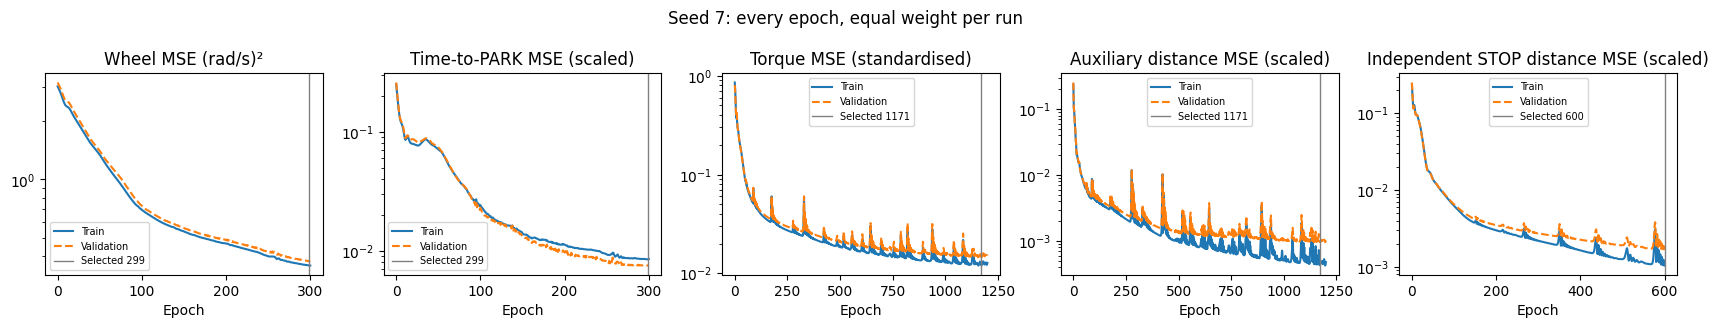

Original training histories, not retraining. Each checkpoint was selected on its own total offline validation loss. Test outcomes are not per-epoch losses.


In [24]:
tc.losses(tc_name);plt.show()
print('Original training histories, not retraining. Each checkpoint was selected on its own total offline validation loss. Test outcomes are not per-epoch losses.')

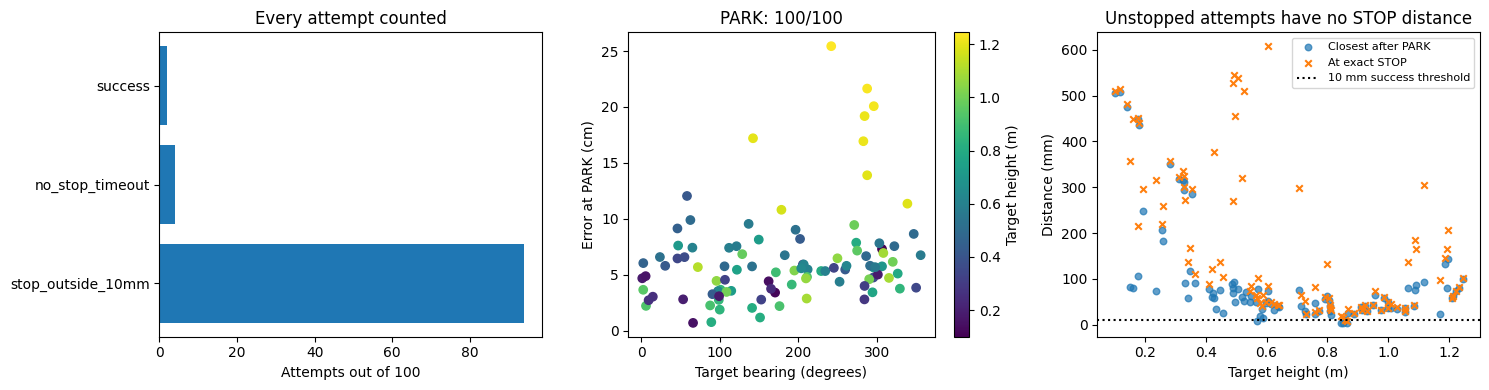

,status,success,parked,park_s,stop_s,park_error_cm,park_heading_error_deg,at_stop_mm,closest_mm,end_mm,post_stop_drift_mm,post_park_base_drift_cm,timed_out,elapsed_s,camera_visible_fraction,target_bearing_deg,target_range_m,target_height_m
dot,,,,,,,,,,,,,,,,,,
11,stop_outside_10mm,False,True,2.367,5.704,4.686,5.795,215.296,105.927,160.560,-54.737,0.743,False,13.155,1.000,0.986,1.042,0.178
17,stop_outside_10mm,False,True,7.433,9.013,5.378,-1.436,39.483,34.144,34.512,-4.971,0.482,False,16.938,0.371,194.926,1.095,1.028
33,no_stop_timeout,False,True,8.000,NaN,5.468,-3.223,NaN,68.413,455.206,NaN,1.592,True,21.917,0.758,259.736,1.504,0.422
35,stop_outside_10mm,False,True,9.267,10.039,7.410,-4.816,65.173,14.693,34.106,-31.067,0.267,False,17.371,0.596,111.687,1.257,0.589
40,stop_outside_10mm,False,True,6.700,7.783,5.912,-3.983,323.405,311.244,380.312,56.907,0.338,False,14.602,0.598,205.751,1.041,0.328
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
958,stop_outside_10mm,False,True,2.700,6.972,8.652,-0.769,544.676,94.096,932.996,388.320,2.232,False,14.965,0.924,347.116,1.181,0.493
981,stop_outside_10mm,False,True,6.000,6.653,5.680,-1.510,65.377,50.283,65.884,0.506,0.209,False,13.762,0.786,297.945,1.569,0.564
985,stop_outside_10mm,False,True,5.667,7.353,19.183,-0.560,58.440,58.309,82.933,24.493,0.492,False,15.069,0.873,284.446,1.417,1.210


,attempts,PARK,STOP,success_10mm,median_park_cm,median_STOP_mm
initially_visible,,,,,,
False,53,53,49,2,5.33,49.98
True,47,47,47,0,5.81,137.81


In [25]:
tc_report=tc.select(tc_name)
tc_report.outcomes(7);plt.show()
display(tc_report.table(7).round(3))
# Compare the initially visible validation setting with blind starts in this full test.
tc_raw=json.loads((tc.ROOT/tc_name/'seed7.json').read_text())
tc_visible={r['dot']:r['frames'][0]['visible'] if r['frames'] else None for r in tc_raw}
tc_strata=tc_report.table(7).copy();tc_strata['initially_visible']=tc_strata.index.map(tc_visible)
display(tc_strata.groupby('initially_visible',dropna=False).agg(attempts=('parked','size'),PARK=('parked','sum'),STOP=('stop_s',lambda x:x.notna().sum()),success_10mm=('success','sum'),median_park_cm=('park_error_cm','median'),median_STOP_mm=('at_stop_mm','median')).round(2))


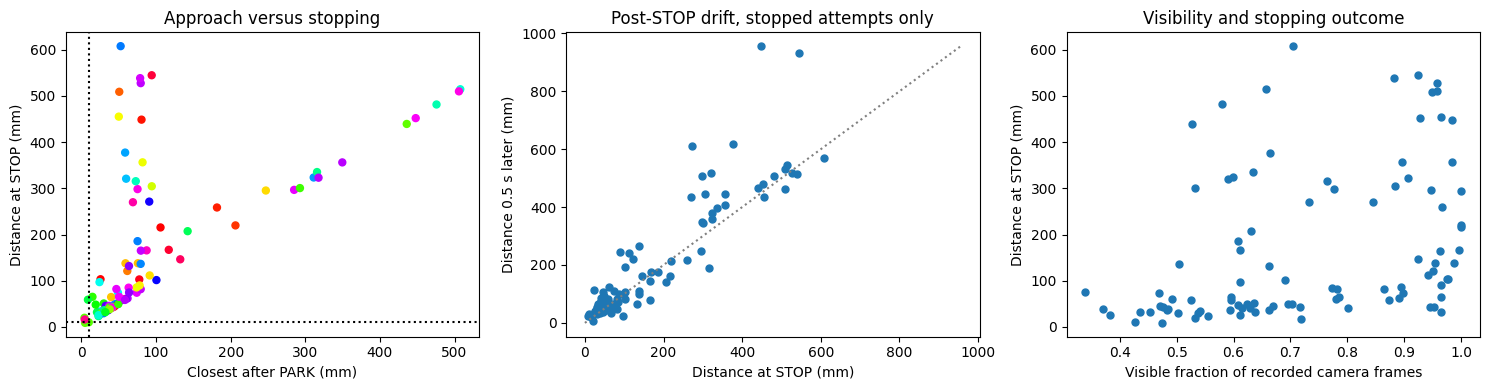

Medians for PARK and STOP exclude missing events. The success denominator retains all 100 attempts. Closest approach is not the STOP error.


In [26]:
tc_report.stopping(7);plt.show()
print('Medians for PARK and STOP exclude missing events. The success denominator retains all 100 attempts. Closest approach is not the STOP error.')

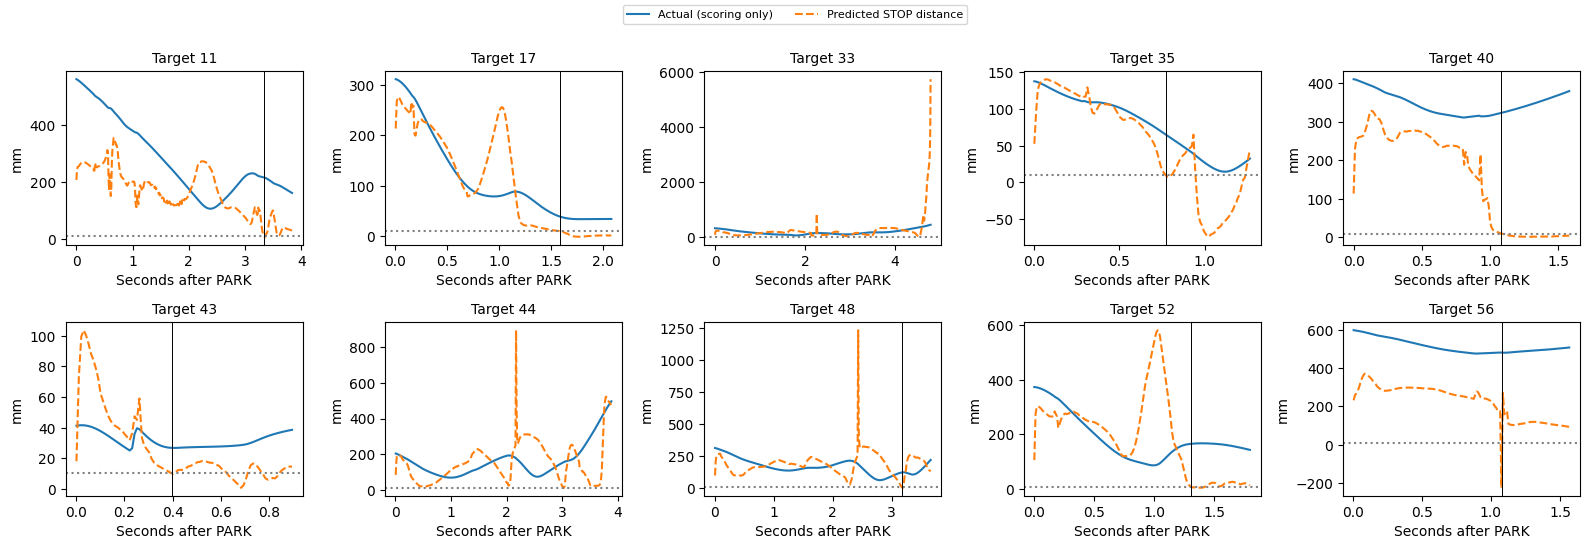

First ten test IDs in manifest order, selected independently of outcomes. Every recorded attempt is available in the player below.


In [27]:
tc_report.distances(7);plt.show()
print('First ten test IDs in manifest order, selected independently of outcomes. Every recorded attempt is available in the player below.')

In [28]:
tc_url=tc.player_url(tc_name)
display(lazy_player(tc_url))
display(HTML(f'<a href="{tc_url}" target="_blank">Open all 100 test runs with ghost expert and camera</a>'))
print('Select a target, then Play / Pause / Restart. Camera previews load on demand; the model used the full-resolution sensor. No simulation rerun is needed.')

Select a target, then Play / Pause / Restart. Camera previews load on demand; the model used the full-resolution sensor. No simulation rerun is needed.


In [29]:
display(Markdown(tc.reading(tc_name)))

Iteration 40: 100/100 PARK, 96/100 STOP, 2/100 within 10 mm at STOP. Median park error 5.6 cm among parked attempts; median distance at STOP 85.2 mm among stopped attempts. 0 execution/termination failures. Missing PARK or STOP remains a failed full task. Closest distance includes the 0.5-second observation after STOP. These are the same seed-7 checkpoints previously checked on six validation targets. The test targets were previously evaluated for baseline iterations 34 to 36, so this is a subsequent frozen comparison, not a new blind test.

### Reading the four full time-to-PARK evaluations

Compare each row to the preceding configuration. The first two change driving inputs; the last two retain the same driving checkpoint and change only arm torque training. The independent arm STOP checkpoint is unchanged throughout. The four configurations were fixed before this evaluation, from the six-case validation development work.

All 100 bearings, ranges and heights are included, including initially invisible targets. The earlier six validation targets were initially visible, so the full results can differ substantially. No fixed search policy has been added. Report the full success rate and failures alongside conditional parking and reaching errors; neither a low median nor passing close to the target establishes successful stopping.

This is one seed per configuration. These test targets had already been evaluated in iterations 34 to 36, so the results should be described as a subsequent frozen comparison. Do not treat them as a fresh untouched test or use them to choose epochs. The distance-PARK experiments remain separate and unchanged.


### Full-episode arm training and cumulative robustness: plan

We are replacing the native pre-PARK holding controller with learned arm torque control from reset. Mint hosts execution, notebook, camera recordings and MLflow. No Powerglide availability is assumed.

## Frozen baseline plan: tickets 11109 and 11110

Seed 7. Keep iteration 40's driving weights unchanged. Train the arm from scratch on all rows in the 100 golden training episodes, including the pre-PARK expert holding commands. Fit outputs on training rows only and select epochs using the 100 validation trajectories. Arm inputs: seven counted joint angles, seven finite-difference encoder speeds, three camera/tracker coordinates and the current PARK flag. At deployment PARK comes from the driving network, never the expert. Torque network 18 -> 128 -> 128 -> 7, with its existing auxiliary distance objective; independent STOP 18 -> 32 -> 16 -> 1. ReLU, FP32, Adam 0.01, 1,200 torque epochs and 600 STOP epochs, validation-selected checkpoints. The camera remains at 30 Hz; learned arm torques run at 1 kHz from the first tick. No PD or added gravity compensation. STOP is only actionable after PARK and learned torques continue during the 0.5 s observation.

Prediction: including pre-PARK rows should produce nonzero learned holding torques and prevent immediate arm collapse. It may still fail because the expert's holding trajectories cover few deviations. That failure is evidence for recovery data, not permission to restore the conventional controller. Preflight on validation only: verify no hidden hold, nonzero learned torque before PARK, finite trajectories, own phase input and recorded command timing. Then all 100 validation and 100 test cases, with all failures counted. Existing test targets have been viewed before; results are subsequent comparisons, not an untouched generalisation test.

## Cumulative queue

1. 11111: encoder angle noise before counting, standard deviation 0.0001 rad; derive velocities from consecutive noisy counts. Verify course sampling semantics.
2. 11112: retain noise; add mass-matrix-scaled damping, c=1 /s.
3. 11113: retain preceding effects; add elasticity, k=1 /s².
4. 11114: retain preceding effects; add previous-acceleration motor correction, J=0.001 kg m².
5. 11115: retain ladder; add causal observation latency, starting with the 3 ms course setting.
6. 11116: retain effects; random starting poses. Collect 100/100/100 new expert references and render train/validation. Compare fixed and retrained models.
7. 11117: retain preceding setup; remove a declared window of prepared training rows around PARK and retrain. Preserve sensor history when masking.
8. 11120, 11121, 11122: compare DART-inspired augmentation, DAgger alone, and DART followed by DAgger, on clean and the cumulative condition. DAgger uses training targets only, with a stateful expert and recorded internal reference. Never invent time-to-PARK labels on student trajectories.

Each frozen condition receives 100 validation and 100 test full episodes. Test outcomes are reporting only. Occlusion 11118 and direct weight editing 11123 are deferred. The old independent-lens stack definition in 11119 is superseded by Nat's cumulative instruction.

## If a stage deteriorates

Check implementation, causal timestamps and phase coverage first. Compare physical versus training-derived scaling, relevant input ablations, and bounded training durations on validation, one change at a time. Record every attempted variant and failed result. Do not weaken effects or select epochs from test outcomes. If those checks do not restore a usable model, branch to recovery learning from the last usable stage, retaining the complete failed cumulative branch. No search rule, PPO, arbitrary weight perturbations, new URDF inputs or conventional arm hold may be introduced.

## Status

Preparation in progress. No new training or evaluation has completed yet. Access to Powerglide failed; Nat explicitly authorised Mint instead. Running improvements list and stage status must distinguish planned, running, checked and published work.


### Iteration 41: full-episode baseline

Learned arm torques from reset; frozen driving checkpoint; seed 7. This is the complete 100-target test comparison, with the separate 100-target validation results alongside it. The prior plan and the previous notebook results are retained above.


In [1]:
from pathlib import Path
import sys,json,uuid
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,HTML
sys.path.insert(0,str(Path('../arm').resolve()))
import report_curriculum as overnight
def lazy_player(url,height=850):
    k=uuid.uuid4().hex[:8]
    return HTML(f"<div><button onclick=\"var f=document.getElementById('player{k}');f.src='{url}';f.style.display='block';this.style.display='none'\" style=\"padding:8px 14px\">Load the 3D player</button><iframe id=\"player{k}\" style=\"display:none;width:100%;height:{height}px;border:0\"></iframe></div>")

full_name='baseline'
display(overnight.build(full_name).round(3))
print('Validation and test are distinct. No fitting occurs in these analysis cells.')

,seed,attempts,parked,stopped,success_10mm,success_percent,wilson95_low_percent,wilson95_high_percent,median_park_error_cm,median_abs_heading_error_deg,median_closest_mm,median_stop_mm,median_park_s,median_stop_s,timeouts,execution_failures,sum_case_wall_s,median_case_wall_s
split,,,,,,,,,,,,,,,,,,
val,7,100,100,90,0,0.0,0.0,3.699,5.540,3.480,210.965,363.322,7.767,10.359,10,0,2014.635,20.845
test,7,100,100,84,0,0.0,0.0,3.699,5.466,2.883,184.482,272.659,7.267,9.518,16,0,2642.071,27.080


Validation and test are distinct. No fitting occurs in these analysis cells.


In [2]:
full_config=json.loads((overnight.ROOT/full_name/'test/config.json').read_text())
display(full_config)
for kind in ('driving','torque','stop'):
    chosen=json.loads((overnight.models(full_name)/f'{kind}_seed7_summary.json').read_text())
    print(kind, 'selected epoch',chosen['selected_epoch'],'validation loss',chosen['selected_val_loss'])

{'cases': [11,
  17,
  33,
  35,
  40,
  43,
  44,
  48,
  52,
  56,
  65,
  83,
  92,
  97,
  98,
  113,
  136,
  147,
  148,
  154,
  162,
  196,
  221,
  229,
  232,
  239,
  248,
  260,
  271,
  274,
  277,
  281,
  285,
  302,
  306,
  311,
  315,
  316,
  317,
  361,
  413,
  427,
  432,
  463,
  478,
  479,
  492,
  502,
  534,
  545,
  554,
  571,
  585,
  586,
  592,
  599,
  600,
  605,
  628,
  632,
  642,
  646,
  652,
  653,
  664,
  669,
  671,
  683,
  693,
  700,
  707,
  708,
  722,
  729,
  730,
  738,
  741,
  750,
  770,
  779,
  806,
  834,
  845,
  846,
  848,
  854,
  857,
  859,
  872,
  883,
  898,
  903,
  905,
  945,
  952,
  958,
  981,
  985,
  986,
  989],
 'split': 'test',
 'seed': 7,
 'jobs': 4,
 'models': '/media/nm/Fast Drive/comp0245-golden11109/overnight_20261105/baseline/models',
 'model_hashes': {'driving_seed7.npz': '458fc825c3d3c1e5d39d3630655eb872bb46f3ddc34e0a850ee4eb5da52a18c3',
  'reaching_seed7.npz': '774c961608ec707c4ec9124ea13a66c180dd06be

driving selected epoch 299 validation loss 0.38417819142341614
torque selected epoch 1198 validation loss 0.02170979417860508
stop selected epoch 593 validation loss 0.0030433654319494963


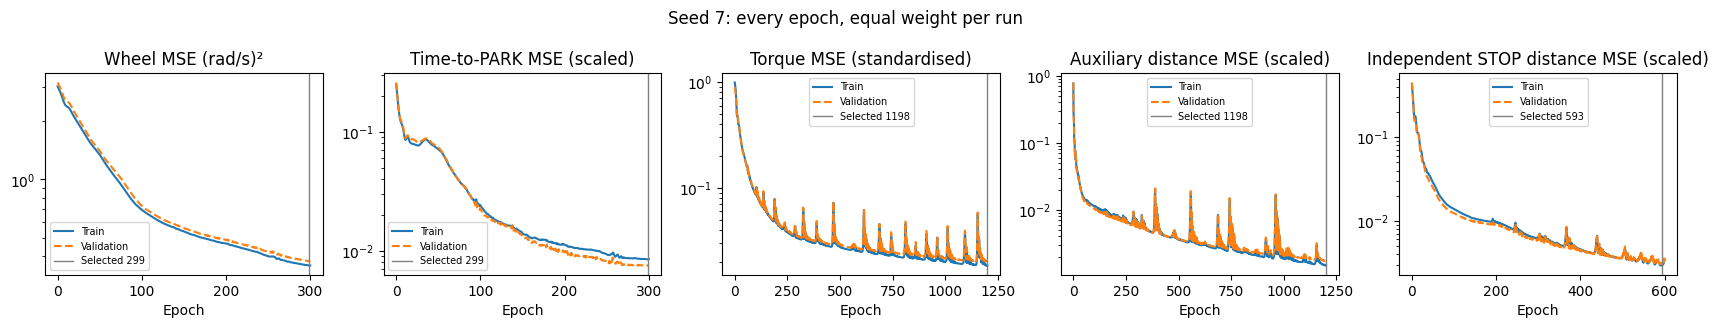

All training and validation epochs. Test scores are not training losses.


In [3]:
overnight.losses(full_name);plt.show()
print('All training and validation epochs. Test scores are not training losses.')

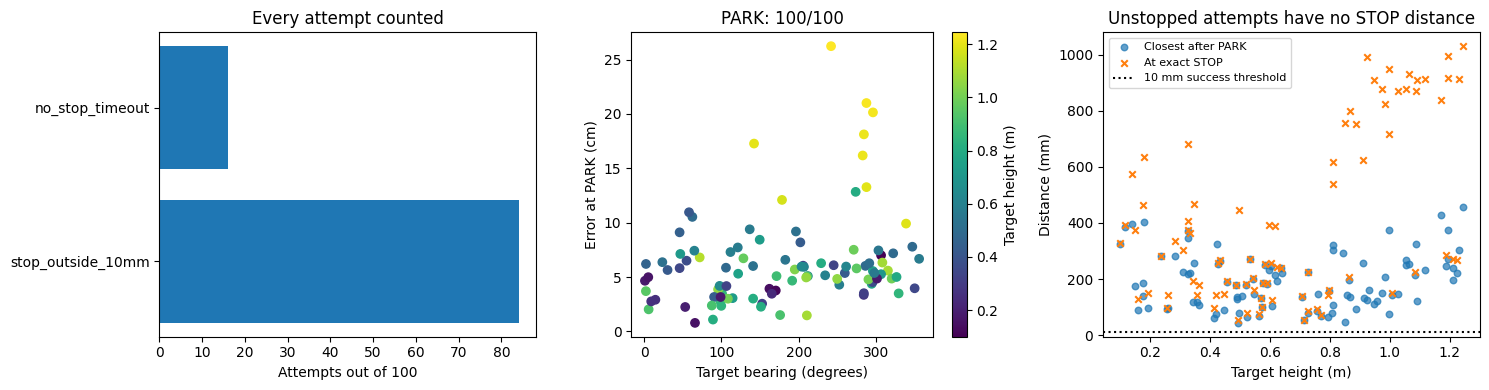

,status,success,parked,park_s,stop_s,park_error_cm,park_heading_error_deg,at_stop_mm,closest_mm,end_mm,post_stop_drift_mm,post_park_base_drift_cm,timed_out,elapsed_s,camera_visible_fraction,target_bearing_deg,target_range_m,target_height_m
dot,,,,,,,,,,,,,,,,,,
11,stop_outside_10mm,False,True,2.367,9.390,4.659,5.756,462.869,140.451,175.516,-287.353,2.609,False,18.002,1.000,0.986,1.042,0.178
17,stop_outside_10mm,False,True,7.200,10.257,5.697,-1.310,871.741,144.980,933.348,61.607,0.800,False,20.128,0.563,194.926,1.095,1.028
33,no_stop_timeout,False,True,7.933,NaN,5.371,-2.922,NaN,326.069,526.569,NaN,1.178,True,23.295,0.844,259.736,1.504,0.422
35,stop_outside_10mm,False,True,9.000,9.513,7.301,-5.080,184.191,183.045,365.099,180.908,0.274,False,18.682,0.412,111.687,1.257,0.589
40,stop_outside_10mm,False,True,6.667,9.522,6.046,-3.826,408.490,219.166,490.918,82.428,0.870,False,18.827,0.522,205.751,1.041,0.328
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
958,stop_outside_10mm,False,True,3.100,5.734,7.790,-0.700,55.732,43.749,51.406,-4.326,0.801,False,18.572,0.957,347.116,1.181,0.493
981,stop_outside_10mm,False,True,5.767,6.857,5.376,-1.345,75.236,67.657,67.649,-7.588,0.372,False,20.523,0.787,297.945,1.569,0.564
985,stop_outside_10mm,False,True,5.900,8.304,18.121,-0.511,273.016,239.508,350.240,77.224,0.717,False,23.401,0.721,284.446,1.417,1.210


In [4]:
full_report=overnight.select(full_name)
full_report.outcomes(7);plt.show()
display(full_report.table(7).round(3))

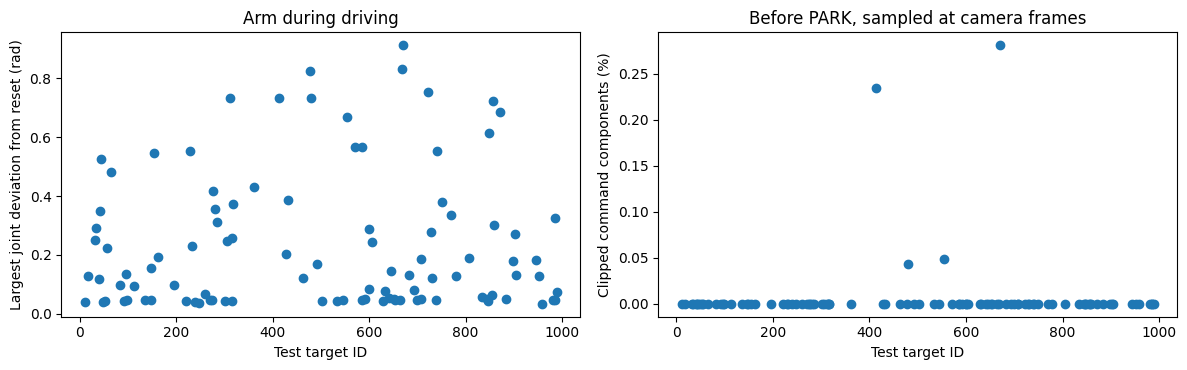

,status,prepark_frames,max_arm_deviation_rad,maximum_command_Nm,torque_clipped_fraction
dot,,,,,
11,stop_outside_10mm,71,0.0411,18.9615,0.0
17,stop_outside_10mm,216,0.1273,19.9673,0.0
33,no_stop_timeout,238,0.2511,20.0724,0.0
35,stop_outside_10mm,270,0.2909,19.9673,0.0
40,stop_outside_10mm,200,0.1185,19.9673,0.0
...,...,...,...,...,...
958,stop_outside_10mm,93,0.0341,20.3467,0.0
981,stop_outside_10mm,173,0.0467,20.6663,0.0
985,stop_outside_10mm,177,0.0486,21.1418,0.0


Learned torques are applied from reset. No expert holding or added gravity term.


In [5]:
overnight.holding(full_name);plt.show()
display(overnight.hold_table(full_name).round(4))
print('Learned torques are applied from reset. No expert holding or added gravity term.')

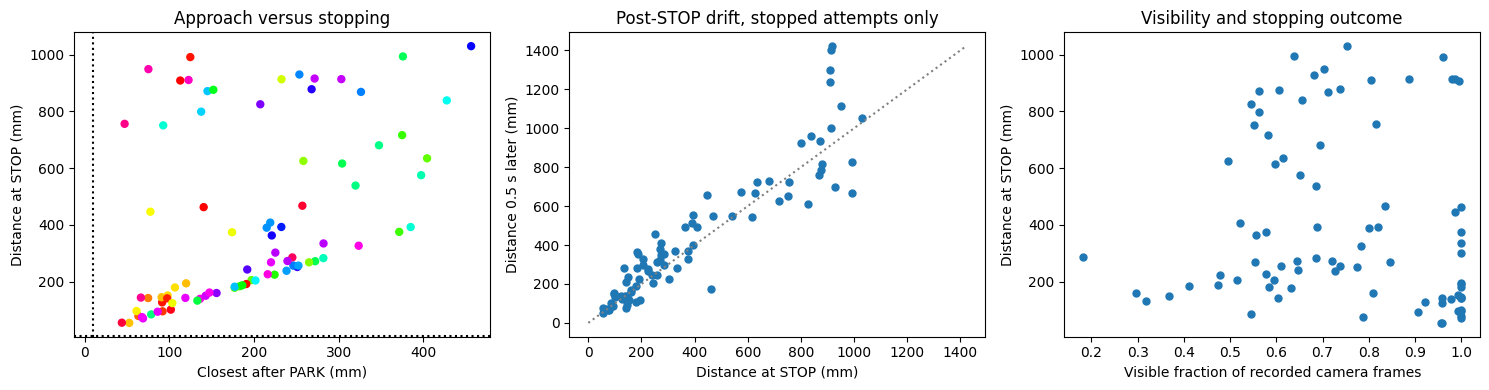

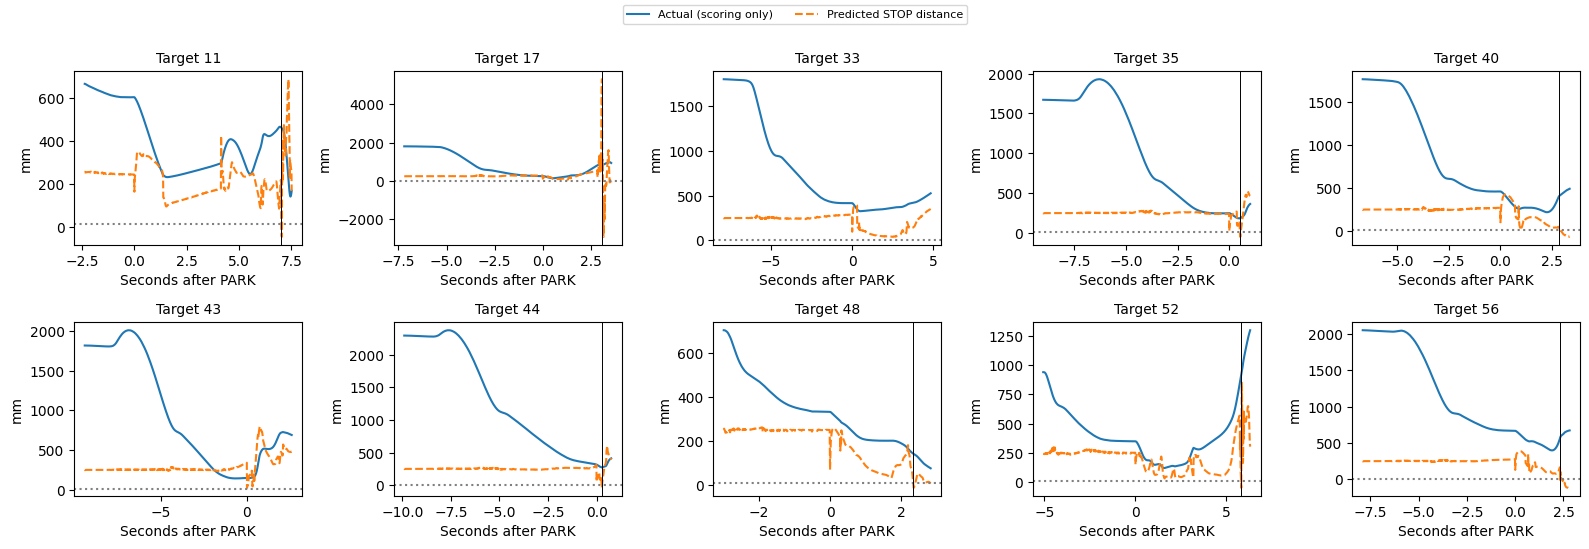

Closest approach, exact STOP, and 0.5-second drift are different measurements.


In [6]:
full_report=overnight.select(full_name)
full_report.stopping(7);plt.show()
full_report.distances(7);plt.show()
print('Closest approach, exact STOP, and 0.5-second drift are different measurements.')

In [7]:
full_url=overnight.player_url(full_name)
display(lazy_player(full_url))
display(HTML(f'<a href="{full_url}" target="_blank">Open all 100 test replays</a>'))
print('Wheel encoder speeds, wheel commands, PARK and STOP values, applied arm torques, camera and ghost.')

Wheel encoder speeds, wheel commands, PARK and STOP values, applied arm torques, camera and ghost.


In [8]:
display(Markdown(overnight.reading(full_name)))

Both networks controlled the complete run, including learned arm torques before PARK. On validation, 100/100 parked and 0/100 met the full task criterion. On the frozen test comparison, 100/100 parked, 84/100 issued STOP, and 0/100 were within 10 mm at STOP. Median parking error among parked attempts was 5.5 cm; median distance at STOP among stopped attempts was 272.7 mm. Median maximum pre-PARK joint deviation was 0.131 rad. The 0.5 s after STOP is observed with learned torques still active, not a frozen simulation. These are previously viewed test targets and one seed; this is a frozen subsequent comparison, not an untouched estimate of generalisation. All timeouts and failures remain in the denominator.